# Tuning one four-wave-mixing tone: Rabi oscillation |2,g,0⟩ ⇄ |3,f,0⟩

**Purpose.** PReSPA (Shirol et al., PRX 16, 021042 (2026)) corrects a lost photon in two stages. Stage 1 uses a
four-wave-mixing (FWM) tone to add a photon to the storage while moving the transmon from $|g\rangle$ to $|f\rangle$:
$|n{-}1,g,0\rangle \to |n,f,0\rangle$, through the operator $\hat a^\dagger \hat q^{\dagger 2}$. Here we switch on **one** such tone,
tuned to the $n = 3$ path, start in $|2,g,0\rangle$, and watch the system swap back and forth with $|3,f,0\rangle$ (a Rabi
oscillation). We sweep the pump strength and find the rough range in which the system cleanly swaps between those
**two** states and nothing else.

**Same model as `dissipation_grape.ipynb`.** Same chip (Shirol Table I, `AQEC/device.py`), same drift Hamiltonian
(`DGRAPE.model.drift_hamiltonian`, higher-order terms on, as in training), same frame (rotating at the linear mode
frequencies), same space: storage × transmon (g, e, f) × readout (m = 0, 1). State labels are $|n, j, m\rangle$ =
(storage photons, transmon level, readout photons).

**Scope.** §1–§6 treat a closed system (no loss, no dephasing), and the drive term is the fourth-order, rotating-wave (RWA) result of
the paper's App. C, including the ac Stark shifts it brings. With three transmon levels, a start in one Fock state is
then *exactly* a two-level problem. So in this model the two-state picture fails in two ways only, and both are
measured below (§5, Fig. 2; also Fig. A1 in Appendix A):

1. **Stark detuning.** The pump shifts the transition away from the tone, so the swap becomes incomplete.
2. **Crosstalk.** The same tone also drives the *neighbouring* paths $|n{-}1,g,0\rangle \to |n,f,0\rangle$ with
   $n \ne 3$. They are off resonance by $\pm\chi_{gf}$, but at strong pumping they move population anyway. These are the
   "unwanted corrections" of the paper's App. E.2.

§7 adds the chip's dissipation (a Lindblad master equation with the decay rates of Shirol Table I), which brings a
third (§3 sets up both simulations side by side):

3. **Dissipation.** Photon loss and transmon decay damp the swap and move population out of the pair into many
   other states ("mixing", §7.2). This sets a lower limit on the pump strength (§7.3).

§8 pushes the pump up to $\beta = 0.3$, where $\Omega_1 \approx 4\chi_{gf}$. There failure mode 2 takes over: from a
superposition of neighbouring photon numbers, the tone no longer picks one path but swaps three at once, and the
transfer becomes a multi-frequency beat.

§10 turns to stage 2, the **comb-2** tone $|3,f,0\rangle \to |3,g,1\rangle$ through $\hat q^2\hat r^\dagger$, followed by
the readout's leak to $|3,g,0\rangle$. It is simulated with dissipation only, since the leak is what makes the step
one-way at weak pumping; it repeats the photon-number heat map, the pump sweep and the strong-pump crosstalk study for it.

Leakage into higher transmon levels and non-RWA effects are outside this model (§8 estimates the first).

In [1]:
import os
import sys

REPO_ROOT = os.path.abspath(".")
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp
from IPython.display import display

from AQEC import device as dev
from DGRAPE.model import drift_hamiltonian, operators, index, dim, collapse_ops, monomial
from DGRAPE.model import rates as dgrape_rates
from AQEC.master_equation import collapse_operators as aqec_collapse_operators
from AQEC.master_equation import jump_rates as aqec_jump_rates

# Apple's Accelerate BLAS raises spurious divide/overflow warnings on ordinary complex
# matmuls (no actual NaN/Inf; see core/grape_core.py). Silence them for the whole notebook.
np.seterr(divide="ignore", over="ignore", invalid="ignore")

TWO_PI = 2 * np.pi
N_C = 8             # storage Fock 0..7; the crosstalk starts below reach Fock 4
N_R = 2             # readout m = 0, 1 (as in DGRAPE)
G, E, F = 0, 1, 2
N_PATH = 3          # the tone is tuned to the n = 3 path: |2,g,0> -> |3,f,0>
os.makedirs("figures", exist_ok=True)


def tidy(ax, grid=True):
    # House style (aqec_experiments.ipynb): recessive grid, no top/right spines.
    if grid:
        ax.grid(color="0.9", lw=0.6)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


def mhz(w):
    return w / TWO_PI

# 1. Hamiltonian

## 1.1 Drift (identical to DGRAPE)

In the frame rotating at $\omega_a, \omega_q, \omega_r$ (`DGRAPE/model.py`, signs as in Shirol: $\alpha, \chi$ stored positive):

$$
\hat H_d = -\alpha|f\rangle\langle f| - \chi_{ge}|e\rangle\langle e|\,\hat n_a - \chi_{gf}|f\rangle\langle f|\,\hat n_a
- \chi_{qr}|e\rangle\langle e|\,\hat n_r - \tfrac{K}{2}\hat a^{\dagger2}\hat a^2 + \tfrac{\chi'_q}{2}\hat q^\dagger\hat q\,\hat a^{\dagger2}\hat a^2 .
$$

## 1.2 The FWM term (App. C)

The pump enters the transmon port at frequency $\omega_d$. App. C replaces it by a small classical displacement
$\beta$ (dimensionless) of the mode that reaches the junction. Expanding the junction cosine to fourth order gives one
term that turns a pump photon into one storage photon plus two transmon excitations:

$$
\hat H_{\rm FWM}(t) = g\,\beta\;\hat a^\dagger\hat q^{\dagger2}\,e^{i\Delta t} + \text{h.c.},
\qquad \Delta = \omega_a + 2\omega_q - \omega_d .
$$

We keep the full operator $\hat a^\dagger\hat q^{\dagger 2}$. It acts on every path $|n'{-}1,g\rangle\to|n',f\rangle$, not only
on $n' = 3$. On path $n$ its matrix element is $\langle n,f|\hat a^\dagger\hat q^{\dagger2}|n{-}1,g\rangle = \sqrt{2n}$, so the
rate is $\Omega_1 = g\beta\sqrt{2n}$.

**The coefficient $g$.** We take it from the paper's Eq. (C9), $\Omega_1 = \sqrt{n\,\chi_{ge}\,\Delta_{\rm Ss}}$ with Stark
shift $\Delta_{\rm Ss} = 2\alpha|\beta|^2$. That gives $g = \sqrt{\alpha\,\chi_{ge}}$ and, on the $n = 3$ path,

$$
\Omega_1 = \sqrt{6\,\alpha\,\chi_{ge}}\;\beta .
$$

This reproduces the paper's Table II: $\beta = 0.0033$ gives 57 kHz on $n = 1$, against 55 kHz fitted.
*Caveat:* counting the terms of the quartic expansion directly gives a coefficient $\sqrt2$ smaller,
$g = \sqrt{\alpha\chi_{ge}/2}$. We keep Eq. (C9) because it matches the measurement. Read every $\beta$ below with
that factor-$\sqrt2$ uncertainty in mind. A rate $\Omega_1$ is the safer quantity to carry over.

## 1.3 Stark shifts

The same expansion has terms with two pump factors, $|\beta|^2$. They do not oscillate, so they survive the RWA as
static frequency shifts:

$$
\hat H_S = -|\beta|^2\big(2\alpha\,\hat q^\dagger\hat q + \chi_{ge}\,\hat a^\dagger\hat a + \chi_{qr}\,\hat r^\dagger\hat r\big).
$$

On three levels, $\hat q^\dagger\hat q = 2$ on $|f\rangle$. So the $|2,g,0\rangle\to|3,f,0\rangle$ transition moves by
$\delta_S = -(4\alpha + \chi_{ge})|\beta|^2$. That shift grows like $\beta^2$, but $\Omega_1$ grows only like $\beta$, so
a tone left at the bare frequency falls off resonance at strong pumping. The paper corrects this by retuning the tone
(App. A.4). We simulate both choices.

In [2]:
ops = operators(N_C, N_R)
a, q, r = ops["a"], ops["q"], ops["r"]
ad, qd = a.conj().T, q.conj().T
A_FWM = ad @ qd @ qd                                  # a' q'^2, the FWM operator
H_D = drift_hamiltonian(N_C, N_R, include_higher_order=True)
E_D = np.real(np.diag(H_D))                           # H_d is diagonal

G_FWM = np.sqrt(dev.alpha_q * dev.chi_ge)             # Eq. (C9) convention, rad/us per unit beta
STARK_DIAG = -np.real(np.diag(2 * dev.alpha_q * qd @ q + dev.chi_ge * ops["n_a"]
                              + dev.chi_qr * ops["n_r"]))   # H_S / |beta|^2, diagonal

i0 = index(N_PATH - 1, G, 0, N_C, N_R)                # |2,g,0>, the start
i1 = index(N_PATH, F, 0, N_C, N_R)                    # |3,f,0>, the target


def omega_1(beta, n=N_PATH):
    # rate on path n (rad/us): g beta <n,f| a' q'^2 |n-1,g> = g beta sqrt(2n)
    return G_FWM * beta * np.sqrt(2 * n)


def stark_detuning(beta):
    # shift of the |2,g,0> -> |3,f,0> transition (rad/us)
    return (STARK_DIAG[i1] - STARK_DIAG[i0]) * beta ** 2


print(f"<3,f,0| a' q'^2 |2,g,0> = {A_FWM[i1, i0].real:.4f}   (sqrt 6 = {np.sqrt(6):.4f})")
print(f"Omega_1 / beta (n=3)        = {mhz(omega_1(1.0)):.2f} MHz  (sqrt(6 alpha chi_ge)/2pi)")
print(f"delta_S / beta^2            = {mhz(stark_detuning(1.0)):.1f} MHz  (-(4 alpha + chi_ge)/2pi = "
      f"{mhz(-(4 * dev.alpha_q + dev.chi_ge)):.1f})")

<3,f,0| a' q'^2 |2,g,0> = 2.4495   (sqrt 6 = 2.4495)
Omega_1 / beta (n=3)        = 30.04 MHz  (sqrt(6 alpha chi_ge)/2pi)
delta_S / beta^2            = -538.2 MHz  (-(4 alpha + chi_ge)/2pi = -538.2)


**Reading the output.**

- **Line 1, the matrix element of the pump operator:** $\hat a^\dagger\hat q^{\dagger 2}$ links $|2,g,0\rangle$ to $|3,f,0\rangle$ with weight $\sqrt3\cdot\sqrt2 = \sqrt6$, as §1.2 says.
- **Line 2, how fast the swap runs per unit of pump:** $\Omega_1/2\pi = 30.04\ \text{MHz} \times \beta$, e.g. 99 kHz at the paper's $\beta = 0.0033$.
- **Line 3, the Stark shift per unit of pump squared:** $\delta_S/2\pi = -538.2\ \text{MHz} \times \beta^2$, mostly the $-4\alpha$ shift of $|f\rangle$ (§1.3).

# 2. The drive frequency for $n = 3$

The tone is resonant when it supplies exactly the energy difference between the start $|2,g,0\rangle$ and the target
$|3,f,0\rangle$. Table 1 gives that frequency three times, each version including more physics than the one before:
the paper's formula, then the full DGRAPE drift, then the correction for the pump's own Stark shift. The last
column is each row's offset from the first, in kHz. The rows are explained below the table.

In [3]:
w_eq2 = dev.omega_a + dev.omega_gf - N_PATH * dev.chi_gf
dE_bare = E_D[i1] - E_D[i0]                       # target - start in the rotating frame (rad/us)
w_bare = dev.omega_a + 2 * dev.omega_q + dE_bare  # lab frequency of the bare tone
BETA_PAPER = 0.0033                                # PRX Table II, comb 1

rows = [
    ("Eq. (2): omega_a + omega_gf - 3 chi_gf", mhz(w_eq2), 0.0),
    ("bare tone (DGRAPE H_d, higher-order on)", mhz(w_bare), 1e3 * mhz(w_bare - w_eq2)),
    (f"Stark-compensated at beta = {BETA_PAPER}", mhz(w_bare + stark_detuning(BETA_PAPER)),
     1e3 * mhz(w_bare + stark_detuning(BETA_PAPER) - w_eq2)),
]
freq_table = pd.DataFrame(rows, columns=["tone", "omega_d / 2pi (MHz)", "offset from Eq. (2) (kHz)"])
display(freq_table.style.format({"omega_d / 2pi (MHz)": "{:.4f}", "offset from Eq. (2) (kHz)": "{:+.2f}"})
        .set_caption("Table 1. Drive frequency of the n = 3 tone |2,g,0> -> |3,f,0> at three levels of "
                     "modelling, and its offset from the paper's Eq. (2)."))

print(f"paper's beta = {BETA_PAPER}:  Omega_1/2pi = {1e3 * mhz(omega_1(BETA_PAPER)):.1f} kHz on n = 3, "
      f"{1e3 * mhz(omega_1(BETA_PAPER, 1)):.1f} kHz on n = 1 (paper: 57 estimated, 55 fitted)")
print(f"                      transmon Stark shift 2 alpha beta^2 / 2pi = "
      f"{1e3 * mhz(2 * dev.alpha_q * BETA_PAPER**2):.2f} kHz (paper: 3)")
print(f"                      transition shift delta_S / 2pi = {1e3 * mhz(stark_detuning(BETA_PAPER)):.2f} kHz")
assert abs(mhz(w_eq2) - 11483.21) < 0.01

,tone,omega_d / 2pi (MHz),offset from Eq. (2) (kHz)
0,Eq. (2): omega_a + omega_gf - 3 chi_gf,11483.2100,+0.00
1,"bare tone (DGRAPE H_d, higher-order on)",11483.2148,+4.80
2,Stark-compensated at beta = 0.0033,11483.2089,-1.06


paper's beta = 0.0033:  Omega_1/2pi = 99.1 kHz on n = 3, 57.2 kHz on n = 1 (paper: 57 estimated, 55 fitted)
                      transmon Stark shift 2 alpha beta^2 / 2pi = 2.92 kHz (paper: 3)
                      transition shift delta_S / 2pi = -5.86 kHz


## 2.1 Reading Table 1

**Row 1: the paper's formula, Eq. (2)** (11483.2100 MHz, offset 0).

$$
\omega_{d1,3} = \omega_a + \omega_{gf} - 3\chi_{gf}, \qquad \omega_{gf} = 2\omega_q - \alpha .
$$

The tone must pay for one storage photon ($\omega_a$) plus the transmon's $g \to f$ step ($\omega_{gf}$). With 3
photons in the storage, $f$ sits $3\chi_{gf}$ lower. Simplest model (no Kerr, no $\chi'_q$); this is the reference.

**Row 2: the bare tone** (+4.80 kHz). The same frequency, read off the full DGRAPE drift (`E_D[i1] - E_D[i0]`). Its
extra terms, Kerr and $\chi'_q$, shift the transition by $-2K + 6\chi'_q \approx +4.8$ kHz. "Bare" means not yet
corrected for the pump.

**Row 3: Stark-compensated at $\beta = 0.0033$** (−1.06 kHz). The pump itself shifts the transition by
$\delta_S = -538\ \text{MHz} \times \beta^2 = -5.86$ kHz (§1.3). Row 3 is row 2 moved to follow it:
+4.80 − 5.86 = −1.06 kHz. It depends on $\beta$, and it is what `simulate(..., compensate=True)` uses.

**What this means in practice.**

- All three rows agree to within about 6 kHz, while the swap rate is $\Omega_1/2\pi \approx 99$ kHz at the paper's
  $\beta$. So at that pump strength, the choice of row barely changes the swap.
- The Stark shift grows like $\beta^2$, but $\Omega_1$ grows only like $\beta$. So at strong pumping the gap between
  rows 2 and 3 starts to matter. That is why §4 and §5 run both tunings: "bare" (row 2) and "compensated" (row 3,
  recomputed at each $\beta$).

# 3. How the simulation works: closed and open

The notebook runs two simulations of the same model.

| | closed system | open system |
|---|---|---|
| what is tracked | the state vector $\psi$: 48 complex amplitudes | the density matrix $\hat\rho$: $48 \times 48$ entries |
| equation | Schrödinger, $i\dot\psi = \hat H\psi$ | Lindblad (§3.2) |
| physics included | the pump and every frequency shift | the same, plus photon loss and transmon decay |
| function | `simulate(beta, start, t, compensate)` | `simulate_open(beta, rho0, t, model, compensate)` |
| used in | §4–§6, §8 | §7 |

Both use the same Hamiltonian, frame (rotating at the linear mode frequencies), space and tone. The open simulation
only adds dissipation on top. This section builds the two side by side.

| subsection | goal |
|---|---|
| 3.1 | the Hamiltonian, term by term, and where each term lives in the code |
| 3.2 | dissipation: the master equation and its jump operators (open only) |
| 3.3 | the interaction picture for $\psi$ and for $\hat\rho$, so the solver follows only slow phases |
| 3.4 | why a Fock start is exactly a two-level problem (closed only), and its closed-form solution |
| 3.5 | the Python machinery: which line of code is which piece of physics |
| 3.6 | checks of both solvers |


## 3.1 The Hamiltonian that is integrated

The frame rotates at the linear mode frequencies $\omega_a, \omega_q, \omega_r$, as in §1. With one pump of
strength $\beta$ (real; its phase only relabels $|n,f\rangle$) at frequency $\omega_d$:

$$
\hat H(t) = \underbrace{\hat H_d + \hat H_S}_{\hat H_0\ \text{(diagonal)}}
\;+\; g\beta\left(\hat A\,e^{i\Delta t} + \hat A^\dagger e^{-i\Delta t}\right),
\qquad \hat A = \hat a^\dagger\hat q^{\dagger 2},\qquad \Delta = \omega_a + 2\omega_q - \omega_d .
$$

$\hat H_d$ is the drift of §1.1 (Kerr and $\chi'_q$ on), $\hat H_S$ the Stark shifts of §1.3, and the last term the
FWM coupling of §1.2. The phase $e^{i\Delta t}$ is what is left of the pump's $e^{-i\omega_d t}$ once
$\hat a^\dagger$ and $\hat q^{\dagger2}$ carry the frame's $e^{i(\omega_a + 2\omega_q)t}$.

**Tuning the tone.** The tone is set on resonance with the $n = 3$ path, i.e. $\Delta = -(E_{3f0} - E_{2g0})$,
where $E_i$ are the diagonal entries of a static Hamiltonian. The two tunings differ only in which one:

- **bare**: $E = \mathrm{diag}\,\hat H_d$, the same for every $\beta$ (Table 1, row 2);
- **compensated**: $E = \mathrm{diag}(\hat H_d + \hat H_S)$, recomputed at each $\beta$ (Table 1, row 3).

The bare tone is therefore off resonance by the Stark shift $\delta_S = -(4\alpha + \chi_{ge})\beta^2$ of §1.3.

**Table 2.** The terms of $\hat H(t)$ and where they are built.

| symbol | definition | code |
|:-:|---|---|
| $\hat H_d$ | drift, §1.1, diagonal | `H_D = drift_hamiltonian(N_C, N_R, include_higher_order=True)`; diagonal `E_D` |
| $\hat H_S/\beta^2$ | Stark shifts per unit $\beta^2$, §1.3, diagonal | `STARK_DIAG` |
| $g$ | FWM coefficient $\sqrt{\alpha\chi_{ge}}$ (Eq. C9 convention) | `G_FWM` |
| $\hat A$ | $\hat a^\dagger\hat q^{\dagger2}$ on the full space | `A_FWM` |
| $\lvert 2,g,0\rangle,\ \lvert 3,f,0\rangle$ | start and target | indices `i0`, `i1` |
| $\Omega_1(n)$ | $g\beta\sqrt{2n}$, the coupling on path $n$ | `omega_1(beta, n)` |
| $\delta_S$ | $(\hat H_S)_{3f0} - (\hat H_S)_{2g0}$ | `stark_detuning(beta)` |
| $\Delta$ | $-(E_{3f0} - E_{2g0})$ for the chosen tuning | `Delta` inside `simulate` |

## 3.2 Dissipation: the master equation (open system only)

**Why a density matrix.** A state vector describes a system we know completely. Once a photon *may* have leaked out,
at a time we do not know, we no longer know the state. We only know the odds of each possibility, and the density
matrix $\hat\rho$ holds exactly that:

- its diagonal entries $\rho_{ii}$ are the **populations**, the probability of finding basis state $i$;
- its off-diagonal entries $\rho_{ij}$ are the **coherences**, how much of a definite superposition of $i$ and $j$
  is left.

A state we know completely is $\hat\rho = |\psi\rangle\langle\psi|$.

**The Lindblad equation.** If the environment has no memory (Markovian loss), $\hat\rho$ obeys

$$
\dot{\hat\rho} \;=\; \underbrace{-i\big[\hat H(t),\,\hat\rho\big]}_{\text{pump and shifts}}
\;+\; \sum_k \Big( \underbrace{\hat L_k\,\hat\rho\,\hat L_k^\dagger}_{\text{arrive}}
\;\underbrace{-\;\tfrac12\big\{\hat L_k^\dagger \hat L_k,\ \hat\rho\big\}}_{\text{leave}} \Big),
\qquad \{X, Y\} = XY + YX .
$$

- The first term is the closed system of §3.1, unchanged. Without jump operators the equation is just the
  Schrödinger equation written for $\hat\rho$.
- Each **jump operator** $\hat L_k$, with its rate folded in, is one way the environment acts on the system.
- "Leave" removes population from the state a jump starts in. "Arrive" puts it into the state the jump lands in.

**Running example: losing a storage photon.** $\hat L = \sqrt{\kappa_a}\,\hat a$, with
$\kappa_a = (136\ \mu\text{s})^{-1}$. On $|3,f,0\rangle$, $\hat a$ gives $\sqrt3\,|2,f,0\rangle$. So:

- **leave:** $|3,f,0\rangle$ loses population at the rate $\langle 3,f,0|\hat L^\dagger\hat L|3,f,0\rangle = 3\kappa_a$
  (three photons, each lost at $\kappa_a$);
- **arrive:** the same amount appears in $|2,f,0\rangle$.

The two terms balance, so the total probability stays 1. This holds for every channel. §3.3 and §3.5 follow this
example into the code.

**Which channels (Table 3, below).**

- The **decay set** is used for the main results. It is DGRAPE's default (`DGRAPE.model.collapse_ops`): storage loss,
  readout loss, and the two transmon decays $e \to g$ and $f \to e$.
- **All channels** is used for one comparison curve per figure. It is AQEC's default
  (`AQEC.master_equation.collapse_operators`) and adds heating (thermal, plus the extra heating the paper measures with
  the pumps on) and pure dephasing. Its storage dephasing is the *residual* rate, so it does not count twice what
  heating already does (see `AQEC/master_equation.py`).

**Table 3.** Jump operators $\hat L_k$ and their rates. **Decay set:** `DGRAPE.model.collapse_ops` (DGRAPE's default),
used for the main results. **All channels:** `AQEC.master_equation.collapse_operators` (AQEC's default), used for one
comparison curve per figure. For dephasing, the rate is $\phi$, the decay rate of the coherence it produces. Values from
`DGRAPE.model.rates()` and `AQEC.master_equation.jump_rates()`.

| channel | jump operator $\hat L_k$ | rate ($\mu\text{s}^{-1}$) | 1/rate ($\mu$s) | decay set | all channels |
|---|:-:|--:|--:|:-:|:-:|
| storage photon loss | $\sqrt{\kappa_a}\,\hat a$ | $7.35\times10^{-3}$ | 136 | ✓ | ✓ |
| readout photon loss | $\sqrt{\kappa_r}\,\hat r$ | 3.64 | 0.274 | ✓ | ✓ |
| transmon decay $e \to g$ | $\sqrt{1/T_{1,ge}}\;\lvert g\rangle\langle e\rvert$ | $2.00\times10^{-2}$ | 50 | ✓ | ✓ |
| transmon decay $f \to e$ | $\sqrt{1/T_{1,ef}}\;\lvert e\rangle\langle f\rvert$ | $3.23\times10^{-2}$ | 31 | ✓ | ✓ |
| transmon heating $g \to e$ | $\sqrt{\Gamma^{\uparrow}_{ge}}\;\lvert e\rangle\langle g\rvert$ | $7.66\times10^{-4}$ | 1310 | | ✓ |
| transmon heating $e \to f$ | $\sqrt{\Gamma^{\uparrow}_{ef}}\;\lvert f\rangle\langle e\rvert$ | $1.24\times10^{-3}$ | 810 | | ✓ |
| storage heating | $\sqrt{\Gamma^{\uparrow}_{a}}\;\hat a^\dagger$ | $4.44\times10^{-5}$ | 22 500 | | ✓ |
| transmon dephasing, $g$–$e$ | $\sqrt{2\phi_{ge}}\;\lvert e\rangle\langle e\rvert$ | $8.87\times10^{-3}$ | 113 | | ✓ |
| transmon dephasing, $g$–$f$ | $\sqrt{2\phi_{gf}}\;\lvert f\rangle\langle f\rvert$ | $1.72\times10^{-2}$ | 58.1 | | ✓ |
| storage dephasing (residual) | $\sqrt{2\phi_a}\;\hat n_a$ | $2.33\times10^{-4}$ | 4290 | | ✓ |

## 3.3 Interaction picture

$\hat H_0 = \hat H_d + \hat H_S$ is diagonal, with entries $E_i$. On its own it only turns the phase of each basis
state, as $e^{-iE_i t}$. That phase is known exactly, so we take it out and let the solver follow only what is left.
This is the **interaction picture**. It is done the same way for both systems.

**Closed system (state vector).** Write $c_i(t) = e^{iE_i t}\psi_i(t)$. The Schrödinger equation becomes

$$
i\,\dot c_i = \sum_j H^I_{ij}(t)\,c_j,
\qquad
H^I_{ij}(t) = g\beta\,A_{ij}\,e^{i\omega_{ij}t} \;\;\text{for each nonzero } A_{ij},
\qquad
H^I_{ji} = \big(H^I_{ij}\big)^*,
\qquad
\omega_{ij} = E_i - E_j + \Delta .
$$

Only the pump coupling ($\hat A$ and $\hat A^\dagger$) remains. The diagonal is gone, and each coupling $i \leftarrow j$
keeps a slow **phase rate** $\omega_{ij}$.

**Open system (density matrix).** The same step for $\hat\rho$ is $\hat\rho_I = e^{i\hat H_0 t}\,\hat\rho\,e^{-i\hat H_0 t}$,
i.e. $(\rho_I)_{ij} = e^{i(E_i - E_j)t}\rho_{ij}$. Putting this into §3.2 gives, exactly,

$$
\dot{\hat\rho}_I = -i\big[\hat V_I(t),\, \hat\rho_I\big]
+ \sum_k \Big(\hat L_k(t)\,\hat\rho_I\,\hat L_k(t)^\dagger - \tfrac12\big\{\hat L_k^\dagger\hat L_k,\ \hat\rho_I\big\}\Big),
\qquad
\hat L_k(t) = e^{i\hat H_0 t}\,\hat L_k\,e^{-i\hat H_0 t} .
$$

- **Pump.** $\hat V_I(t)$ is the matrix with the entries $H^I_{ij}(t)$ above: the same couplings and phase rates as the
  closed system.
- **Jumps.** Here the jump operators pick up phases too. Each jump operator here sends every state to at most one other
  state (at most one nonzero entry per row and per column; such a matrix is called *monomial*). So it can be written
  $\hat L = \sum_i w_i\,|i\rangle\langle s_i|$: state $s_i$ jumps to state $i$ with amplitude $w_i$. Then

  $$
  \hat L(t) = \sum_i w_i\,e^{i\theta_i t}\,|i\rangle\langle s_i|,
  \qquad \theta_i = E_i - E_{s_i},
  \qquad\qquad
  \hat L^\dagger\hat L = \sum_i |w_i|^2\,|s_i\rangle\langle s_i| .
  $$

  The phase rate $\theta_i$ is the energy change of the jump in this frame. In the running example, a photon lost from
  $|3,f,0\rangle$ has $\theta = E_{2f0} - E_{3f0} \approx +\chi_{gf}$. The transmon's frequency depends on the photon
  number, so losing a photon leaves a phase. These photon-number phases are kept; AQEC's frame (i) drops them
  (`AQEC/master_equation.py`).
- **Leaving rates.** $\hat L^\dagger\hat L$ is diagonal, so the "leave" term is the same in both pictures.

**Nothing is approximated.** The interaction picture is an exact change of variables. Populations are the same in
every picture ($|c_i| = |\psi_i|$, $(\rho_I)_{ii} = \rho_{ii}$), and so is the purity $\mathrm{Tr}\,\hat\rho^2$. Only
the coherences differ, by known phases.

**Why bother.** In the rotating frame the pump coupling oscillates at $\Delta/2\pi \approx \alpha + 3\chi_{gf} \approx
140$ MHz, and the solver would have to follow it for up to 166 μs. In the interaction picture the phases left are:

- on the tuned path ($n = 3$): $\omega = 0$ for the compensated tone, $\omega = \delta_S$ for the bare tone;
- on any other path $n$: $\omega \approx -(n - 3)\chi_{gf}$, from $+4.1$ MHz ($n = 1$) to $-8.2$ MHz ($n = 7$),
  plus a few kHz of Kerr and $\chi'_q$;
- on the jumps: $\theta_i$ itself can be large (about $\alpha$ for an $f \to e$ jump), but $\hat\rho_I$ only ever
  sees the difference $\theta_i - \theta_j$ of two entries of the same jump operator (§3.5, term (c)). Those are
  at most 8.9 MHz.

The fastest phase is therefore 8.2 MHz in the closed system and 8.9 MHz in the open one, not 140 MHz. The bare tone
adds its Stark detuning: 13.6 MHz at $\beta = 0.1$, 63 MHz at $\beta = 0.32$, the top of the sweep.

## 3.4 A Fock start is exactly a two-level problem (closed system)

On three transmon levels $\hat q^\dagger|f\rangle = 0$ and $\hat q|g\rangle = 0$. So $\hat A$ maps $|n{-}1, g, m\rangle$
only to $|n, f, m\rangle$, and $\hat A^\dagger$ maps it only back. Every other state is untouched. Each path is a
closed pair, with coupling

$$
\langle n,f,m|\,g\beta\hat A\,|n{-}1,g,m\rangle = g\beta\sqrt{2n} = \Omega_1(n),
$$

and phase rate $\omega$ from §3.3. (At the top of the truncation, $\hat a^\dagger|n_c{-}1\rangle = 0$, so no path
leaves the space.) A two-level system with coupling $\Omega_1$ and detuning $\delta$ has the closed-form solution

$$
P_{\rm target}(t) = \frac{4\Omega_1^2}{\Omega_R^2}\,\sin^2\!\left(\frac{\Omega_R t}{2}\right),
\qquad \Omega_R = \sqrt{4\Omega_1^2 + \delta^2} .
$$

**Table 4.** What the closed form predicts, and where §4–§6 use it.

| quantity | formula | used in |
|---|---|---|
| contrast (largest $P_{\rm target}$) | $4\Omega_1^2/\Omega_R^2$ | §4, §5 |
| Rabi rate | $\Omega_R$; first maximum at $t = \pi/\Omega_R$ | §3.6, §5 |
| swap period on resonance ($\delta = 0$) | $P_{\rm target} = \sin^2(\Omega_1 t)$, zero again at $T = \pi/\Omega_1$ | time axes |
| crosstalk, $\lvert 1,g,0\rangle$ (path 2) | same formula, $\Omega_1(2) = 2g\beta$, $\delta \approx +\chi_{gf}$ | §5 |
| crosstalk, $\lvert 3,g,0\rangle$ (path 4) | same formula, $\Omega_1(4) = \sqrt8\,g\beta$, $\delta \approx -\chi_{gf}$ | §5 |

The simulation does not use these formulas. It integrates §3.3 directly, and the formulas serve as checks. They hold
for the closed system only: with decay the pair leaks, and §7.1 gives the damped estimate.

## 3.5 The Python machinery

### Shared pieces

**Space.** `DGRAPE.model` builds storage Fock $0\ldots7$ (`N_C = 8`) × transmon $\{g, e, f\}$ × readout
$m \in \{0, 1\}$ (`N_R = 2`): $d$ = `dim(N_C, N_R)` = 48 basis states. `index(n, j, m, N_C, N_R)` $= (3n + j)\cdot 2 + m$
is the position of $|n,j,m\rangle$. Every operator is a dense $48\times48$ array from `operators(N_C, N_R)`.

**Setup.** Both functions start with the same three steps, done once per run:

1. **Energies of $\hat H_0$:** `E_D + STARK_DIAG * beta**2`, the $E_i$ of §3.3.
2. **The tone:** `Delta = -(E[i1] - E[i0])` (compensated) or `-dE_bare` (bare), §3.1.
3. **The pump couplings.** $\hat A$ has 14 nonzero entries (7 paths × 2 readout states), kept as the index arrays
   `ROWS, COLS` and the values `A_VALS` ($= \sqrt{2n}$). For each one, `amp = G_FWM * beta * A_VALS` is
   $g\beta A_{ij}$ and `w = E[ROWS] - E[COLS] + Delta` is the phase rate $\omega_{ij}$.

They then differ in what they evolve. `simulate` evolves the 48 amplitudes $c_i$; `simulate_open` evolves the
$48 \times 48 = 2304$ entries of $\hat\rho_I$. With no jump operators (`channels="none"`) the open solver gives exactly the
closed result (check 1 of the open checks, §3.6). The closed solver is kept anyway because it is far cheaper.

**Table 5.** The functions and arrays.

| name | defined in | used by | what it is |
|---|---|---|---|
| `operators`, `index`, `dim` | `DGRAPE/model.py` | both | ladder and number operators; basis index; dimension |
| `drift_hamiltonian` | `DGRAPE/model.py` | both | $\hat H_d$ of §1.1, the same array DGRAPE trains with |
| `E_D`, `STARK_DIAG` | §1 cell | closed | diagonals of $\hat H_d$ and $\hat H_S/\beta^2$ |
| `ROWS`, `COLS`, `A_VALS` | first cell below | closed | the 14 nonzero entries of $\hat A$, from `np.nonzero(A_FWM)` |
| `simulate(beta, start, t, compensate)` | first cell below | closed | integrates the closed equation of §3.3 from basis state `start`; returns populations, shape `(len(t), 48)` |
| `time_grid(beta)` | first cell below | closed | times $0 \ldots 3T$, step at most 20 ns, at least 3000 points; returns `(t, T)` |
| `first_max_time(t, p)` | first cell below | closed | time of the first maximum of $p(t)$, refined by a parabola through three samples |
| `collapse_ops`, `monomial` | `DGRAPE/model.py` | open | the decay-set jump operators; one jump operator written as `(src, wt)`, i.e. $(s_i, w_i)$ for every $i$ |
| `aqec_collapse_operators` | `AQEC/master_equation.py` | open | the all-channel jump operators |
| `open_model(n_c, channels)` | second cell below | open | everything `simulate_open` needs at truncation `n_c`: the same energies and couplings as above (lower case: `e_d`, `stark`, `rows`, `cols`, `a_vals`), the jump operators as `jumps`, and their leaving rates as `gdiag`. `channels` is `"decay"`, `"all"` or `"none"` |
| `MODEL[ch]` | second cell below | open | `open_model(N_C, ch)` for the three channel sets |
| `simulate_open(beta, rho0, t, model, compensate)` | second cell below | open | integrates the open equation of §3.3 from the density matrix `rho0`; returns $\hat\rho_I(t)$, shape `(len(t), d, d)` |
| `rho_basis(k, d)` | second cell below | open | $\lvert k\rangle\langle k\rvert$, a density matrix for one basis state |
| `populations`, `fock_populations`, `purity` | second cell below | open | $\rho_{ii}(t)$; $P_n(t)$, the chance of $n$ storage photons; $\mathrm{Tr}\,\hat\rho^2(t)$ |
| `N_C_LADDER`, `T_OPEN` | second cell below | open | 14 Fock levels for the ladder start of §7.2; the 60 μs window of Figs. 4 and 5 |

`open_model` takes the truncation as an argument because §7.2 needs a larger one ($n_c = 14$).

### Inside `simulate` (closed)

`rhs(t, psi)` returns $\dot c = -i\,H^I(t)\,c$ (§3.3). The array `psi` holds the amplitudes $c_i$.

1. `h = amp * np.exp(1j * w * t)`: the 14 entries $H^I_{ij}(t)$ at this time.
2. `np.add.at(out, ROWS, h * psi[COLS])`: the $\hat A$ part. It adds $H^I_{ij}c_j$ to row $i$, i.e. the pump moving
   amplitude from $|n{-}1,g\rangle$ to $|n,f\rangle$.
3. `np.add.at(out, COLS, np.conj(h) * psi[ROWS])`: the $\hat A^\dagger$ part, the way back.
4. `solve_ivp` (`DOP853`, an 8th-order Runge–Kutta method, `rtol = 1e-10`, `atol = 1e-12`) integrates on the grid
   `t`. The function returns $|c_i|^2$, the populations.

Only 14 couplings are touched per step, so one run takes well under a second. The sweep of §5 (37 pump strengths × 2
tunings × 3 starts) needs no shortcuts.

### Inside `simulate_open` (open)

**Setup, once per run.**

1. `en`, `Delta`, `amp`, `w`: the shared setup above. The energies are called `en` because `E` already labels the
   transmon level $|e\rangle$.
2. `jumps`: for each jump operator, the triple `(src, wt, theta)` = $(s_i,\ w_i,\ \theta_i = E_i - E_{s_i})$ for every
   state $i$ (§3.3). `src` and `wt` come from `monomial`. A state that no jump reaches has `wt` = 0.
3. `gdiag`, built once by `open_model`: $\Gamma_i = \sum_k (\hat L_k^\dagger \hat L_k)_{ii}$, the total rate at which
   state $i$ is left, summed over all channels.

**At every time step**, `rhs(t, y)`:

- receives `y`, the matrix $\hat\rho_I$ flattened to 2304 numbers (the solver only handles vectors);
- turns it back into a matrix with `rho = y.reshape(d, d)`;
- adds three terms, one per physical process (Table 6);
- returns the sum flattened again.

**Table 6.** Physics ↔ code inside `rhs` of `simulate_open`.

| term | equation (§3.3) | code | what it does physically |
|---|---|---|---|
| (a) pump | $-i\big[\hat V_I(t), \hat\rho_I\big]$ | `V[rows, cols] = amp * exp(1j * w * t)`, `V[cols, rows] = conj(...)`, then `pump = -1j * (V @ rho - rho @ V)` | swaps population, coherently, inside each pair $\lvert n{-}1,g\rangle \leftrightarrow \lvert n,f\rangle$. The only term in a closed system |
| (b) leave | $-\tfrac12\big\{\sum_k\hat L_k^\dagger\hat L_k,\ \hat\rho_I\big\}$, entry $(i,j)$: $-\tfrac12(\Gamma_i + \Gamma_j)(\rho_I)_{ij}$ | `leave = -0.5 * (gdiag[:, None] * rho + rho * gdiag[None, :])` | each population $\rho_{ii}$ drains at its total rate $\Gamma_i$; each coherence $\rho_{ij}$ fades at the mean rate of its two states. Because the matrix is diagonal, this is an elementwise product |
| (c) arrive | $\sum_k \hat L_k(t)\,\hat\rho_I\,\hat L_k(t)^\dagger$, entry $(i,j)$: $u_i u_j^*\,(\rho_I)_{s_i s_j}$, with $u_i = w_i e^{i\theta_i t}$ | for each jump operator: `u = wt * exp(1j * theta * t)`, then `np.outer(u, u.conj()) * rho[np.ix_(src, src)]` | what (b) drained reappears where the jump lands: $\rho_{s_i s_i}$ moves to $\rho_{ii}$ with weight $\lvert w_i\rvert^2$. Coherences move along too, turning at $\theta_i - \theta_j$ |
| readout | $P_i = (\rho_I)_{ii}$ | `populations(rhos)` | the populations, the same in every picture |

Term (c) needs no matrix product. A monomial $\hat L$ only moves and rescales entries of $\hat\rho$, and
`rho[np.ix_(src, src)]` picks $\rho_{s_i s_j}$ for every $(i, j)$ at once. That is $d^2$ operations instead of two
$d^3$ matrix products.

**Worked example: one photon lost from $|3,f,0\rangle$** (decay set; the cell below prints and checks these numbers).

- For the storage-loss operator $\sqrt{\kappa_a}\,\hat a$, `monomial` gives, at the target $|2,f,0\rangle$,
  `src` $= |3,f,0\rangle$ and `wt` $= \sqrt{3\kappa_a} = 0.149\ \mu\text{s}^{-1/2}$.
- `theta` $= E_{2f0} - E_{3f0} = 2\pi \times 2.069$ MHz, i.e. $\chi_{gf}$ minus a small Kerr and $\chi'_q$ correction.
- (b): `gdiag` at $|3,f,0\rangle$ is $\Gamma = 3\kappa_a + \gamma_{ef} = 0.0543\ \mu\text{s}^{-1}$, photon loss plus
  $f \to e$ decay.
- (c): per μs, $|2,f,0\rangle$ gains $3\kappa_a P_{3f0}$ from this operator, and $|3,e,0\rangle$ gains
  $\gamma_{ef} P_{3f0}$ from the $f \to e$ operator.

Together the gains equal what (b) removes, so $\mathrm{Tr}\,\hat\rho$ stays 1. Check 3 of §3.6 tests this after 60 μs.

**Solver.** `solve_ivp` with `DOP853`, `rtol = 1e-9`, `atol = 1e-11` (as `AQEC.master_equation.simulate_frame_ii`),
on the 2304 complex entries. One run over $3T$ takes 0.1 to 4 s; the weakest pump of §5 ($3T = 166$ μs) is the
slowest. The function returns $\hat\rho_I$ at the times `t`.

In [4]:
ROWS, COLS = np.nonzero(A_FWM)      # the 14 nonzero entries of A = a' q'^2: |n,f,m> <- |n-1,g,m>
A_VALS = A_FWM[ROWS, COLS]          # their values, sqrt(2n)


def simulate(beta, start, t, compensate=False, n_path=N_PATH):
    # Closed system (§3.3): populations (len(t), d) for the tone on path n_path (default n = 3,
    # |2,g,0> -> |3,f,0>), from basis state `start`. Appendix B uses n_path = 1 and 5.
    j0, j1 = index(n_path - 1, G, 0, N_C, N_R), index(n_path, F, 0, N_C, N_R)   # the tuned pair
    E = E_D + STARK_DIAG * beta ** 2                     # E_i, the diagonal of H_0 = H_d + H_S
    dE = (E[j1] - E[j0]) if compensate else (E_D[j1] - E_D[j0])   # what the tone is tuned to
    Delta = -dE                                          # = omega_a + 2 omega_q - omega_d
    amp = G_FWM * beta * A_VALS                          # g beta A_ij, one per coupling
    w = E[ROWS] - E[COLS] + Delta                        # phase rate omega_ij = E_i - E_j + Delta

    def rhs(tt, psi):
        # psi holds the interaction-picture amplitudes c_i; returns dc/dt = -i H_I(t) c
        h = amp * np.exp(1j * w * tt)                    # H_I_ij(t) = g beta A_ij exp(i omega_ij t)
        out = np.zeros_like(psi)
        np.add.at(out, ROWS, h * psi[COLS])              # A part:  |n-1,g> -> |n,f>
        np.add.at(out, COLS, np.conj(h) * psi[ROWS])     # A' part: |n,f> -> |n-1,g>
        return -1j * out

    psi0 = np.zeros(dim(N_C, N_R), dtype=complex)
    psi0[start] = 1.0
    sol = solve_ivp(rhs, (t[0], t[-1]), psi0, method="DOP853", t_eval=t, rtol=1e-10, atol=1e-12)
    if not sol.success:
        raise RuntimeError(sol.message)
    return np.abs(sol.y.T) ** 2                          # populations |c_i|^2 = |psi_i|^2


def time_grid(beta, n_periods=3.0, dt_max=0.02, n_min=3000, n_path=N_PATH):
    T = np.pi / omega_1(beta, n_path)
    n = max(n_min, int(n_periods * T / dt_max) + 1)
    return np.linspace(0.0, n_periods * T, n), T


def first_max_time(t, p):
    # time of the first local maximum of p, refined by a parabola through three samples
    k = np.argmax((p[1:-1] >= p[:-2]) & (p[1:-1] >= p[2:]) & (p[1:-1] > 0.5 * p.max())) + 1
    y0, y1, y2 = p[k - 1], p[k], p[k + 1]
    den = y0 - 2 * y1 + y2
    s = 0.5 * (y0 - y2) / den if den != 0 else 0.0
    return t[k] + s * (t[1] - t[0])

In [5]:
from types import SimpleNamespace

N_C_LADDER = 14     # Fock 0..13 for the ladder start (|1> + ... + |10>)/sqrt10 of §7.2
T_OPEN = 60.0       # us, the long window of Figs. 4 and 5 (about 12 swap periods at the paper's beta)


def open_model(n_c, channels="decay", n_path=N_PATH):
    # Everything simulate_open needs at truncation n_c (§3.5). channels: "decay" (DGRAPE default),
    # "all" (AQEC default: + heating and dephasing) or "none" (closed, for checks).
    # n_path: the path the tone is tuned to, |n_path-1,g,0> -> |n_path,f,0> (default n = 3; Appendix B).
    o = operators(n_c, N_R)
    a_dag, q_dag = o["a"].conj().T, o["q"].conj().T
    A = a_dag @ q_dag @ q_dag                                   # pump operator A = a' q'^2
    rows, cols = np.nonzero(A)                                  # its nonzero entries (as ROWS, COLS)
    e_d = np.real(np.diag(drift_hamiltonian(n_c, N_R, include_higher_order=True)))   # diag H_d (as E_D)
    stark = -np.real(np.diag(2 * dev.alpha_q * q_dag @ o["q"] + dev.chi_ge * o["n_a"]
                             + dev.chi_qr * o["n_r"]))          # diag H_S / beta^2 (as STARK_DIAG)
    if channels == "decay":                                     # the jump operators L_k (Table 3)
        c_ops = [c for _, c in collapse_ops(n_c, N_R)]
    elif channels == "all":
        c_ops = aqec_collapse_operators(n_c)
    elif channels == "none":
        c_ops = []
    else:
        raise ValueError(f"unknown channels={channels!r}")
    d = dim(n_c, N_R)
    G_sum = sum((c.conj().T @ c for c in c_ops), np.zeros((d, d), dtype=complex))   # sum_k L_k' L_k
    assert np.allclose(G_sum, np.diag(np.diag(G_sum)))        # it is diagonal
    s0, s1 = index(n_path - 1, G, 0, n_c, N_R), index(n_path, F, 0, n_c, N_R)
    return SimpleNamespace(n_c=n_c, d=d, channels=channels, c_ops=c_ops,
                           rows=rows, cols=cols, a_vals=A[rows, cols], e_d=e_d, stark=stark,
                           jumps=[monomial(c) for c in c_ops],     # each L_k as (s_i, w_i) for every i
                           gdiag=np.real(np.diag(G_sum)),          # Gamma_i, total rate of leaving state i
                           i0=s0, i1=s1, de_bare=e_d[s1] - e_d[s0])


def simulate_open(beta, rho0, t, model, compensate=False, rtol=1e-9, atol=1e-11):
    # Open system (§3.3): rho_I(t), shape (len(t), d, d), for the tone on model's path (n = 3 unless
    # open_model got n_path); the diagonal is the populations.
    m = model
    # setup, once per run: the same as simulate, plus the jump phases
    en = m.e_d + m.stark * beta ** 2                 # E_i, diagonal of H_0 (not "E": that is the e level)
    Delta = -((en[m.i1] - en[m.i0]) if compensate else m.de_bare)
    amp = G_FWM * beta * m.a_vals                    # g beta A_ij
    w = en[m.rows] - en[m.cols] + Delta              # phase rate omega_ij of each pump coupling
    jumps = [(src, wt, en - en[src]) for src, wt in m.jumps]   # per L_k: (s_i, w_i, theta_i = E_i - E_{s_i})
    d = m.d

    def rhs(tt, y):
        rho = y.reshape(d, d)                        # the solver's flat vector -> the matrix rho_I
        # (a) pump: -i [V_I(t), rho_I]
        h = amp * np.exp(1j * w * tt)                # V_I entries g beta A_ij exp(i omega_ij t)
        V = np.zeros((d, d), dtype=complex)
        V[m.rows, m.cols] = h
        V[m.cols, m.rows] = np.conj(h)
        pump = -1j * (V @ rho - rho @ V)
        # (b) leave: -1/2 {sum_k L_k' L_k, rho_I}; entry (i, j) is -1/2 (Gamma_i + Gamma_j) rho_ij
        leave = -0.5 * (m.gdiag[:, None] * rho + rho * m.gdiag[None, :])
        drho = pump + leave
        # (c) arrive: sum_k L_k(t) rho_I L_k(t)'; entry (i, j) is u_i u_j* rho_{s_i s_j}, u_i = w_i exp(i theta_i t)
        for src, wt, theta in jumps:
            u = wt * np.exp(1j * theta * tt)
            drho += np.outer(u, u.conj()) * rho[np.ix_(src, src)]
        return drho.ravel()

    sol = solve_ivp(rhs, (t[0], t[-1]), np.asarray(rho0, dtype=complex).ravel(), method="DOP853",
                    t_eval=t, rtol=rtol, atol=atol)
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol.y.T.reshape(-1, d, d)


def rho_basis(k, d):
    rho = np.zeros((d, d), dtype=complex)
    rho[k, k] = 1.0
    return rho


def populations(rhos):
    return np.real(np.diagonal(rhos, axis1=1, axis2=2))


def fock_populations(rhos, n_c):
    # P_n(t): storage photon number, summed over transmon and readout; shape (len(t), n_c)
    return populations(rhos).reshape(len(rhos), n_c, 3 * N_R).sum(axis=-1)


def purity(rhos):
    return np.real(np.einsum("tij,tji->t", rhos, rhos))


MODEL = {ch: open_model(N_C, ch) for ch in ("none", "decay", "all")}
assert len(MODEL["decay"].c_ops) == 4 and len(MODEL["all"].c_ops) == 10

# Worked example of §3.5: one storage photon lost from |3,f,0> (decay set; jump operator 0 is sqrt(kappa_a) a)
m_ex = MODEL["decay"]
k3f, k2f = index(3, F, 0, N_C, N_R), index(2, F, 0, N_C, N_R)
src_ex, wt_ex = m_ex.jumps[0]
theta_ex = m_ex.e_d[k2f] - m_ex.e_d[k3f]
assert src_ex[k2f] == k3f and np.isclose(wt_ex[k2f], np.sqrt(3 * dev.kappa_a))
assert np.isclose(m_ex.gdiag[k3f], 3 * dev.kappa_a + 1 / dev.T1_EF)
print(f"photon loss |3,f,0> -> |2,f,0>: wt = sqrt(3 kappa_a) = {wt_ex[k2f].real:.4f} us^-1/2, "
      f"theta/2pi = {mhz(theta_ex):.4f} MHz (chi_gf/2pi = {mhz(dev.chi_gf):.2f})")
print(f"leaving rate of |3,f,0>: gdiag = 3 kappa_a + gamma_ef = {m_ex.gdiag[k3f]:.4f} us^-1 "
      f"(1/gdiag = {1 / m_ex.gdiag[k3f]:.1f} us)")

photon loss |3,f,0> -> |2,f,0>: wt = sqrt(3 kappa_a) = 0.1485 us^-1/2, theta/2pi = 2.0690 MHz (chi_gf/2pi = 2.07)
leaving rate of |3,f,0>: gdiag = 3 kappa_a + gamma_ef = 0.0543 us^-1 (1/gdiag = 18.4 us)


## 3.6 Checks

Each check compares a solver with something it does not itself use.

**Closed solver** (first cell below). At a weak pump, $\beta = 10^{-3}$, with the bare tone, it tests the two
predictions of §3.4:

- **Two levels only.** $P_{2g0} + P_{3f0}$ must stay 1. Any leak would show a coupling outside the pair.
  Tolerance $10^{-8}$; the solver reaches $2\times10^{-9}$.
- **Rabi rate.** The measured rate $\pi/t_{\rm max}$ must equal $\Omega_R \approx 2\Omega_1$. The Stark detuning is
  only $9\times10^{-3}$ of $2\Omega_1$ here, and enters $\Omega_R$ squared. Tolerance $10^{-3}$.

**Open solver** (second cell below, Table 7).

1. **Closed limit.** One question: with every loss channel switched off, does the open-system solver give exactly
   the same answer as the closed-system solver? With no jump operators, `simulate_open` must reproduce `simulate`: $\beta = 0.01$, bare tone,
   $3T$, from $|2,g,0\rangle$. The tolerance is $10^{-7}$, because the two solvers run at different tolerances.
2. **Independent integration.** This test answers one question: is the open-system solver's shortcut a faithful
   rewrite of the plain Lindblad equation, jump terms included?

   *How the solver differs from the plain equation.* To run fast, `simulate_open` works in the interaction picture
   (§3.3): it removes the known phases $e^{-iE_it}$, so it never has to follow the 140 MHz pump. In return, every
   jump operator picks up phases $e^{i\theta_it}$, and the jump terms are written out by hand (§3.5). The closed
   limit (check 1) switches the jumps off, so it cannot catch a mistake there.

   *How it is tested.* Solve the Lindblad equation of §3.2 directly, as written: in the rotating frame, with the
   full Hamiltonian and every jump operator as a full matrix, all channels on. Then compare the two answers, after
   converting the solver's result back to the rotating frame, $\hat\rho = e^{-i\hat H_0t}\,\hat\rho_I\,e^{i\hat H_0t}$,
   entry by entry.

   - The start is the equal superposition of all 48 states, so every coherence is nonzero and a wrong phase
     anywhere would show.
   - The run lasts only 1 μs, because the direct solver must follow the 140 MHz pump phase and is slow.
   - Both solvers share the same energies, rates and operators. So this checks the method, not the input
     parameters.

3. **A physical state after a long run.** All channels, the paper's $\beta$, 60 μs. $\hat\rho$ must keep trace 1
   (terms (b) and (c) balance), stay Hermitian, and have no negative eigenvalue (no negative probabilities). These runs
   are reused in §7.2.

Two more checks belong to the large truncation of §7.2 and sit next to it: truncation convergence, and the
superposition identity.

In [6]:
# Sanity checks at small beta: exact two-level swap at the predicted rate
beta_chk = 1e-3
t, T = time_grid(beta_chk)
P = simulate(beta_chk, i0, t)
p_two = P[:, i0] + P[:, i1]
rate_meas = np.pi / first_max_time(t, P[:, i1])   # Rabi rate: first maximum at pi / Omega_R
rate_pred = 2 * omega_1(beta_chk)
print(f"max |P_2g0 + P_3f0 - 1|        = {np.abs(p_two - 1).max():.1e}")
print(f"Rabi rate measured / predicted = {rate_meas / rate_pred:.6f}  (prediction 2 Omega_1, bare tone, "
      f"Stark detuning only {abs(stark_detuning(beta_chk)) / rate_pred:.1e} of it)")
assert np.abs(p_two - 1).max() < 1e-8
assert abs(rate_meas / rate_pred - 1) < 1e-3

max |P_2g0 + P_3f0 - 1|        = 1.9e-09
Rabi rate measured / predicted = 1.000040  (prediction 2 Omega_1, bare tone, Stark detuning only 9.0e-03 of it)


In [7]:
checks = []

# 1. Closed limit: no jump operators -> the state-vector simulate() of §3
beta_chk = 0.01
T_chk = np.pi / omega_1(beta_chk)
t = np.linspace(0, 3 * T_chk, 601)
P_open = populations(simulate_open(beta_chk, rho_basis(i0, MODEL["none"].d), t, MODEL["none"]))
P_closed = simulate(beta_chk, i0, t)
checks.append(("closed limit = simulate()", "max |P_open - P_closed|", np.abs(P_open - P_closed).max(), 1e-7))

# 2. Independent integration: Lindblad in the rotating frame of §3.1, no interaction picture
m = MODEL["all"]
en = m.e_d + m.stark * beta_chk ** 2
Delta = -m.de_bare
H0 = np.diag(en).astype(complex)
A_full = np.zeros((m.d, m.d), dtype=complex)
A_full[m.rows, m.cols] = m.a_vals
cdc = [c.conj().T @ c for c in m.c_ops]


def rhs_rotating(tt, y):
    rho = y.reshape(m.d, m.d)
    V = G_FWM * beta_chk * A_full * np.exp(1j * Delta * tt)
    H = H0 + V + V.conj().T
    out = -1j * (H @ rho - rho @ H)
    for c, cc in zip(m.c_ops, cdc):
        out += c @ rho @ c.conj().T - 0.5 * (cc @ rho + rho @ cc)
    return out.ravel()


psi_all = np.ones(m.d, dtype=complex) / np.sqrt(m.d)    # every coherence nonzero
rho_all = np.outer(psi_all, psi_all.conj())
t = np.linspace(0, 1.0, 51)
sol = solve_ivp(rhs_rotating, (0, 1.0), rho_all.ravel(), method="DOP853", t_eval=t, rtol=1e-10, atol=1e-12)
rho_rot = sol.y.T.reshape(-1, m.d, m.d)
U = np.exp(-1j * np.outer(t, en))                       # rho = U rho_I U^dagger, U diagonal
rho_I = simulate_open(beta_chk, rho_all, t, m)
diff = np.abs(rho_rot - U[:, :, None] * rho_I * np.conj(U)[:, None, :]).max()
checks.append(("rotating frame, all channels, 1 us", "max |rho_rot - U rho_I U'|", diff, 1e-7))

# 3. Physicality after a long run: paper's beta, all channels, 60 us (reused in §7.2)
t_open = np.linspace(0, T_OPEN, 1201)
rho_flow = {ch: simulate_open(BETA_PAPER, rho_basis(i0, MODEL[ch].d), t_open, MODEL[ch], compensate=True)
            for ch in ("none", "decay", "all")}
r_end = rho_flow["all"][-1]
checks.append(("trace", "|Tr rho - 1| at 60 us", abs(np.trace(r_end) - 1), 1e-10))
checks.append(("Hermitian", "max |rho - rho'| at 60 us", np.abs(r_end - r_end.conj().T).max(), 1e-12))
checks.append(("positive", "-(smallest eigenvalue) at 60 us",
               -np.linalg.eigvalsh(0.5 * (r_end + r_end.conj().T)).min(), 1e-9))

check_table = pd.DataFrame(checks, columns=["check", "quantity", "value", "tolerance"])
check_table["pass"] = check_table.value <= check_table.tolerance
display(check_table.style.hide(axis="index").format({"value": "{:.1e}", "tolerance": "{:.0e}"})
        .set_caption("Table 7. Checks of simulate_open (§3.6)."))
print(f"rotating-frame solver: {sol.nfev} right-hand-side calls for 1 us")
assert check_table["pass"].all()

check,quantity,value,tolerance,pass
closed limit = simulate(),max |P_open - P_closed|,2.2e-08,1e-07,True
"rotating frame, all channels, 1 us",max |rho_rot - U rho_I U'|,9.0e-10,1e-07,True
trace,|Tr rho - 1| at 60 us,1.3e-15,1e-10,True
Hermitian,max |rho - rho'| at 60 us,3.1e-17,1e-12,True
positive,-(smallest eigenvalue) at 60 us,2.9e-18,1e-09,True


rotating-frame solver: 29555 right-hand-side calls for 1 us


# 4. Rabi oscillations at seven pump strengths

**What is run.** For seven pump strengths, from weak to strong ($\beta$ = 0.001, 0.0033, 0.01, 0.03, 0.06, 0.1, 0.3; the
second is the paper's), `simulate` starts in $|2,g,0\rangle$ and runs for three resonant periods $3T$ (`time_grid`),
once per tuning. Plotted are the start population $P_{2g0}$, the target $P_{3f0}$ and "other"
$= 1 - P_{2g0} - P_{3f0}$, the population in all remaining 46 states.

**What §3.4 predicts.**

- **"Other" stays at zero** for both tunings and every $\beta$, since from a Fock start only the pair is coupled.
- **Compensated tone:** $\delta = 0$, so $P_{3f0} = \sin^2(\Omega_1 t)$, a full swap at $t = T/2$, back at $T$.
- **Bare tone:** $\delta = \delta_S$, so the swap is incomplete and slightly faster. The contrast is
  $$
  \frac{4\Omega_1^2}{4\Omega_1^2 + \delta_S^2} = \frac{1}{1 + (\delta_S/2\Omega_1)^2} = \frac{1}{1 + (8.96\,\beta)^2},
  $$
  because $\delta_S \propto \beta^2$ while $\Omega_1 \propto \beta$. The ratio $|\delta_S|/2\Omega_1 = 8.96\,\beta$ comes
  from §1 ($538.2/(2 \times 30.04)$).

Table 8 compares this prediction with the simulation; Figure 1 shows the time traces.

In [8]:
BETAS_SHOW = [0.001, BETA_PAPER, 0.01, 0.03, 0.06, 0.1, 0.3]
rows = []
for beta in BETAS_SHOW:
    t, T = time_grid(beta)
    O1, dS = omega_1(beta), stark_detuning(beta)
    rows.append({"beta": beta,
                 "Omega_1/2pi (kHz)": 1e3 * mhz(O1),
                 "T (us)": T,
                 "delta_S/2pi (kHz)": 1e3 * mhz(dS),
                 "bare, predicted": 4 * O1**2 / (4 * O1**2 + dS**2),
                 "bare, simulated": simulate(beta, i0, t)[:, i1].max(),
                 "compensated, simulated": simulate(beta, i0, t, compensate=True)[:, i1].max()})
contrast_table = pd.DataFrame(rows)
display(contrast_table.style.hide(axis="index")
        .format({"beta": "{:g}", "Omega_1/2pi (kHz)": "{:.0f}", "T (us)": "{:.2f}", "delta_S/2pi (kHz)": "{:.1f}",
                 "bare, predicted": "{:.4f}", "bare, simulated": "{:.4f}", "compensated, simulated": "{:.4f}"})
        .set_caption("Table 8. Swap contrast (largest P(|3,f,0>) over 3T) at the seven pump strengths of Fig. 1: "
                     "closed-form two-level prediction for the bare tone against the simulation, both tunings."))
assert np.allclose(contrast_table["bare, predicted"], contrast_table["bare, simulated"], atol=1e-5)
assert (contrast_table["compensated, simulated"] > 1 - 1e-5).all()

beta,Omega_1/2pi (kHz),T (us),delta_S/2pi (kHz),"bare, predicted","bare, simulated","compensated, simulated"
0.001,30,16.64,-0.5,0.9999,0.9999,1.0000
0.0033,99,5.04,-5.9,0.9991,0.9991,1.0000
0.01,300,1.66,-53.8,0.9920,0.9920,1.0000
0.03,901,0.55,-484.4,0.9326,0.9326,1.0000
0.06,1802,0.28,-1937.7,0.7758,0.7758,1.0000
0.1,3004,0.17,-5382.4,0.5547,0.5547,1.0000
0.3,9012,0.06,-48441.6,0.1216,0.1216,1.0000


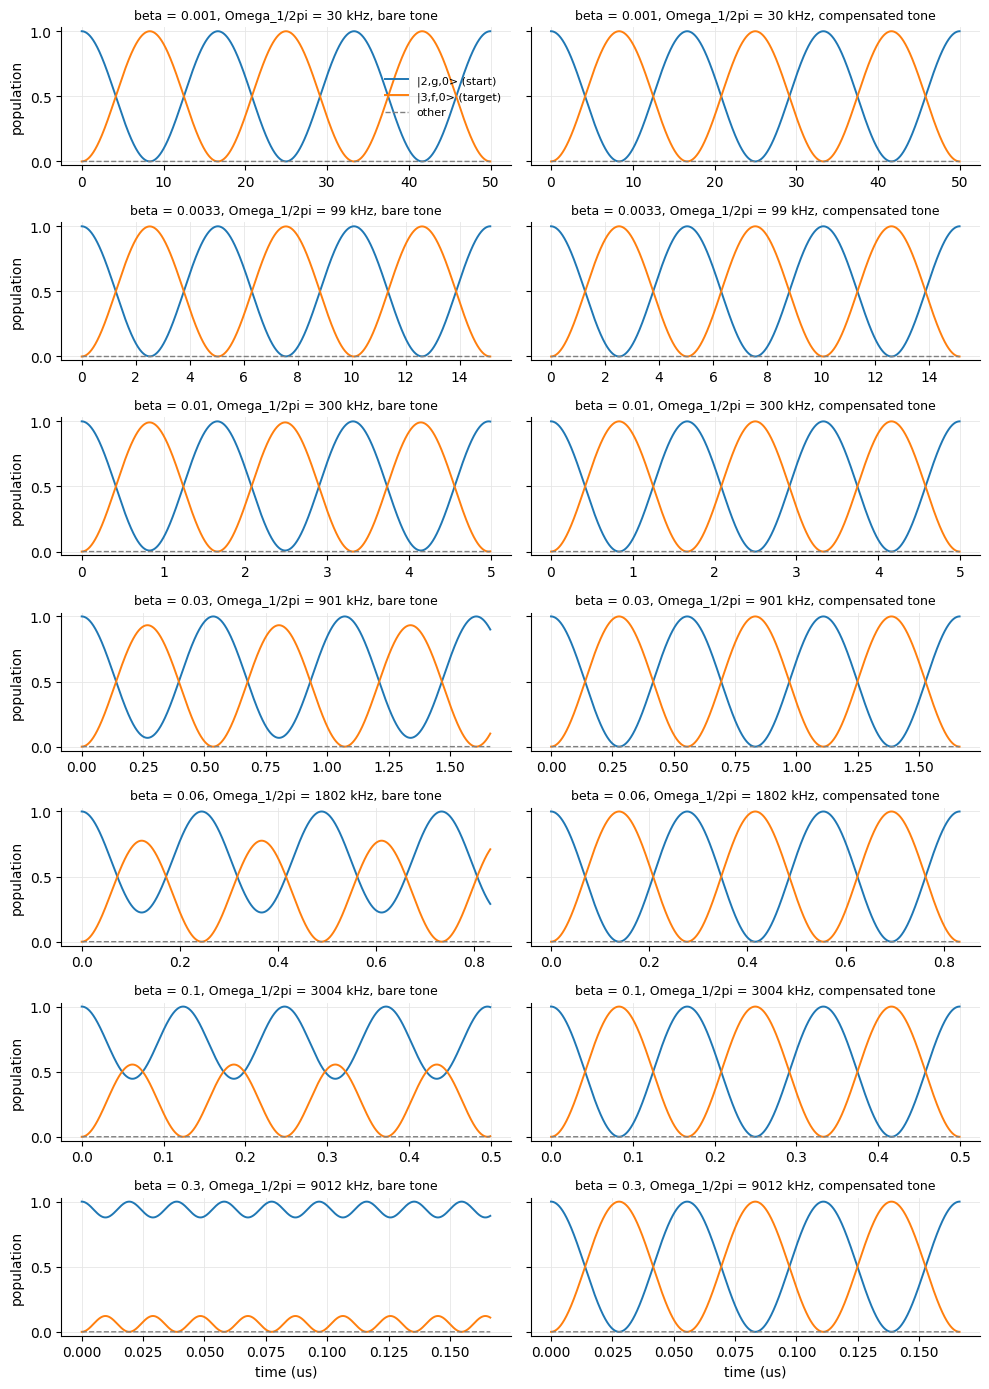

In [9]:
fig, axes = plt.subplots(len(BETAS_SHOW), 2, figsize=(10, 2.0 * len(BETAS_SHOW)), sharey=True)
for row, beta in enumerate(BETAS_SHOW):
    t, T = time_grid(beta)
    for col, comp in enumerate((False, True)):
        P = simulate(beta, i0, t, compensate=comp)
        ax = axes[row, col]
        ax.plot(t, P[:, i0], color="C0", lw=1.4, label="|2,g,0> (start)")
        ax.plot(t, P[:, i1], color="C1", lw=1.4, label="|3,f,0> (target)")
        ax.plot(t, 1 - P[:, i0] - P[:, i1], color="0.5", lw=1.0, ls="--", label="other")
        ax.set_ylim(-0.03, 1.03)
        ax.set_title(f"beta = {beta:g}, Omega_1/2pi = {1e3 * mhz(omega_1(beta)):.0f} kHz, "
                     f"{'compensated' if comp else 'bare'} tone", fontsize=9)
        tidy(ax)
        if col == 0:
            ax.set_ylabel("population")
        if row == len(BETAS_SHOW) - 1:
            ax.set_xlabel("time (us)")
axes[0, 0].legend(fontsize=8, frameon=False, loc="center right")
fig.tight_layout()
fig.savefig("figures/fwm_tuning_rabi.png", dpi=150)
plt.show()

**Figure 1.** Rabi oscillation $|2,g,0\rangle \rightleftarrows |3,f,0\rangle$ over three swap periods, one row per
pump strength (the paper's $\beta = 0.0033$ is the second row). Blue: start $|2,g,0\rangle$; orange: target
$|3,f,0\rangle$; grey dashed: all other states, which stay at zero. Left: tone at the bare frequency, whose swap
becomes incomplete as $\beta$ grows (contrast 0.93 at $\beta = 0.03$, 0.78 at 0.06, 0.55 at 0.1, 0.12 at 0.3; Table 8). Right: tone retuned
by the Stark shift, a full swap at every $\beta$. The time axis is in μs, so it shrinks as $1/\beta$ down the rows.

# 5. Sweep over the pump strength

§4 looked at seven pump strengths. Here the same simulation runs at 37, log-spaced from $\beta = 3\times10^{-4}$ to
0.32, for both tunings (the six above 0.1 reach the strong pump of §8). It measures how well the swap works and how much the tone disturbs the neighbouring paths.

| subsection | goal |
|---|---|
| 5.1 | the quantities measured at each $\beta$, and what the closed form of §3.4 predicts for each |
| 5.2 | the Python machinery |
| 5.3 | check every measured number against the closed form |
| Fig. 2 | the sweep plotted against $\beta$ (the full time maps are Fig. A1, Appendix A) |

## 5.1 What is measured

Each run lasts three resonant periods, $3T$ with $T = \pi/\Omega_1$. Starting in $|2,g,0\rangle$ gives the swap;
starting in a neighbour gives the crosstalk.

**Table 9.** Quantities recorded per $\beta$ and tuning (columns of `sweep`), with their closed-form values.

| column | measured from the simulation | closed form (§3.4) |
|---|---|---|
| `contrast` | $\max_t P_{3f0}(t)$ from $\lvert 2,g,0\rangle$ | $4\Omega_1^2/(4\Omega_1^2 + \delta^2)$, $\delta = \delta_S$ (bare) or 0 (compensated) |
| `two_state_err` | $\max_t \lvert P_{2g0} + P_{3f0} - 1\rvert$ | 0 |
| `rate_ratio` | $(\pi/t_{\max}) \,/\, \sqrt{4\Omega_1^2 + \delta^2}$, $t_{\max}$ from `first_max_time` | 1 |
| `xt \|1,g,0>` | $1 - \min_t P_{1g0}(t)$ from $\lvert 1,g,0\rangle$ | $4\Omega_1(2)^2/(4\Omega_1(2)^2 + \omega_2^2)$, $\Omega_1(2) = 2g\beta$ |
| `xt \|3,g,0>` | $1 - \min_t P_{3g0}(t)$ from $\lvert 3,g,0\rangle$ | $4\Omega_1(4)^2/(4\Omega_1(4)^2 + \omega_4^2)$, $\Omega_1(4) = \sqrt8\,g\beta$ |
| `crosstalk` | the larger of the two | |

**In plain words.**

- **Contrast** is how complete the swap is: the largest share of the population that ever reaches the target
  $|3,f,0\rangle$. 1 means a full swap. It drops below 1 when the tone is off tune (here, by the Stark shift).
- **Crosstalk** is how much the tone disturbs the paths it is *not* tuned to: start in a neighbour ($|1,g,0\rangle$
  or $|3,g,0\rangle$) and take the largest share that ever leaves it. 0 means the neighbours are left alone. It
  generally grows with the pump strength (with one exception for the bare tone, below).

A good pump strength gives contrast near 1 and crosstalk near 0.

The neighbours $|1,g,0\rangle$ and $|3,g,0\rangle$ are the Fock components of the odd code words that sit one path
away from the tuned one. Their phase rates $\omega_{n'}$ (§3.3) are

$$
\omega_2 = +\chi_{gf} + \delta, \qquad \omega_4 = -\chi_{gf} + \delta \qquad (\text{plus a few kHz of Kerr and } \chi'_q),
$$

with $\chi_{gf}/2\pi = 2.07$ MHz. The Stark shift moves every path by the same amount, because each path changes
$\hat n_a$ by 1 and $\hat q^\dagger\hat q$ by 2. Three consequences can be read off before any simulation:

- **Weak pump.** The crosstalk is $\approx 4\Omega_1(n')^2/\chi_{gf}^2 \propto \beta^2$, and $|3,g,0\rangle$ loses
  twice as much as $|1,g,0\rangle$ (matrix elements $\sqrt8$ against $\sqrt4$, squared).
- **Compensated tone.** $\delta = 0$, so $|\omega_{n'}| = \chi_{gf}$ at every $\beta$, and the crosstalk only grows
  with $\beta$.
- **Bare tone.** $\delta = \delta_S < 0$ pushes path 4 further away but pulls path 2 *onto* resonance:
  $\omega_2 = 0$ at $\beta = \sqrt{\chi_{gf}/(4\alpha + \chi_{ge})} \approx 0.062$. Near there $|1,g,0\rangle$
  is swapped out almost completely, and above it the crosstalk falls again.

## 5.2 The Python machinery

The cell below runs the sweep. It only calls the §3 functions; nothing new is integrated.

**Table 10.** Names used by the sweep.

| name | what it is |
|---|---|
| `BETAS` | 37 pump strengths: `np.geomspace(3e-4, 0.1, 31)`, then six more at the same spacing, up to 0.32 |
| `XT_STARTS` | the neighbour starts, `{"\|1,g,0>": index(1, G, 0, ...), "\|3,g,0>": index(3, G, 0, ...)}` |
| `time_grid(beta)` | $0\ldots3T$, step at most 20 ns, at least 3000 points (§3.5) |
| `simulate(beta, start, t, compensate)` | populations, shape `(len(t), 48)` (§3.5) |
| `records` → `sweep` | one row per ($\beta$, tuning), columns of Table 9 |
| `TAU`, `maps` | $P_{3f0}$ resampled with `np.interp` onto a common grid $t/T \in [0, 3]$ (601 points), one list per tuning, for Fig. A1 (Appendix A) |

**Per $\beta$:** one `time_grid`; then, for each tuning, one `simulate` from $|2,g,0\rangle$ (contrast,
two-state error, Rabi rate, map row) and one from each neighbour (crosstalk), on the same grid. In total
37 × 2 × 3 = 222 runs, a few seconds.

In [10]:
BETAS = np.geomspace(3e-4, 0.1, 31)
BETAS = np.concatenate([BETAS, BETAS[-1] * (BETAS[1] / BETAS[0]) ** np.arange(1, 7)])   # six more, up to 0.32
XT_STARTS = {"|1,g,0>": index(1, G, 0, N_C, N_R), "|3,g,0>": index(3, G, 0, N_C, N_R)}
TAU = np.linspace(0, 3, 601)                     # common t/T grid for the map
records, maps = [], {False: [], True: []}
for beta in BETAS:
    t, T = time_grid(beta)
    for comp in (False, True):
        P = simulate(beta, i0, t, compensate=comp)
        delta = 0.0 if comp else stark_detuning(beta)
        rec = dict(beta=beta, tone="compensated" if comp else "bare",
                   Omega1_kHz=1e3 * mhz(omega_1(beta)),
                   contrast=P[:, i1].max(),
                   two_state_err=np.abs(P[:, i0] + P[:, i1] - 1).max(),
                   rate_ratio=(np.pi / first_max_time(t, P[:, i1])) / np.hypot(2 * omega_1(beta), delta))
        for name, s in XT_STARTS.items():
            rec["xt " + name] = 1 - simulate(beta, s, t, compensate=comp)[:, s].min()
        rec["crosstalk"] = max(rec["xt " + n] for n in XT_STARTS)
        records.append(rec)
        maps[comp].append(np.interp(TAU * T, t, P[:, i1]))
sweep = pd.DataFrame(records)
print(f"largest two-state error over the sweep: {sweep.two_state_err.max():.1e}")
print(f"Rabi rate / two-level prediction: {sweep.rate_ratio.min():.4f} .. {sweep.rate_ratio.max():.4f}")

largest two-state error over the sweep: 1.9e-09
Rabi rate / two-level prediction: 1.0000 .. 1.0000


## 5.3 Check against the closed form

`closed_form_max(beta, start, compensate)` evaluates the closed form of §3.4 for the one path that leaves `start`.
It reads that path's matrix element from `A_VALS` and its phase rate from the same `E` and `Delta` as `simulate`,
so prediction and simulation share every input except the integration. The cell adds the predictions to `sweep`
as `... (closed form)` columns and asserts agreement to $10^{-3}$, relative. The simulated maxima are sampled on the
time grid, so they can only fall short of the prediction, slightly.

In [11]:
def closed_form_max(beta, start, compensate=False):
    # Largest population the tone moves out of basis state `start` (a |n-1,g,m> state), Section 3.4.
    E = E_D + STARK_DIAG * beta ** 2
    Delta = -((E[i1] - E[i0]) if compensate else dE_bare)
    k = np.flatnonzero(COLS == start)[0]            # the one coupling that leaves `start`
    O1 = G_FWM * beta * abs(A_VALS[k])              # Omega_1(n') on that path
    w = E[ROWS[k]] - E[COLS[k]] + Delta             # its phase rate
    return 4 * O1 ** 2 / (4 * O1 ** 2 + w ** 2)


for col, start in [("contrast", i0)] + [("xt " + n, s) for n, s in XT_STARTS.items()]:
    pred = [closed_form_max(b, start, tone == "compensated") for b, tone in zip(sweep.beta, sweep.tone)]
    sweep[col + " (closed form)"] = pred
    rel = np.abs(sweep[col] / sweep[col + " (closed form)"] - 1).max()
    print(f"{col:<10s} simulated / closed form - 1: at most {rel:.1e}")
    assert rel < 1e-3
print(f"bare tone on resonance with path 2 at beta = "
      f"{np.sqrt(dev.chi_gf / (4 * dev.alpha_q + dev.chi_ge)):.4f}")

contrast   simulated / closed form - 1: at most 1.1e-06
xt |1,g,0> simulated / closed form - 1: at most 1.4e-04
xt |3,g,0> simulated / closed form - 1: at most 5.4e-06
bare tone on resonance with path 2 at beta = 0.0620


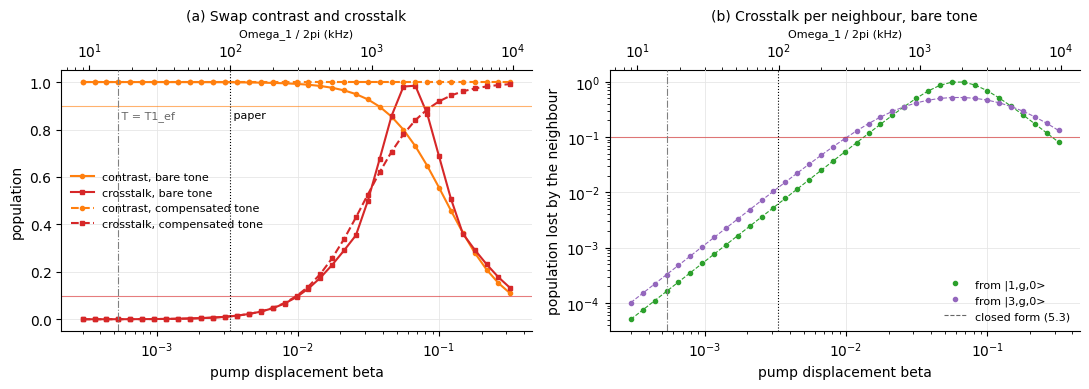

In [12]:
CONTRAST_MIN, XT_MAX = 0.9, 0.1      # pass thresholds of §6 and §7.3
beta_T1 = np.pi / dev.T1_EF / omega_1(1.0)   # beta at which the swap period T equals T1_ef

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
for tone, ls in (("bare", "-"), ("compensated", "--")):
    s = sweep[sweep.tone == tone]
    ax.plot(s.beta, s.contrast, ls, color="C1", marker="o", ms=3, label=f"contrast, {tone} tone")
    ax.plot(s.beta, s.crosstalk, ls, color="C3", marker="s", ms=3, label=f"crosstalk, {tone} tone")
ax.axhline(CONTRAST_MIN, color="C1", lw=0.8, alpha=0.6)
ax.axhline(XT_MAX, color="C3", lw=0.8, alpha=0.6)
ax.set_xscale("log")
ax.set_xlabel("pump displacement beta")
ax.set_ylabel("population")
ax.set_title("(a) Swap contrast and crosstalk", fontsize=10)
ax.legend(fontsize=8, frameon=False, loc="center left")

ax = axes[1]
s = sweep[sweep.tone == "bare"]
for name, c in zip(XT_STARTS, ("C2", "C4")):
    ax.plot(s.beta, s["xt " + name], color=c, ls="none", marker="o", ms=3, label=f"from {name}")
    ax.plot(s.beta, s["xt " + name + " (closed form)"], color=c, lw=0.8, ls="--")
ax.plot([], [], color="0.4", lw=0.8, ls="--", label="closed form (5.3)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.axhline(XT_MAX, color="C3", lw=0.8, alpha=0.6)
ax.set_xlabel("pump displacement beta")
ax.set_ylabel("population lost by the neighbour")
ax.set_title("(b) Crosstalk per neighbour, bare tone", fontsize=10)
ax.legend(fontsize=8, frameon=False)

for ax in axes:
    ax.axvline(BETA_PAPER, color="k", lw=0.8, ls=":")
    ax.axvline(beta_T1, color="0.5", lw=0.8, ls="-.")
    tidy(ax)
    top = ax.secondary_xaxis("top", functions=(lambda b: 1e3 * mhz(omega_1(b)),
                                               lambda o: o / (1e3 * mhz(omega_1(1.0)))))
    top.set_xlabel("Omega_1 / 2pi (kHz)", fontsize=8)
axes[0].text(BETA_PAPER, 0.85, " paper", fontsize=8)
axes[0].text(beta_T1, 0.85, " T = T1_ef", fontsize=8, color="0.4")
fig.tight_layout()
fig.savefig("figures/fwm_tuning_sweep.png", dpi=150)
plt.show()

**Figure 2.** Pump-strength sweep: swap contrast and crosstalk against $\beta$ (37 values, each run for $3T$).

| Element | Meaning |
|---|---|
| Bottom axis | pump displacement $\beta$ (log scale) |
| Top axis | the same $\beta$ as the swap rate $\Omega_1/2\pi$ on the $n = 3$ path |
| Dotted vertical line | the paper's $\beta$ |
| Dash-dot vertical line | the $\beta$ at which one swap period $T$ equals $T_{1,ef}$ |
| (a) orange circles | contrast |
| (a) red squares | worst crosstalk |
| (a) solid / dashed | bare / compensated tone |
| (a) thin horizontal lines | the thresholds of §6: contrast 0.9, crosstalk 0.1 |
| (b) markers | crosstalk of each neighbour, bare tone, simulation (log scale) |
| (b) dashed lines | closed form of §5.3 |

| $\beta$ | What happens |
|---|---|
| weak pumping | (b) Both neighbours' crosstalk grows as $\beta^2$; $\lvert 3,g,0\rangle$ grows twice as fast. |
| $\approx 0.010$ | (a) Crosstalk crosses 0.1, for both tunings ($\beta$ = 0.0099 compensated, 0.0101 bare). |
| $\gtrsim 0.026$ | (a) The bare contrast starts to fall, and drops below 0.9 at $\beta \approx 0.037$; the compensated contrast does not fall. |
| $\approx 0.062$ | (b) The $\lvert 1,g,0\rangle$ curve peaks: the Stark shift brings the bare tone onto resonance with path 2. This is also the peak of the solid red curve in (a). |
| $> 0.1$ (six points added for §8) | Compensated crosstalk keeps rising, to 0.99 at $\beta = 0.32$: $\Omega_1$ now exceeds $\chi_{gf}$, so the neighbours swap almost fully. Bare contrast and crosstalk both fall to about 0.1: the Stark detuning pushes every path off resonance. |

# 6. The working range

Our criterion for "swaps between two distinct states": **contrast ≥ 0.9 and crosstalk ≤ 0.1**. The closed model has
no lower limit, because any $\beta$ swaps fully if you wait long enough. As a reference for the lower end we use the
pump at which one swap period $T$ equals $T_{1,ef} = 31$ μs, the lifetime of $|f\rangle$ (not simulated here; §7.3
computes the lower end with dissipation).

In [13]:
rows = []
for tone in ("bare", "compensated"):
    s = sweep[sweep.tone == tone].reset_index(drop=True)
    ok = (s.contrast >= CONTRAST_MIN) & (s.crosstalk <= XT_MAX)
    bad_c = s.beta[s.contrast < CONTRAST_MIN]
    bad_x = s.beta[s.crosstalk > XT_MAX]
    top = s.beta[ok].max()
    rows.append({"tone": tone,
                 "beta low (T = T1_ef)": beta_T1, "beta high": top,
                 "Omega_1/2pi low (kHz)": 1e3 * mhz(omega_1(beta_T1)),
                 "Omega_1/2pi high (kHz)": 1e3 * mhz(omega_1(top)),
                 f"first beta, contrast < {CONTRAST_MIN}": bad_c.min() if len(bad_c) else np.nan,
                 f"first beta, crosstalk > {XT_MAX}": bad_x.min() if len(bad_x) else np.nan})
range_table = pd.DataFrame(rows).set_index("tone")
display(range_table.style.format("{:.4g}", na_rep="none").set_caption(
    f"Table 11. Pump range of a clean two-state swap (contrast >= {CONTRAST_MIN}, crosstalk <= {XT_MAX}). "
    "Low end: the beta at which T = T1_ef (the closed model has no lower limit). High end: the largest swept "
    "beta that passes both criteria. Last two columns: the first swept beta that fails each criterion."))
print(f"paper's beta = {BETA_PAPER}: Omega_1/2pi = {1e3 * mhz(omega_1(BETA_PAPER)):.0f} kHz on n = 3, "
      f"swap period T = {np.pi / omega_1(BETA_PAPER):.1f} us")
t, _ = time_grid(BETA_PAPER)
for name, s in XT_STARTS.items():
    print(f"  crosstalk from {name} at the paper's beta: {1 - simulate(BETA_PAPER, s, t)[:, s].min():.4f}")

,beta low (T = T1_ef),beta high,Omega_1/2pi low (kHz),Omega_1/2pi high (kHz),"first beta, contrast < 0.9","first beta, crosstalk > 0.1"
tone,,,,,,
bare,0.0005369,0.009791,16.13,294.1,0.03798,0.01188
compensated,0.0005369,0.009791,16.13,294.1,none,0.01188


paper's beta = 0.0033: Omega_1/2pi = 99 kHz on n = 3, swap period T = 5.0 us
  crosstalk from |1,g,0> at the paper's beta: 0.0061
  crosstalk from |3,g,0> at the paper's beta: 0.0121


# 7. Results with dissipation

§4–§6 used the closed solver. There every pump path is a sealed pair (§3.4), the swap is complete at any $\beta$, and
"other" stays at zero. A real chip leaks. This section repeats the key runs with the open solver of §3.2–§3.5 and
asks three questions:

1. How much does decay damp the Rabi swap (§7.1)?
2. Where does the lost population go (§7.2)? After a photon leaks out of the storage, or the transmon relaxes, the
   state leaves its pair and spreads over many states. We call this **mixing**. The word has two meanings here, and
   both are shown:
   - population moves *between* pairs, i.e. between photon numbers and transmon levels;
   - the state becomes a statistical *mixture* of possibilities (a mixed state), which no single wave function can
     describe.
3. What is left of the working range of §6 (§7.3)? There its lower end was only a reference line. Here it is
   computed.

The main results use the decay set; one curve per figure uses all channels (Table 3).

| subsection | goal |
|---|---|
| 7.1 | damped Rabi oscillations |
| 7.2 | where the population goes: mixing between pairs, and a mixed state |
| 7.3 | the pump sweep with dissipation, and the new working range |

## 7.1 Damped Rabi oscillations

**What is run.** The seven pump strengths of §4, compensated tone, start $|2,g,0\rangle$, over $3T$: closed, decay only,
and all channels.

**What to expect.** While the pump swaps population inside the pair, the pair also leaks:

- $|2,g,0\rangle$ loses a photon at rate $2\kappa_a$ (two photons, each lost at $\kappa_a$);
- $|3,f,0\rangle$ loses a photon at $3\kappa_a$ and decays $f \to e$ at $\gamma_{ef} = 1/T_{1,ef}$.

During the first half swap the population spends, on average, half its time in each state. So the pair leaks at about

$$
\Gamma_{\rm pair} = \tfrac12\,(2\kappa_a) + \tfrac12\,(3\kappa_a + \gamma_{ef}) = 2.5\,\kappa_a + \tfrac12\,\gamma_{ef}
\approx (29\ \mu\text{s})^{-1} .
$$

The target first peaks at $t = T/2 = \pi/(2\Omega_1)$, so the contrast should be about

$$
P_{\max} \approx \exp\!\big(-\Gamma_{\rm pair}\,T/2\big) = \exp\!\Big(-\frac{\pi\,\Gamma_{\rm pair}}{2\,\Omega_1}\Big) .
$$

What matters is the swap rate compared with the loss rate: a slow swap (small $\beta$) spends longer exposed to loss.
The estimate assumes $\Gamma_{\rm pair} \ll \Omega_1$. Table 12 tests it.

In [14]:
GAMMA_PAIR = 2.5 * dev.kappa_a + 0.5 / dev.T1_EF     # mean loss rate of the pair over half a swap (§7.1)


def contrast_decay_estimate(beta):
    # survival of the pair up to the first maximum, t = T/2 = pi / (2 Omega_1)
    return np.exp(-GAMMA_PAIR * np.pi / (2 * omega_1(beta)))


rabi_open, rows = {}, []
for beta in BETAS_SHOW:
    T = np.pi / omega_1(beta)
    t = np.linspace(0, 3 * T, 1201)
    rabi_open[beta] = {ch: populations(simulate_open(beta, rho_basis(i0, MODEL[ch].d), t, MODEL[ch],
                                                     compensate=True))
                       for ch in ("none", "decay", "all")}
    rabi_open[beta]["t"] = t
    rows.append({"beta": beta, "T (us)": T,
                 "closed": rabi_open[beta]["none"][:, i1].max(),
                 "decay, estimate": contrast_decay_estimate(beta),
                 "decay, simulated": rabi_open[beta]["decay"][:, i1].max(),
                 "all channels, simulated": rabi_open[beta]["all"][:, i1].max(),
                 "decay: other at 3T": 1 - rabi_open[beta]["decay"][-1, [i0, i1]].sum()})
open_contrast_table = pd.DataFrame(rows)
display(open_contrast_table.style.hide(axis="index")
        .format({"beta": "{:g}", "T (us)": "{:.2f}", "closed": "{:.4f}", "decay, estimate": "{:.4f}",
                 "decay, simulated": "{:.4f}", "all channels, simulated": "{:.4f}",
                 "decay: other at 3T": "{:.4f}"})
        .set_caption("Table 12. Swap contrast (largest P(|3,f,0>) over 3T, compensated tone) without and with "
                     "dissipation, against the estimate exp(-Gamma_pair T/2) of §7.1. Last column: population "
                     "outside the pair after 3T, decay only."))
print(f"Gamma_pair = 2.5 kappa_a + gamma_ef/2 = {GAMMA_PAIR * 1e3:.1f} ms^-1 "
      f"(1/Gamma_pair = {1 / GAMMA_PAIR:.1f} us)")

beta,T (us),closed,"decay, estimate","decay, simulated","all channels, simulated",decay: other at 3T
0.001,16.64,1.0000,0.7503,0.7585,0.7293,0.7455
0.0033,5.04,1.0000,0.9166,0.9176,0.9064,0.3997
0.01,1.66,1.0000,0.9717,0.9718,0.9679,0.1579
0.03,0.55,1.0000,0.9905,0.9905,0.9891,0.0558
0.06,0.28,1.0000,0.9952,0.9952,0.9945,0.0283
0.1,0.17,1.0000,0.9971,0.9971,0.9967,0.0171
0.3,0.06,1.0000,0.9990,0.9990,0.9989,0.0057


Gamma_pair = 2.5 kappa_a + gamma_ef/2 = 34.5 ms^-1 (1/Gamma_pair = 29.0 us)


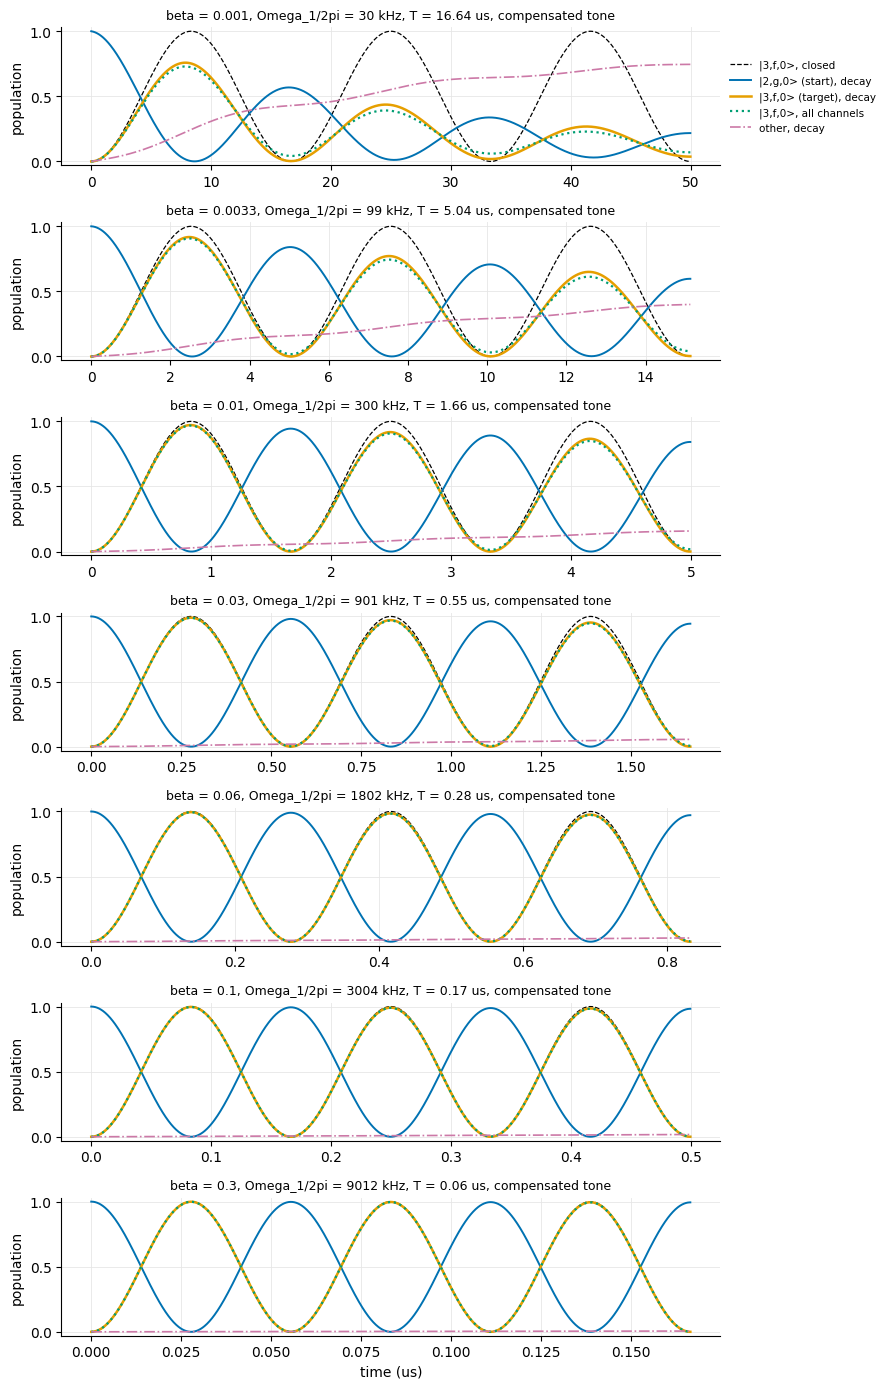

In [15]:
fig, axes = plt.subplots(len(BETAS_SHOW), 1, figsize=(9, 2.0 * len(BETAS_SHOW)), sharey=True)
for ax, beta in zip(axes, BETAS_SHOW):
    run = rabi_open[beta]
    t = run["t"]
    P, P0, Pall = run["decay"], run["none"], run["all"]
    # Okabe-Ito colours: distinct hues, and readable for colour-blind viewers
    ax.plot(t, P0[:, i1], color="k", lw=0.9, ls="--", label="|3,f,0>, closed")
    ax.plot(t, P[:, i0], color="#0072B2", lw=1.4, label="|2,g,0> (start), decay")
    ax.plot(t, P[:, i1], color="#E69F00", lw=1.8, label="|3,f,0> (target), decay")
    ax.plot(t, Pall[:, i1], color="#009E73", lw=1.6, ls=":", label="|3,f,0>, all channels")
    ax.plot(t, 1 - P[:, i0] - P[:, i1], color="#CC79A7", lw=1.2, ls="-.", label="other, decay")
    ax.set_ylim(-0.03, 1.03)
    ax.set_title(f"beta = {beta:g}, Omega_1/2pi = {1e3 * mhz(omega_1(beta)):.0f} kHz, "
                 f"T = {np.pi / omega_1(beta):.2f} us, compensated tone", fontsize=9)
    ax.set_ylabel("population")
    tidy(ax)
axes[-1].set_xlabel("time (us)")
axes[0].legend(fontsize=7.5, frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))
fig.tight_layout()
fig.savefig("figures/fwm_tuning_open_rabi.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 3.** Rabi oscillation with dissipation, compensated tone, one row per pump strength as in Fig. 1. Solid:
decay only (blue: start $|2,g,0\rangle$; orange: target $|3,f,0\rangle$). Black dashed: the closed target of Fig. 1.
Green dotted: the target with all channels. Pink dash-dot: everything outside the pair, decay only.

- **The swap keeps its period, but each peak is lower than the one before.** The first peak is 0.758 at
  $\beta = 0.001$, 0.918 at the paper's $\beta$, 0.995 at 0.06 and 0.999 at 0.3. The estimate of §7.1 is within 0.008 in every
  row (Table 12).
- **"Other" is no longer zero.** After $3T$ it holds 0.75 of the population at $\beta = 0.001$ (50 μs) and 0.40 at
  the paper's $\beta$ (15 μs).
- **The extra channels cost little more:** the all-channel peaks are 0.0007 to 0.03 lower than decay only.

## 7.2 Where the population goes: mixing

In the closed model the pair $\{|2,g,0\rangle, |3,f,0\rangle\}$ is sealed (§3.4). Each jump breaks the seal, because
it moves the state somewhere the pump treats differently:

- **Photon loss** from $|2,g,0\rangle$ lands in $|1,g,0\rangle$. That state belongs to pair 2,
  $|1,g\rangle \leftrightarrow |2,f\rangle$, which is off resonance by $\chi_{gf}$, so the tone hardly moves it.
- **$f \to e$ decay** from $|3,f,0\rangle$ lands in $|3,e,0\rangle$. With three transmon levels the pump operator
  $\hat a^\dagger\hat q^{\dagger 2}$ does nothing to $|e\rangle$, so this state is **dark**: the pump cannot touch it.
- **$e \to g$ decay** then gives $|3,g,0\rangle$, which belongs to pair 4, off resonance by $-\chi_{gf}$.

Label every state by its pair, pair $n$ = $\{|n{-}1,g,m\rangle, |n,f,m\rangle\}$, or as dark (transmon in $|e\rangle$).
Figure 4(a) follows how the population spreads over four groups of these states. Figure 4(b) shows the second meaning
of mixing, the **purity** $\mathrm{Tr}\,\hat\rho^2$. It is 1 for a pure state and falls to $1/N$ when the state is
spread evenly over $N$ possibilities.

**What is run.** The paper's $\beta$, compensated tone, start $|2,g,0\rangle$, 0–60 μs (about 12 swap periods and two
$T_{1,ef}$), all three channel sets. These are the runs of §3.6.

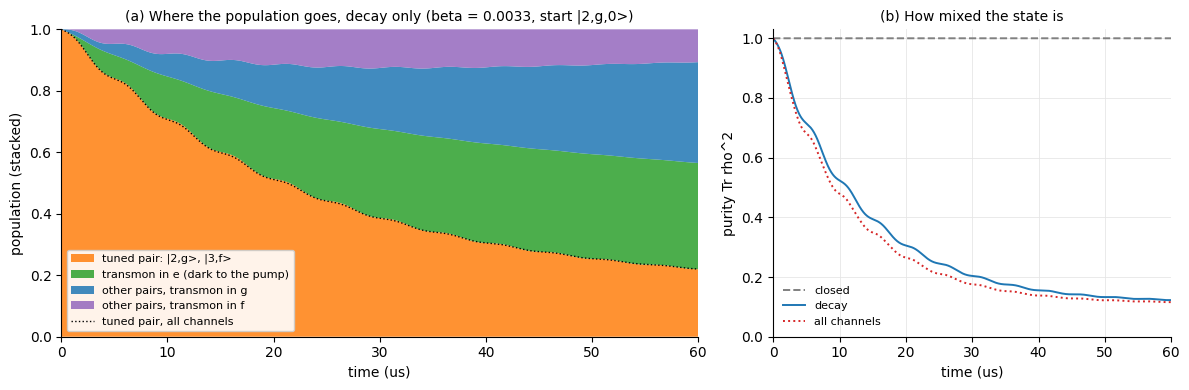

state,"P at 60 us, decay","P at 60 us, all channels"
"|1,g,0>",0.1839,0.1804
"|2,g,0>",0.1589,0.1382
"|2,e,0>",0.1442,0.1435
"|3,e,0>",0.1200,0.1172
"|3,g,0>",0.0883,0.0858
"|2,f,0>",0.0732,0.0757
"|1,e,0>",0.0693,0.0718
"|3,f,0>",0.0607,0.0821


at 60 us, decay only: tuned pair: |2,g>, |3,f> 0.220, transmon in e (dark to the pump) 0.346, other pairs, transmon in g 0.328, other pairs, transmon in f 0.107
purity at 60 us: decay 0.123, all channels 0.116


In [16]:
LABELS = np.array([f"|{n},{'gef'[j]},{mm}>" for n in range(N_C) for j in range(3) for mm in range(N_R)])
N_OF = np.repeat(np.arange(N_C), 3 * N_R)              # storage photon number of each basis state
J_OF = np.tile(np.repeat(np.arange(3), N_R), N_C)      # transmon level of each basis state
GROUPS = {
    "tuned pair: |2,g>, |3,f>": ((N_OF == 2) & (J_OF == G)) | ((N_OF == 3) & (J_OF == F)),
    "transmon in e (dark to the pump)": J_OF == E,
    "other pairs, transmon in g": (J_OF == G) & (N_OF != 2),
    "other pairs, transmon in f": (J_OF == F) & (N_OF != 3),
}
assert np.all(sum(GROUPS.values()) == 1)               # every state in exactly one group

flow = {ch: populations(rho_flow[ch]) for ch in ("none", "decay", "all")}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
ax.stackplot(t_open, *[flow["decay"][:, g].sum(axis=1) for g in GROUPS.values()],
             labels=list(GROUPS), colors=["C1", "C2", "C0", "C4"], alpha=0.85)
ax.plot(t_open, flow["all"][:, GROUPS["tuned pair: |2,g>, |3,f>"]].sum(axis=1), color="k", lw=1.0, ls=":",
        label="tuned pair, all channels")
ax.set_xlim(0, T_OPEN)
ax.set_ylim(0, 1)
ax.set_xlabel("time (us)")
ax.set_ylabel("population (stacked)")
ax.set_title(f"(a) Where the population goes, decay only (beta = {BETA_PAPER}, start |2,g,0>)", fontsize=10)
ax.legend(fontsize=8, frameon=True, framealpha=0.9, loc="lower left")
tidy(ax, grid=False)

ax = axes[1]
for ch, style, label in (("none", dict(color="0.5", ls="--"), "closed"),
                         ("decay", dict(color="C0"), "decay"),
                         ("all", dict(color="C3", ls=":"), "all channels")):
    ax.plot(t_open, purity(rho_flow[ch]), lw=1.4, label=label, **style)
ax.set_xlim(0, T_OPEN)
ax.set_ylim(0, 1.03)
ax.set_xlabel("time (us)")
ax.set_ylabel("purity Tr rho^2")
ax.set_title("(b) How mixed the state is", fontsize=10)
ax.legend(fontsize=8, frameon=False)
tidy(ax)
fig.tight_layout()
fig.savefig("figures/fwm_tuning_open_flow.png", dpi=150)
plt.show()

k_end = np.argsort(flow["decay"][-1])[::-1][:8]
top_table = pd.DataFrame({"state": LABELS[k_end], "P at 60 us, decay": flow["decay"][-1, k_end],
                          "P at 60 us, all channels": flow["all"][-1, k_end]})
display(top_table.style.hide(axis="index").format({"P at 60 us, decay": "{:.4f}",
                                                    "P at 60 us, all channels": "{:.4f}"})
        .set_caption(f"Table 13. The eight most populated states after {T_OPEN:g} us (Fig. 4)."))
print(f"at {T_OPEN:g} us, decay only: " + ", ".join(f"{name} {flow['decay'][-1, g].sum():.3f}"
                                                    for name, g in GROUPS.items()))
print(f"purity at {T_OPEN:g} us: decay {purity(rho_flow['decay'])[-1]:.3f}, "
      f"all channels {purity(rho_flow['all'])[-1]:.3f}")

**Figure 4.** (a) Population of the four groups, stacked, decay only. Black dotted: the tuned pair with all channels.
The pair loses population steadily, with a small ripple at the swap period, because its two members leak at different
rates. After 60 μs the tuned pair holds 0.22 of the population, the dark $|e\rangle$ states 0.35, the other pairs
0.33 with the transmon in $g$ and 0.11 with it in $f$. (b) Purity. The closed system stays pure. With decay the
purity falls to 0.123 at 60 μs (0.116 with all channels), so the state is spread over roughly eight states.
Table 13 lists them: the photon-loss state $|1,g,0\rangle$ is now the single most likely state, ahead of the start
$|2,g,0\rangle$.

### The Fock ladder

To see the mixing between photon numbers, start in all of them at once,

$$
|\psi_0\rangle = \frac{1}{\sqrt{10}}\sum_{n=1}^{10} |n\rangle\otimes|g,0\rangle ,
$$

and follow the photon-number distribution $P_n(t) = \sum_{j,m}\rho_{(n,j,m),(n,j,m)}$. Fock 10, plus the photon the
pump adds, needs at least 12 levels, so this runs at `N_C_LADDER = 14` ($d = 84$). It runs once more at $n_c = 16$
as a truncation check.

**The superposition carries no extra information about populations.** The pump keeps every pair sealed, and every
jump moves one basis state to one other basis state. Two different states never land on the same state, so a
coherence between them never turns into a population. Hence $P_n(t)$ from the superposition must equal the average of
the ten runs that each start in one $|n,g,0\rangle$. The cell below asserts this. The superposition is just a compact
way to show all ten runs in one picture. Its coherences still matter, for the phases of the code, but they are not
plotted here.

In [17]:
LADDER_FOCK = range(1, 11)
t_lad = np.linspace(0, T_OPEN, 601)


def ladder_start(n_c):
    psi = np.zeros(dim(n_c, N_R), dtype=complex)
    for n in LADDER_FOCK:
        psi[index(n, G, 0, n_c, N_R)] = 1.0
    psi /= np.linalg.norm(psi)
    return np.outer(psi, psi.conj())


MODEL_LAD = {ch: open_model(N_C_LADDER, ch) for ch in ("none", "decay")}
fock_lad = {ch: fock_populations(simulate_open(BETA_PAPER, ladder_start(N_C_LADDER), t_lad, MODEL_LAD[ch],
                                               compensate=True), N_C_LADDER)
            for ch in ("none", "decay")}

# Truncation: the same run with two more Fock levels
m16 = open_model(N_C_LADDER + 2, "decay")
fock_16 = fock_populations(simulate_open(BETA_PAPER, ladder_start(m16.n_c), t_lad, m16, compensate=True), m16.n_c)
trunc_err = max(np.abs(fock_16[:, :N_C_LADDER] - fock_lad["decay"]).max(), fock_16[:, N_C_LADDER:].max())

# Superposition = average of the single-Fock runs (populations only)
fock_avg = np.zeros_like(fock_lad["decay"])
for n in LADDER_FOCK:
    k = index(n, G, 0, N_C_LADDER, N_R)
    fock_avg += fock_populations(simulate_open(BETA_PAPER, rho_basis(k, MODEL_LAD["decay"].d), t_lad,
                                               MODEL_LAD["decay"], compensate=True), N_C_LADDER)
fock_avg /= len(LADDER_FOCK)
avg_err = np.abs(fock_lad["decay"] - fock_avg).max()

print(f"truncation n_c = {N_C_LADDER} vs {m16.n_c}: max |dP_n| = {trunc_err:.1e}; "
      f"largest population at Fock >= {N_C_LADDER - 2}: {fock_lad['decay'][:, N_C_LADDER - 2:].max():.1e}")
print(f"superposition vs average of the {len(LADDER_FOCK)} single-Fock runs: max |dP_n| = {avg_err:.1e}")
print(f"mean photon number: {np.arange(N_C_LADDER) @ fock_lad['decay'][0]:.2f} at t = 0, "
      f"{np.arange(N_C_LADDER) @ fock_lad['decay'][-1]:.2f} at {T_OPEN:g} us "
      f"(closed: {np.arange(N_C_LADDER) @ fock_lad['none'][-1]:.2f})")
assert trunc_err < 1e-6
assert avg_err < 1e-7

truncation n_c = 14 vs 16: max |dP_n| = 3.4e-10; largest population at Fock >= 12: 1.4e-10
superposition vs average of the 10 single-Fock runs: max |dP_n| = 7.1e-09
mean photon number: 5.50 at t = 0, 3.69 at 60 us (closed: 5.51)


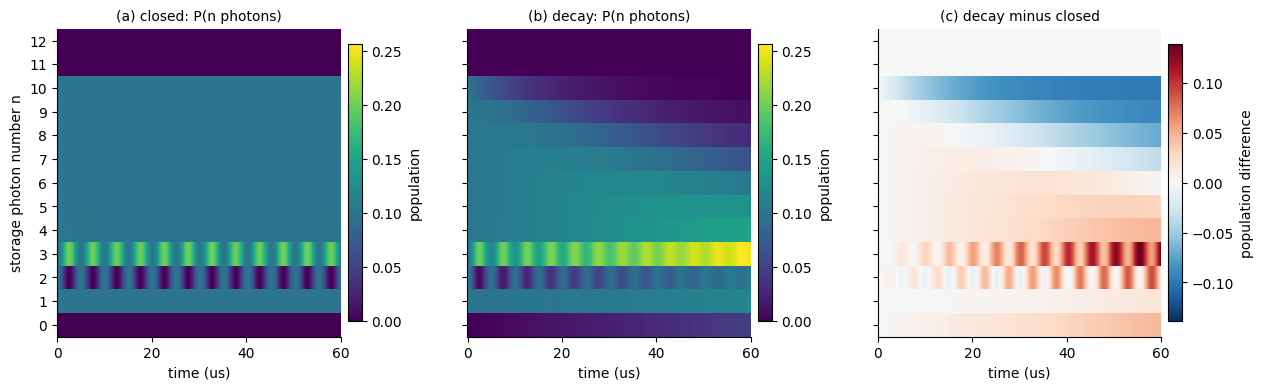

In [18]:
n_show = N_C_LADDER - 1                                 # Fock 0..12
fock_axis = np.arange(n_show)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
vmax = max(fock_lad["none"].max(), fock_lad["decay"].max())
for ax, ch, title in ((axes[0], "none", "(a) closed"), (axes[1], "decay", "(b) decay")):
    im = ax.pcolormesh(t_lad, fock_axis, fock_lad[ch][:, :n_show].T, shading="auto", cmap="viridis",
                       vmin=0, vmax=vmax)
    ax.set_title(f"{title}: P(n photons)", fontsize=10)
    fig.colorbar(im, ax=ax, shrink=0.9, pad=0.02, label="population")
dP = (fock_lad["decay"] - fock_lad["none"])[:, :n_show]
lim = np.abs(dP).max()
im2 = axes[2].pcolormesh(t_lad, fock_axis, dP.T, shading="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
axes[2].set_title("(c) decay minus closed", fontsize=10)
fig.colorbar(im2, ax=axes[2], shrink=0.9, pad=0.02, label="population difference")
for ax in axes:
    ax.set_xlabel("time (us)")
    ax.set_yticks(fock_axis)
    tidy(ax, grid=False)
axes[0].set_ylabel("storage photon number n")
fig.savefig("figures/fwm_tuning_open_fock.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 5.** Photon-number distribution from $(|1\rangle + \dots + |10\rangle)/\sqrt{10}\otimes|g,0\rangle$, paper's
$\beta$, compensated tone.

- **(a) Closed.** Only Fock 2 and 3 change: they swap population back and forth (the stripes). Every other row stays
  at 0.1, because the tone is off resonance on their pairs.
- **(b) Decay.** The whole ladder slides down. High photon numbers empty fastest (Fock $n$ loses photons at rate
  $n\kappa_a$, so Fock 10 at $(13.6\ \mu\text{s})^{-1}$), and Fock 0, empty at the start, fills up. The stripes fade
  as the swap loses contrast. Fock 3 grows to 0.25. It receives the photon loss from Fock 4, and population that has
  decayed to $|3,e\rangle$ or $|3,g\rangle$ is no longer pumped back down to Fock 2.
- **(c) The difference.** Red where decay adds population, blue where it removes it.

The mean photon number falls from 5.50 to 3.69 in 60 μs (closed: 5.51). The run at $n_c = 16$ agrees to
$3\times10^{-10}$, and the superposition matches the average of the single-Fock runs to $7\times10^{-9}$.

## 7.3 The working range with dissipation

§6 asked for contrast $\ge 0.9$ and crosstalk $\le 0.1$. It found $\beta \approx 5\times10^{-4}$ to $1\times10^{-2}$,
but the lower end was only a reference line ($T = T_{1,ef}$). With dissipation the lower end is real. By the estimate
of §7.1, a contrast of at least 0.9 needs

$$
\Omega_1 \;\ge\; \frac{\pi\,\Gamma_{\rm pair}}{2\ln(1/0.9)} \approx 2\pi\times 82\ \text{kHz} ,
$$

i.e. $\beta \ge 0.0027$: a swap fast enough to beat the loss.

**What is run.** The 37 pump strengths of §5, start $|2,g,0\rangle$, over $3T$: decay only with both tunings, and all
channels with the compensated tone (111 runs, about a minute and a half). The contrast is the largest $P_{3f0}$, as
in §5.

**The crosstalk is not rerun.** It is set by how far the neighbouring paths are off resonance,
$\chi_{gf}/2\pi = 2.07$ MHz. Decay at rates around $(30\ \mu\text{s})^{-1}$ cannot change that. Measured in an open
run as $1 - \min_t P_{\rm start}$, it would also count the start's own decay as crosstalk. So §7.3 keeps the closed
crosstalk of §5.

**Table 14** (second cell below) finds the window. Its edges are interpolated between the swept $\beta$, which are
about 20% apart, so that the edges are not limited to the grid.

In [19]:
OPEN_RUNS = (("decay", False), ("decay", True), ("all", True))      # (channels, compensate)
open_records = []
for beta in BETAS:
    T = np.pi / omega_1(beta)
    t = np.linspace(0, 3 * T, 1201)
    rec = {"beta": beta}
    for ch, comp in OPEN_RUNS:
        P = populations(simulate_open(beta, rho_basis(i0, MODEL[ch].d), t, MODEL[ch], compensate=comp))
        rec[f"{ch}, {'compensated' if comp else 'bare'}"] = P[:, i1].max()
    rec["decay, estimate"] = contrast_decay_estimate(beta)
    open_records.append(rec)
open_sweep = pd.DataFrame(open_records)
closed = sweep.pivot(index="beta", columns="tone", values=["contrast", "crosstalk"])
for tone in ("bare", "compensated"):
    open_sweep[f"closed, {tone}"] = closed[("contrast", tone)].values
    open_sweep[f"crosstalk, {tone}"] = closed[("crosstalk", tone)].values
print(f"{len(BETAS) * len(OPEN_RUNS)} open runs")

111 open runs


In [20]:
def crossing(x, y, level, rising=True):
    # first x where y crosses `level` upward (rising) or downward, linear in log(x); nan if never
    y = np.asarray(y, dtype=float)
    above = (y >= level) if rising else (y <= level)
    k = np.flatnonzero(~above[:-1] & above[1:])
    if not len(k):
        return np.nan
    k, lx = k[0], np.log(x)
    return float(np.exp(lx[k] + (level - y[k]) / (y[k + 1] - y[k]) * (lx[k + 1] - lx[k])))


LOW_COL = f"beta low (contrast = {CONTRAST_MIN})"   # column name of the low edge


def open_range(s, n_path=N_PATH, runs=(("decay, bare", "bare"), ("decay, compensated", "compensated"),
                                       ("all, compensated", "compensated"))):
    # Working range of each open run in sweep table `s` (the rows of Table 14; Appendix B reuses it per path)
    rows = []
    for col, tone in runs:
        lo = crossing(s.beta, s[col], CONTRAST_MIN)
        hi_xt = crossing(s.beta, s[f"crosstalk, {tone}"], XT_MAX)
        hi_c = crossing(s.beta, s[col], CONTRAST_MIN, rising=False)
        hi = np.nanmin([hi_xt, hi_c])
        best = s[col].idxmax()
        rows.append({"run": col,
                     LOW_COL: lo, "beta high": hi,
                     "high end set by": "crosstalk" if hi == hi_xt else "contrast",
                     "Omega_1/2pi low (kHz)": 1e3 * mhz(omega_1(lo, n_path)),
                     "Omega_1/2pi high (kHz)": 1e3 * mhz(omega_1(hi, n_path)),
                     "high / low": hi / lo,
                     "largest swept contrast": s[col][best], "at beta": s.beta[best],
                     "contrast at paper's beta": np.interp(np.log(BETA_PAPER), np.log(s.beta), s[col])})
    return pd.DataFrame(rows).set_index("run")


open_range_table = open_range(open_sweep)
display(open_range_table.style.format({c: "{:.4g}" for c in open_range_table.columns if c != "high end set by"})
        .set_caption(
    f"Table 14. Pump range of a clean swap with dissipation: open contrast >= {CONTRAST_MIN} and closed crosstalk "
    f"<= {XT_MAX}. Both edges are interpolated between swept betas (linear in log beta). Low end: where the open "
    f"contrast reaches {CONTRAST_MIN}. High end: where the crosstalk reaches {XT_MAX}, or the contrast falls back "
    f"below {CONTRAST_MIN}, "
    "whichever comes first. Last three columns: the best swept point, and the contrast at the paper's beta."))
WINDOW = open_range_table.loc["decay, compensated", [LOW_COL, "beta high"]].values
# The low end in closed form, from the estimate: exp(-Gamma_pair pi / (2 Omega_1)) = CONTRAST_MIN
beta_low_est = GAMMA_PAIR * np.pi / (2 * -np.log(CONTRAST_MIN)) / omega_1(1.0)
print(f"estimate: contrast >= {CONTRAST_MIN} needs Omega_1 >= pi Gamma_pair / (2 ln(1/{CONTRAST_MIN})), "
      f"i.e. Omega_1/2pi >= {1e3 * mhz(omega_1(beta_low_est)):.0f} kHz, beta >= {beta_low_est:.4f}")
strong = open_sweep.beta >= 1e-3
print(f"estimate vs simulation (decay, compensated): at most "
      f"{np.abs(open_sweep['decay, estimate'] - open_sweep['decay, compensated'])[strong].max():.4f} for beta >= 1e-3, "
      f"{np.abs(open_sweep['decay, estimate'] - open_sweep['decay, compensated']).max():.4f} over the whole sweep")

,beta low (contrast = 0.9),beta high,high end set by,Omega_1/2pi low (kHz),Omega_1/2pi high (kHz),high / low,largest swept contrast,at beta,contrast at paper's beta
run,,,,,,,,,
"decay, bare",0.002712,0.01013,crosstalk,81.48,304.4,3.737,0.9654,0.01188,0.9165
"decay, compensated",0.002697,0.009892,crosstalk,81.02,297.1,3.667,0.9991,0.3196,0.9173
"all, compensated",0.003075,0.009892,crosstalk,92.38,297.1,3.216,0.999,0.3196,0.9061


estimate: contrast >= 0.9 needs Omega_1 >= pi Gamma_pair / (2 ln(1/0.9)), i.e. Omega_1/2pi >= 82 kHz, beta >= 0.0027
estimate vs simulation (decay, compensated): at most 0.0063 for beta >= 1e-3, 0.0452 over the whole sweep


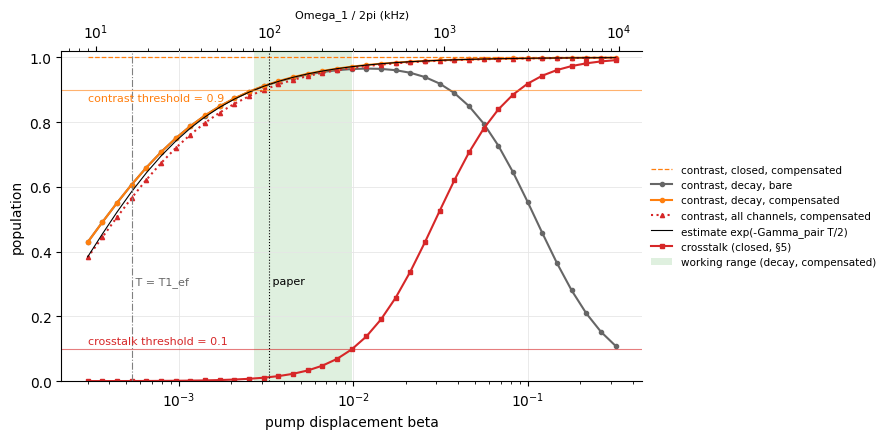

In [21]:
def plot_open_sweep(ax, s, window, n_path=N_PATH, legend=True):
    # Fig. 6 layout for the open sweep table `s` of the tone on path n_path; `window` = (beta_lo, beta_hi)
    ax.plot(s.beta, s["closed, compensated"], color="C1", lw=0.9, ls="--", label="contrast, closed, compensated")
    ax.plot(s.beta, s["decay, bare"], color="0.4", marker="o", ms=3, label="contrast, decay, bare")
    ax.plot(s.beta, s["decay, compensated"], color="C1", marker="o", ms=3, label="contrast, decay, compensated")
    ax.plot(s.beta, s["all, compensated"], color="C3", ls=":", marker="^", ms=3,
            label="contrast, all channels, compensated")
    ax.plot(s.beta, s["decay, estimate"], color="k", lw=0.8, label="estimate exp(-Gamma_pair T/2)")
    ax.plot(s.beta, s["crosstalk, compensated"], color="C3", marker="s", ms=3, label="crosstalk (closed, §5)")
    if window[0] < window[1]:                       # no band when the window has closed
        ax.axvspan(*window, color="C2", alpha=0.15, lw=0, label="working range (decay, compensated)")
    ax.axhline(CONTRAST_MIN, color="C1", lw=0.8, alpha=0.6)
    ax.axhline(XT_MAX, color="C3", lw=0.8, alpha=0.6)
    ax.text(s.beta.min(), CONTRAST_MIN - 0.01, f"contrast threshold = {CONTRAST_MIN}", fontsize=8, color="C1",
            va="top")
    ax.text(s.beta.min(), XT_MAX + 0.01, f"crosstalk threshold = {XT_MAX}", fontsize=8, color="C3", va="bottom")
    b_T1 = np.pi / dev.T1_EF / omega_1(1.0, n_path)   # beta at which the swap period T equals T1_ef
    ax.axvline(BETA_PAPER, color="k", lw=0.8, ls=":")
    ax.axvline(b_T1, color="0.5", lw=0.8, ls="-.")
    ax.text(BETA_PAPER, 0.3, " paper", fontsize=8)
    ax.text(b_T1, 0.3, " T = T1_ef", fontsize=8, color="0.4")
    ax.set_xscale("log")
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("pump displacement beta")
    ax.set_ylabel("population")
    top = ax.secondary_xaxis("top", functions=(lambda b: 1e3 * mhz(omega_1(b, n_path)),
                                               lambda o: o / (1e3 * mhz(omega_1(1.0, n_path)))))
    top.set_xlabel("Omega_1 / 2pi (kHz)", fontsize=8)
    if legend:
        ax.legend(fontsize=7.5, frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))
    tidy(ax)


fig, ax = plt.subplots(figsize=(9, 4.5))
plot_open_sweep(ax, open_sweep, WINDOW)
fig.tight_layout()
fig.savefig("figures/fwm_tuning_open_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 6.** Swap contrast against pump strength, with and without dissipation; top axis $\Omega_1/2\pi$. Dashed:
closed system, compensated (§5). Circles: decay only, compensated (orange) and bare (grey). Red triangles: all channels, compensated.
Thin black: the estimate $\exp(-\Gamma_{\rm pair}T/2)$ of §7.1. During a swap the population moves back and
forth between $|2,g,0\rangle$ and $|3,f,0\rangle$, which leak at different rates; $\Gamma_{\rm pair}$ is the
average of those two rates, and the line is the fraction that survives this averaged leak for half a swap period. Red squares: the closed crosstalk. Thin horizontal lines: the pass thresholds of §6, contrast at least 0.9
(orange, 90% of the population reaches the target) and crosstalk at most 0.1 (red, a neighbour loses at most 10%). Green band: the
working range, decay only, compensated tone (Table 14). Dotted: the paper's $\beta$; dash-dot: $T = T_{1,ef}$, marks the pump strength at which one full swap period takes as long as the $|f⟩$ lifetime.

- **Decay sets a lower limit.** The contrast falls below 0.9 under $\beta = 0.0027$ ($\Omega_1/2\pi$ = 81 kHz) and to
  about 0.6 at the old reference line $T = T_{1,ef}$. The paper's $\beta$ sits just above the edge (0.917).
- **The estimate works** to within 0.006 for $\beta \ge 10^{-3}$. Below that it falls short, by up to 0.045 at the
  weakest pump, where $\Gamma_{\rm pair}$ is no longer small against $\Omega_1$.
- **Crosstalk still sets the upper limit**, at $\beta = 0.0099$ (297 kHz).
- **The bare tone** peaks at 0.965 near $\beta = 0.012$, then falls with the Stark detuning, as in Fig. 2.
- **Above $\beta = 0.1$** the compensated contrast reaches 0.999, because the swap is now far faster than any loss.
  But the crosstalk (0.99 at $\beta = 0.32$) means the tone no longer acts on one path (§8).

**Reading Table 14.**

- **The window spans a factor 3.7.** With decay only and the compensated tone it runs from $\beta = 0.0027$ to 0.0099,
  i.e. $\Omega_1/2\pi$ = 81 to 297 kHz. The closed-form low end, 82 kHz, agrees. The closed window of §6 spanned a
  factor 18; decay removes its lower part.
- **All channels narrow it**, to $\beta$ = 0.0031–0.0099 (92–297 kHz), a factor 3.2.
- **The paper's $\beta$ passes, with little margin**: contrast 0.917 with decay only and 0.906 with all channels, and
  crosstalk 0.012. It sits about 20% above the low edge of the decay-only window and 7% above the all-channel one.
- **The bare tone** gives almost the same window (0.0027–0.0101). Its Stark detuning only matters above
  $\beta \approx 0.03$, far beyond the crosstalk limit.

The 0.9 criterion asks for one complete, standalone swap. In PReSPA the swap is never left alone: stage 2 moves
$|n,f,0\rangle$ on to $|n,g,1\rangle$, and the readout photon then leaves. The correction is a one-way flow, not a Rabi
oscillation, and its rate is set differently (Shirol's Eq. (B2), `AQEC.master_equation.b2_correction_rate`). This
window answers a narrower question: how hard to pump on this chip to see one clean, isolated swap of a single tone.

# 8. Strong pump: the tone stops choosing one photon number

So far every start was one Fock state in one sealed pair. There the compensated swap is an exact $\sin^2$ at *any*
$\beta$ (§3.4; Fig. A1, right). So a strong pump does not distort the swap of $|2,g,0\rangle$ itself. What it distorts
is the *choice*: the tone is meant to act on $n = 3$ only, but once its rate $\Omega_1$ is comparable to the spacing
$\chi_{gf}$ between neighbouring paths, it drives those paths too.

**What is run.** Start in
$|\psi_0\rangle = (|1,g,0\rangle + |2,g,0\rangle + |3,g,0\rangle)/\sqrt3$: the code word $|1\rangle$, the error
state $|2\rangle$ and the code word $|3\rangle$, all with the transmon in $g$. Closed system, compensated tone, over
$3T$ ($T = \pi/\Omega_1$ on the tuned path), at $\beta$ = 0.0033 (the paper's), 0.03, 0.1 and 0.3.

**What §3.4 predicts.** Each component sits in its own pair, and nothing couples the pairs:

| path $n'$ | start → target | coupling $\Omega_1(n')$ | phase rate, compensated tone |
|---|---|---|---|
| 2 | $\lvert 1,g,0\rangle \to \lvert 2,f,0\rangle$ | $2g\beta$ | $+\chi_{gf}$ |
| 3 (tuned) | $\lvert 2,g,0\rangle \to \lvert 3,f,0\rangle$ | $\sqrt6\,g\beta$ | 0 |
| 4 | $\lvert 3,g,0\rangle \to \lvert 4,f,0\rangle$ | $\sqrt8\,g\beta$ | $-\chi_{gf}$ |

So one number decides everything: $\Omega_1/\chi_{gf}$, which is 0.05 at the paper's $\beta$ and 4.4 at 0.3.

- **Weak pump, $\Omega_1 \ll \chi_{gf}$.** Only the tuned path swaps. The total $f$ population is
  $\tfrac13\sin^2(\Omega_1 t)$: the error component (one third of the state) is corrected, and the code words are left
  alone. This is what PReSPA needs.
- **Strong pump, $\Omega_1 \gg \chi_{gf}$.** The detuning no longer protects the neighbours, and all three paths swap
  almost fully, each at its own rate $\approx 2\Omega_1(n') \propto \sqrt{n'}$, in the ratio $\sqrt4 : \sqrt6 : \sqrt8$.
  These rates share no common period, so the total $f$ population becomes a beat of three frequencies instead of a
  clean $\sin^2$. That is the distortion. The tone has become an indiscriminate "add a photon and move $g \to f$"
  for every photon number. Each path is still an exact two-level problem: these are three clean swaps at once, not
  one distorted swap.

Because the pairs are sealed, the populations of the superposition equal the mean of the three Fock runs. The cell
checks this against a direct run of the superposition with the density-matrix solver of §3.5 (no jump operators).
Dissipation is left out, because for $\beta \ge 0.03$ the whole run ($3T$) lasts at most 1.7 μs.

**How far the model can be trusted.** Table 15 carries two closed-form estimates, which are not simulated:

- the pump's Stark shift of the transmon, $2\alpha\beta^2$, as a fraction of $\alpha$. The fourth-order expansion
  behind §1 assumes this is small; it reaches 0.18 at $\beta = 0.3$.
- leakage from $|3,f,0\rangle$ one step further, to $|4, j{=}4, 0\rangle$, on a transmon with more than three levels.
  The coupling is $g\beta\sqrt4\sqrt{12}$, and it is off by $4\alpha$ (Kerr energies $E_j = -\tfrac{\alpha}{2}j(j-1)$).
  This gives about 1% at $\beta = 0.3$.

Both grow fast above $\beta \approx 0.3$, so the sweeps of §5 and §7.3 stop at 0.32.

In [22]:
STRONG_BETAS = [BETA_PAPER, 0.03, 0.1, 0.3]
PATHS = {2: (index(1, G, 0, N_C, N_R), index(2, F, 0, N_C, N_R)),   # |1,g,0> -> |2,f,0>, from code word |1>
         3: (i0, i1),                                               # |2,g,0> -> |3,f,0>, the tuned path
         4: (index(3, G, 0, N_C, N_R), index(4, F, 0, N_C, N_R))}   # |3,g,0> -> |4,f,0>, from code word |3>
IN_F = J_OF == F                                                    # transmon in |f> (any n, m)
psi_sup = np.zeros(dim(N_C, N_R), dtype=complex)
psi_sup[[s for s, _ in PATHS.values()]] = 1 / np.sqrt(3)            # (|1> + |2> + |3>)/sqrt3 (x) |g,0>
rho_sup = np.outer(psi_sup, psi_sup.conj())


def leak_estimate(beta):
    # closed form for |3,f,0> -> |4,j=4,0> on a Kerr transmon, E_j = -(alpha/2) j(j-1): coupling
    # g beta <4|a'|3> <j=4|q'^2|f> = g beta sqrt(4) sqrt(12), mistuned by 4 alpha. Not simulated.
    O = G_FWM * beta * np.sqrt(4 * 12)
    return 4 * O**2 / (4 * O**2 + (4 * dev.alpha_q) ** 2)


strong, rows = {}, []
for beta in STRONG_BETAS:
    t, T = time_grid(beta)
    run = {n: simulate(beta, s, t, compensate=True) for n, (s, _) in PATHS.items()}
    P = sum(run.values()) / 3                         # the superposition, as the mean of the three Fock runs
    # check: the superposition integrated directly (density-matrix solver of §3.5, no jumps), every 5th time
    P_direct = populations(simulate_open(beta, rho_sup, t[::5], MODEL["none"], compensate=True))
    sup_err = np.abs(P_direct - P[::5]).max()
    assert sup_err < 1e-8, sup_err
    transfer = {n: run[n][:, f].max() for n, (_, f) in PATHS.items()}
    for n, (s, _) in PATHS.items():                   # every path is still an exact two-level problem
        assert abs(transfer[n] / closed_form_max(beta, s, compensate=True) - 1) < 1e-3
    strong[beta] = dict(t=t, T=T, run=run, P=P)
    rows.append({"beta": beta, "Omega_1/2pi (MHz)": mhz(omega_1(beta)),
                 "Omega_1 / chi_gf": omega_1(beta) / dev.chi_gf,
                 "path 2 (|1,g,0>)": transfer[2], "path 3 (tuned)": transfer[3], "path 4 (|3,g,0>)": transfer[4],
                 "largest total P_f": P[:, IN_F].sum(axis=1).max(),
                 "bare tone, path 3": simulate(beta, i0, t)[:, i1].max(),
                 "Stark 2 alpha beta^2 / alpha": 2 * beta**2,
                 "leak to j = 4 (estimate)": leak_estimate(beta),
                 "superposition check": sup_err})
strong_table = pd.DataFrame(rows)
display(strong_table.style.hide(axis="index")
        .format({c: "{:.3f}" for c in strong_table.columns if c not in ("beta", "superposition check")}
                | {"beta": "{:g}", "Omega_1/2pi (MHz)": "{:.3f}", "superposition check": "{:.1e}",
                   "leak to j = 4 (estimate)": "{:.1e}"})
        .set_caption("Table 15. Strong pump, compensated tone, closed system, over 3T. Paths 2-4: largest population "
                     "the tone moves out of each start state, alone. Largest total P_f: from the superposition "
                     "(|1>+|2>+|3>)/sqrt3 (x) |g,0>. Bare tone, path 3: the §4 contrast for comparison. Last three "
                     "columns: how far the model can be trusted (Stark shift as a fraction of alpha; closed-form "
                     "leakage to the fifth transmon level, not simulated) and the superposition check."))
for beta in STRONG_BETAS:
    s = strong[beta]
    lost = 2 / 3 - s["P"][:, PATHS[2][0]] - s["P"][:, PATHS[4][0]]
    print(f"beta = {beta:g}: largest population lost from the code words {lost.max():.3f} (of 2/3), "
          f"total P_f at t = T/2 {np.interp(s['T'] / 2, s['t'], s['P'][:, IN_F].sum(axis=1)):.3f}")

beta,Omega_1/2pi (MHz),Omega_1 / chi_gf,"path 2 (|1,g,0>)",path 3 (tuned),"path 4 (|3,g,0>)",largest total P_f,"bare tone, path 3",Stark 2 alpha beta^2 / alpha,leak to j = 4 (estimate),superposition check
0.0033,0.099,0.048,0.006,1.000,0.012,0.339,0.999,0.000,1.1e-06,5.5e-10
0.03,0.901,0.435,0.337,1.000,0.505,0.545,0.933,0.002,9.0e-05,4.0e-09
0.1,3.004,1.451,0.849,1.000,0.919,0.888,0.555,0.020,1.0e-03,6.0e-09
0.3,9.012,4.354,0.981,1.000,0.990,0.946,0.122,0.180,8.9e-03,5.2e-09


beta = 0.0033: largest population lost from the code words 0.006 (of 2/3), total P_f at t = T/2 0.336
beta = 0.03: largest population lost from the code words 0.277 (of 2/3), total P_f at t = T/2 0.457
beta = 0.1: largest population lost from the code words 0.579 (of 2/3), total P_f at t = T/2 0.883
beta = 0.3: largest population lost from the code words 0.654 (of 2/3), total P_f at t = T/2 0.946


**Reading Table 15.** Each row is one pump strength. The columns, in order:

| column | what it means |
|---|---|
| `Omega_1 / chi_gf` | How hard the tone drives, compared with the gap $\chi_{gf}$ between neighbouring paths. Much less than 1: the tone acts on one photon number only. About 1 or more: it acts on all of them. Every other column follows this number. |
| `path 2 (\|1,g,0>)` | Start in the code word $\lvert 1,g,0\rangle$ alone; the largest population the tone ever moves out of it (to $\lvert 2,f,0\rangle$). Crosstalk; ideally 0. |
| `path 4 (\|3,g,0>)` | The same for the code word $\lvert 3,g,0\rangle$ (to $\lvert 4,f,0\rangle$). Always larger than path 2, because its coupling is $\sqrt8$ against $\sqrt4$. |
| `largest total P_f` | Start in $(\lvert1\rangle+\lvert2\rangle+\lvert3\rangle)/\sqrt3 \otimes \lvert g,0\rangle$; the largest total population with the transmon in $f$. **Ideal: 1/3**, meaning only the error component $\lvert 2\rangle$ (a third of the state) is moved and the code words are left alone. Above 1/3, the code words are being swapped too. |
| `bare tone, path 3` | The tuned swap $\lvert 2,g,0\rangle \to \lvert 3,f,0\rangle$ with the tone *not* retuned for the Stark shift (the contrast of §4). Ideal: 1. For comparison only: the compensated tuned swap (column `path 3`) is 1.000 in every row. |
| `Stark 2 alpha beta^2 / alpha` | The pump's shift of the transmon frequency, $2\alpha\beta^2$, as a fraction of the anharmonicity $\alpha$. The fourth-order expansion behind the model assumes it is small. At 0.18 ($\beta = 0.3$) the model is at its limit. Closed form, not simulated. |
| `leak to j = 4 (estimate)` | Population that would leak from $\lvert 3,f,0\rangle$ to $\lvert 4, j{=}4, 0\rangle$. Here $j = 4$ is the **fourth excited state** of the transmon ($j$ = 0, 1, 2 are $g$, $e$, $f$). The pump raises the transmon by two levels, so it links $f$ to $j = 4$, off resonance by $4\alpha$. The model keeps only $g, e, f$, so this is a closed-form estimate: the two-level formula below with $O = g\beta\,\sqrt4\,\sqrt{12}$ (storage $\langle 4 \vert \hat a^\dagger \vert 3\rangle$ times transmon $\langle 4 \vert \hat q^{\dagger 2} \vert f\rangle$) and $\Delta = 4\alpha$. Under 1% means it can be neglected. |
| `superposition check` | The largest difference between two ways of computing the superposition: the mean of the three single-Fock runs, and a direct density-matrix run. About $10^{-9}$ is numerical noise. It confirms that the paths do not talk to each other, so the shortcut is exact. |

**The formula behind the closed-form numbers.** A drive of strength $O$ that is off resonance by $\Delta$ moves at most

$$
P_{\max} = \frac{4\,O^2}{4\,O^2 + \Delta^2}
$$

out of the start state (the peak of the Rabi solution of §3.4). It is 1 on resonance and about $(O/\Delta)^2$ far off
it. It applies because each path is a sealed two-level pair. Paths 2 and 4 use $O = 2g\beta$ and $\sqrt8\,g\beta$ with
$\Delta \approx \pm\chi_{gf}$; the bare tone uses $O = \Omega_1$ with $\Delta = \delta_S$; the leak uses the values above.

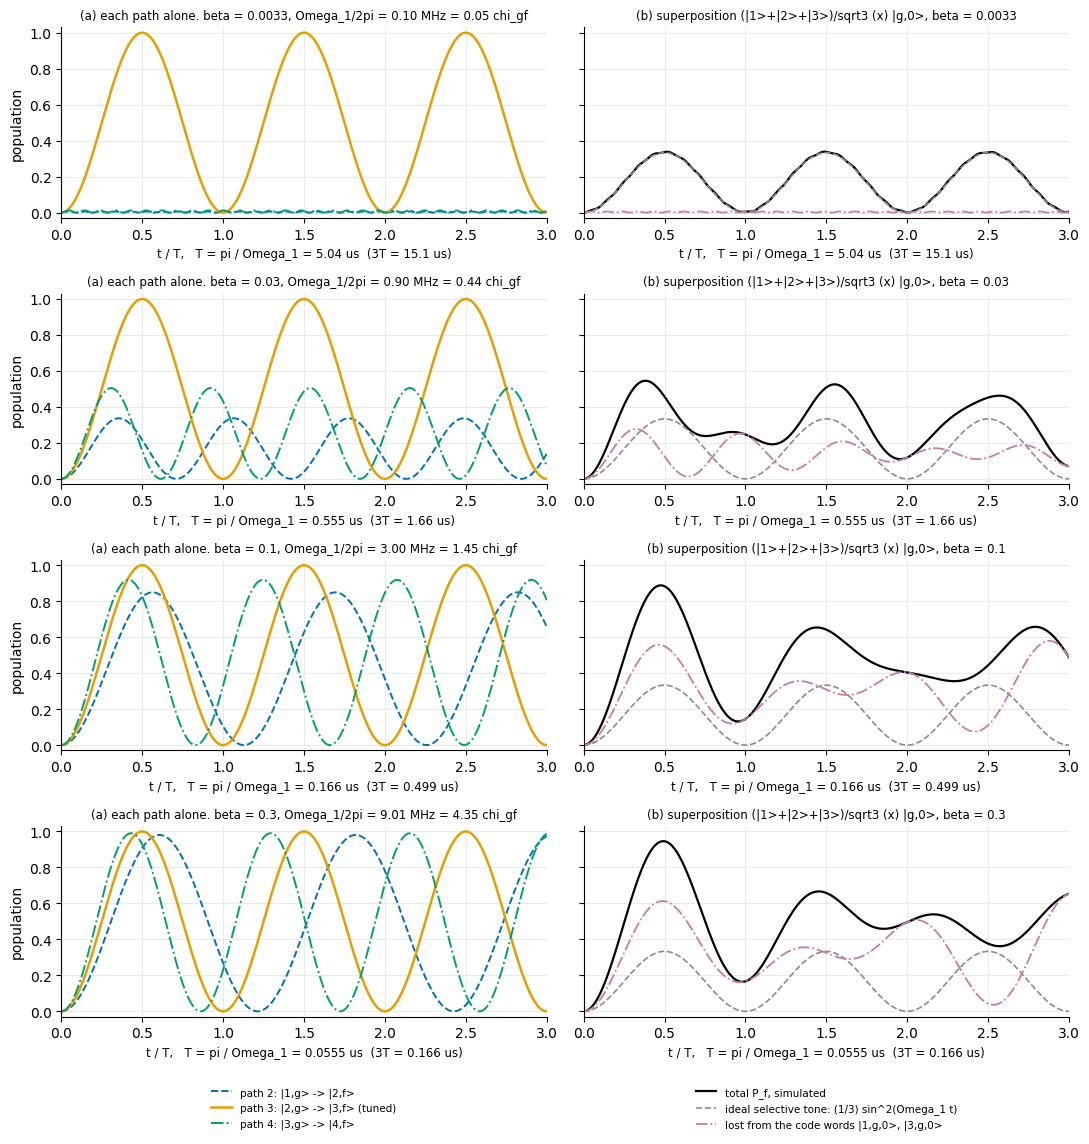

In [23]:
OKABE = {2: ("#0072B2", "--"), 3: ("#E69F00", "-"), 4: ("#009E73", "-.")}
fig, axes = plt.subplots(len(STRONG_BETAS), 2, figsize=(11, 2.7 * len(STRONG_BETAS)), sharey=True)
for row, beta in enumerate(STRONG_BETAS):
    s = strong[beta]
    tau = s["t"] / s["T"]
    ax = axes[row, 0]
    for n, (start, target) in PATHS.items():
        c, ls = OKABE[n]
        ax.plot(tau, s["run"][n][:, target], color=c, ls=ls, lw=1.8 if n == N_PATH else 1.4,
                label=f"path {n}: {LABELS[start][:-3]}> -> {LABELS[target][:-3]}>"
                      + (" (tuned)" if n == N_PATH else ""))
    ax.set_ylabel("population")
    ax.set_title(f"(a) each path alone. beta = {beta:g}, Omega_1/2pi = {mhz(omega_1(beta)):.2f} MHz "
                 f"= {omega_1(beta) / dev.chi_gf:.2f} chi_gf", fontsize=8.5)
    ax = axes[row, 1]
    P = s["P"]
    ax.plot(tau, P[:, IN_F].sum(axis=1), color="k", lw=1.6, label="total P_f, simulated")
    ax.plot(tau, np.sin(np.pi * tau) ** 2 / 3, color="0.55", lw=1.2, ls="--",
            label="ideal selective tone: (1/3) sin^2(Omega_1 t)")
    lost = 2 / 3 - P[:, PATHS[2][0]] - P[:, PATHS[4][0]]
    ax.plot(tau, lost, color="#CC79A7", lw=1.3, ls="-.", label="lost from the code words |1,g,0>, |3,g,0>")
    ax.set_title(f"(b) superposition (|1>+|2>+|3>)/sqrt3 (x) |g,0>, beta = {beta:g}", fontsize=8.5)
    for ax in axes[row]:
        ax.set_ylim(-0.03, 1.03)
        ax.set_xlim(0, 3)
        # each row has its own time scale: T = pi / Omega_1 on the tuned path
        ax.set_xlabel(f"t / T,   T = pi / Omega_1 = {s['T']:.3g} us  (3T = {3 * s['T']:.3g} us)", fontsize=8.5)
        tidy(ax)
fig.tight_layout()
for ax in axes[-1]:
    ax.legend(fontsize=7.5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.32))
fig.savefig("figures/fwm_tuning_strong_pump.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 7.** Strong pumping: compensated tone, closed system. One row per $\beta$; time in units of the tuned period
$T = \pi/\Omega_1$, so the orange curve looks the same in every row. Each panel's x label gives its $T$ in μs
(5.04, 0.555, 0.166 and 0.0555 μs from top to bottom).

- **(a) Each path started on its own:** the tuned path 3 (orange); path 2, from the code word $|1,g,0\rangle$ (blue
  dashed); path 4, from $|3,g,0\rangle$ (green dash-dot).
- **(b) The superposition** $(|1\rangle + |2\rangle + |3\rangle)/\sqrt3 \otimes |g,0\rangle$: the total $f$ population
  (black), the ideal selective tone $\tfrac13\sin^2(\Omega_1 t)$ (grey dashed), and the population that has left the
  two code words (pink dash-dot, at most 2/3).

What the rows show:

- **Paper's $\beta$ ($\Omega_1 = 0.05\,\chi_{gf}$): selective.** The neighbours move by at most 1.2% (Table 15), and
  black lies on grey.
- **$\beta = 0.03$ ($0.44\,\chi_{gf}$): the neighbours join in.** They swap 34% (path 2) and 50% (path 4). They run
  faster than the tuned path and out of step with it, so black loses its $\sin^2$ shape.
- **$\beta = 0.1$ and 0.3 ($1.5$ and $4.4\,\chi_{gf}$): three swaps at once.** Paths 2 and 4 swap 85% and 92% at
  $\beta = 0.1$, and 98% and 99% at 0.3. The tuned swap is still a perfect $\sin^2$ (orange). But the total $f$
  population peaks at 0.89 and 0.95 near $t = T/2$ and then wanders, as the three rates drift out of step. Up to 0.58 ($\beta = 0.1$) and
  0.65 ($\beta = 0.3$) of the 2/3 held by the code words has left them.
- **The bare tone fails on top of this.** Its tuned contrast is 0.55 at $\beta = 0.1$ and 0.12 at 0.3, from the Stark
  detuning (Table 15; Fig. 1, left).

**In short.** A strong pump does distort the transfer, but not by bending the tuned swap. It stops the tone from
choosing: the tone drives the neighbouring photon numbers too, each at its own rate. From any state that spans
several photon numbers (and a code word after an error always does), the result is a distorted, multi-frequency
transfer.

# 9. Conclusion

**The tone.** For the $n = 3$ path, $\omega_d/2\pi = 11483.21$ MHz from Eq. (2), or 4.8 kHz higher with the
higher-order terms of the DGRAPE drift (Table 1). At the paper's pump strength the Stark shift moves the resonance
down by a further 5.9 kHz.

**Closed system (§1–§6).** The working range (contrast $\ge 0.9$, crosstalk $\le 0.1$) is roughly
$\beta \approx 5\times10^{-4}$ to $1\times10^{-2}$, i.e. $\Omega_1/2\pi \approx 16$ to 300 kHz on the $n = 3$ path (Table 11). Inside it, $|2,g,0\rangle$ and $|3,f,0\rangle$ swap
completely, and the neighbouring paths lose less than 10%.

- **Upper end: crosstalk, not Stark detuning.** The first thing to fail is the neighbour $|3,g,0\rangle$, which the
  tone pushes toward $|4,f,0\rangle$ although it is off resonance by $\chi_{gf}/2\pi = 2.07$ MHz. Its loss reaches 10%
  at $\beta \approx 0.010$ ($\Omega_1/2\pi \approx 300$ kHz) and is the same for both tunings. It is the larger of the
  two neighbours because its matrix element, $\sqrt{8}$, is the largest. A rough rule: keep $\Omega_1$ below about
  $0.14\,\chi_{gf}$.
- **Stark detuning matters only later.** With the tone at the bare frequency, the contrast first drops below 0.9 at
  $\beta \approx 0.037$ ($\Omega_1/2\pi \approx 1.1$ MHz). Retuning the tone by $\delta_S(\beta)$ restores a full swap at
  every $\beta$ we tried, which confirms that the bare-tone loss is pure detuning.
- **Lower end: none in the closed model**, which swaps fully at any $\beta$. §7 computes it.

**With dissipation (§7).**

- **The swap is damped.** While it swaps, the pair leaks at $\Gamma_{\rm pair} = 2.5\,\kappa_a + \gamma_{ef}/2
  \approx (29\ \mu\text{s})^{-1}$, so the first peak is about $\exp(-\pi\Gamma_{\rm pair}/2\Omega_1)$: 0.92 at the
  paper's $\beta$, 0.76 at $\beta = 0.001$ (Table 12, Fig. 3).
- **Mixing.** Every jump moves the state out of its sealed pair: photon loss into a neighbouring pair, $f \to e$ into a
  dark $|e\rangle$ state the pump cannot touch, $e \to g$ into yet another pair. After 60 μs at the paper's $\beta$ the
  tuned pair keeps 0.22 of the population, and the state is spread over roughly eight states (purity 0.12; Fig. 4,
  Table 13). Across the whole Fock ladder, decay slides every photon number down, while only Fock 2 and 3 feel the
  pump (Fig. 5). Populations from a superposition still equal the average of single-Fock runs, with or without decay.
- **Decay sets the lower end.** A contrast of 0.9 now needs $\Omega_1/2\pi \ge 81$ kHz, against the crosstalk
  limit of 297 kHz: $\beta$ = 0.0027 to 0.0099 with decay only, 0.0031 to 0.0099 with all channels (Table 14, Fig. 6).
  The paper's $\beta$ (99 kHz on $n = 3$) gives 0.92, inside the window but close to its low edge. PReSPA never runs
  the swap alone anyway: its stage 2 carries the population onward.

**Strong pump (§8).** We went up to $\beta = 0.32$, where $\Omega_1 \approx 4.6\,\chi_{gf}$. With the compensated
tone the swap of $|2,g,0\rangle$ itself never distorts (Figs. 1 and A1). What fails is the choice of photon number.
Once $\Omega_1$ approaches $\chi_{gf}$, the tone also swaps the code words: $|1,g,0\rangle \to |2,f,0\rangle$ and
$|3,g,0\rangle \to |4,f,0\rangle$ move 34% and 50% at $\beta = 0.03$, and 98% and 99% at 0.3. From the superposition
$(|1\rangle + |2\rangle + |3\rangle)/\sqrt3$ there are then three swaps running at three rates ($\propto \sqrt n$), so
the transmon's $f$ population becomes a beat instead of a $\sin^2$, and up to 0.65 of the population leaves the code
words (Fig. 7, Table 15). A clean, selective correction needs $\Omega_1 \lesssim 0.14\,\chi_{gf}$, the same
limit as §6.

**Caveats.** (i) The $\beta \to \Omega_1$ conversion uses Eq. (C9). A direct count of the quartic terms gives rates
$\sqrt2$ smaller, which would move every $\beta$ above up by $\sqrt2$; the $\Omega_1$ values are the safer numbers to
carry over. (ii) Three transmon levels and RWA: leakage to higher transmon levels and non-RWA terms are not included. §8 estimates the leakage at under 1% up to $\beta = 0.3$, where the transmon Stark
shift reaches $0.18\,\alpha$; above that the model should not be trusted.
Dissipation is included in §7 only, with the Table I rates; the pump-induced heating of the all-channel set is the
paper's value for its full comb, used at every $\beta$. (iii) Only one tone is on. In the full comb the $n = 1$ and
$n = 5$ tones add their own crosstalk. Each of those tones alone is simulated in Appendix B: all three tones have a window; it is widest for $n = 1$ ($\beta$ = 0.0027 to 0.014, decay only) and narrowest for $n = 5$ (0.0030 to 0.0081) (Table B2, Fig. B1). (iv) Only stage 1 is simulated, so §7 describes a Rabi experiment, not the
correction cycle itself; `AQEC.master_equation.simulate_frame_ii` has both stages.

# Appendix A. Swap maps of the closed sweep

The §5 sweep also records the full time trace of the target population at every $\beta$ (`TAU`, `maps`,
Table 10). Fig. A1 shows them as two maps. It adds no new result to the main text: Fig. 2 already gives the
contrast and crosstalk read off these traces.

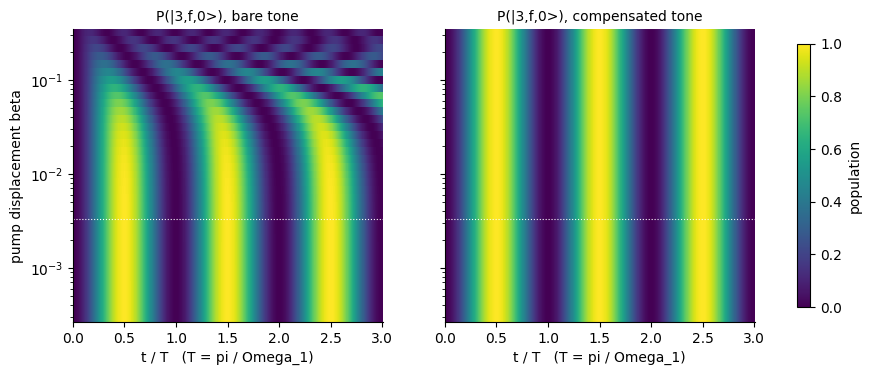

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, comp in zip(axes, (False, True)):
    im = ax.pcolormesh(TAU, BETAS, np.array(maps[comp]), shading="auto", cmap="viridis", vmin=0, vmax=1)
    ax.set_yscale("log")
    ax.axhline(BETA_PAPER, color="w", lw=0.8, ls=":")
    ax.set_xlabel("t / T   (T = pi / Omega_1)")
    ax.set_title(f"P(|3,f,0>), {'compensated' if comp else 'bare'} tone", fontsize=10)
    tidy(ax, grid=False)
axes[0].set_ylabel("pump displacement beta")
fig.colorbar(im, ax=axes, shrink=0.9, label="population")
fig.savefig("figures/fwm_tuning_map.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure A1.** Target population $P_{3f0}$ against time in units of the resonant period $T = \pi/\Omega_1$ (x) and
pump strength (y), starting in $|2,g,0\rangle$. Dotted white: the paper's $\beta$. Left, bare tone: above
$\beta \approx 0.02$ the Stark detuning speeds the swap up (the bright bands bend left) and lowers its peak.
Right, compensated tone: the same $\sin^2(\Omega_1 t)$ at every $\beta$, so the bands are straight. The top six rows (above $\beta = 0.1$) are the extension for §8. There the bare swap is fast and shallow, with
a peak of 0.11 in the top row, while the compensated bands stay straight up to $\beta = 0.32$: the tuned pair itself
never distorts.

# Appendix B. Figure 6 for the n = 1 and n = 5 tones

PReSPA's stage-1 comb has three tones, one per error state of the odd code: $n = 1$ ($|0,g,0\rangle \to |1,f,0\rangle$),
$n = 3$ ($|2,g,0\rangle \to |3,f,0\rangle$, the rest of this notebook) and $n = 5$ ($|4,g,0\rangle \to |5,f,0\rangle$).
This appendix repeats the dissipative sweep of §7.3 (Fig. 6, Table 14) for the other two tones, each on its own.
The simulation code is the same. `simulate`, `time_grid` and `open_model` take the path as `n_path` (default 3),
and Fig. 6 is drawn by `plot_open_sweep`, which is reused here.

## B.1 What changes with the path

Only three things depend on $n$. The Stark shift $\delta_S = -(4\alpha + \chi_{ge})\beta^2$ does not, because every
path changes $\hat n_a$ by 1 and $\hat q^\dagger\hat q$ by 2 (§5.1). So the bare and compensated tones relate as for $n = 3$.

1. **The swap rate**, $\Omega_1(n) = g\beta\sqrt{2n}$: $\Omega_1/2\pi$ = 17.3, 30.0 and 38.8 MHz × $\beta$ for $n$ = 1, 3, 5.
   At the same $\beta$, the $n = 5$ swap is 2.2 times faster than the $n = 1$ swap.
2. **The leak rate of the pair.** The start $|n{-}1,g,0\rangle$ loses a photon at $(n-1)\kappa_a$. The target
   $|n,f,0\rangle$ loses one at $n\kappa_a$, and its transmon decays at $\gamma_{ef}$. Averaged over half a swap, as in §7.1:
   $$
   \Gamma_{\rm pair}(n) = \tfrac12 (n-1)\kappa_a + \tfrac12 (n\kappa_a + \gamma_{ef}) = (n - \tfrac12)\,\kappa_a + \tfrac12\gamma_{ef},
   $$
   i.e. $(50\ \mu\text{s})^{-1}$, $(29\ \mu\text{s})^{-1}$ and $(20\ \mu\text{s})^{-1}$ for $n$ = 1, 3, 5. More photons
   leak faster. For $n = 1$ the transmon decay dominates, and for $n = 5$ the photon loss does.
3. **The neighbours.** The tone also drives the paths one step away, starting from $|n{-}2,g,0\rangle$ and
   $|n,g,0\rangle$. For every comb-1 tone these are code-word Fock states, so crosstalk damages the code directly:

| tone | neighbour start | its path | detuning | matrix element |
|---|---|---|:-:|:-:|
| $n = 1$ | $\lvert 1,g,0\rangle$ | 2 | $-\chi_{gf}$ | $\sqrt4$ |
| $n = 3$ | $\lvert 1,g,0\rangle$, $\lvert 3,g,0\rangle$ | 2, 4 | $+\chi_{gf}$, $-\chi_{gf}$ | $\sqrt4$, $\sqrt8$ |
| $n = 5$ | $\lvert 3,g,0\rangle$, $\lvert 5,g,0\rangle$ | 4, 6 | $+\chi_{gf}$, $-\chi_{gf}$ | $\sqrt8$, $\sqrt{12}$ |

   ($n = 1$ has only one neighbour, because no path 0 exists.)

## B.2 What to expect

Both edges of the window follow from closed forms used earlier:

- **Low end (decay):** $e^{-\Gamma_{\rm pair}T/2} \ge 0.9$ needs $\Omega_1 \ge \pi\Gamma_{\rm pair}/(2\ln(1/0.9))$ (§7.3).
- **High end (crosstalk):** the worst neighbour loses $4\Omega_{\rm nb}^2/(4\Omega_{\rm nb}^2 + \chi_{gf}^2)$ (§3.4). This
  reaches 0.1 at $\Omega_{\rm nb} = \chi_{gf}/6$, i.e. $\Omega_{\rm nb}/2\pi = 345$ kHz, whatever the path. Here
  $\Omega_{\rm nb} = g\beta\sqrt{2n'}$ is the coupling on the neighbour's path $n'$.

**Table B1.** Closed-form estimates of the working range (decay only, compensated tone).

| tone | $1/\Gamma_{\rm pair}$ | low end: $\beta$ ($\Omega_1/2\pi$) | worst neighbour | high end: $\beta$ ($\Omega_1/2\pi$) | window |
|---|:-:|:-:|:-:|:-:|:-:|
| $n = 1$ | 50 μs | 0.0027 (47 kHz) | $\lvert 1,g,0\rangle$, $\sqrt4$ | 0.0141 (244 kHz) | factor 5.2 |
| $n = 3$ | 29 μs | 0.0027 (82 kHz) | $\lvert 3,g,0\rangle$, $\sqrt8$ | 0.0099 (299 kHz) | factor 3.7 |
| $n = 5$ | 20 μs | 0.0030 (117 kHz) | $\lvert 5,g,0\rangle$, $\sqrt{12}$ | 0.0081 (315 kHz) | factor 2.7 |

The two edges move in opposite directions with $n$. A larger $n$ leaks faster, which raises the low end. It also has
neighbours with larger matrix elements, which lowers the high end. So the window narrows up the ladder, but at these
thresholds it stays open on all three paths. The cell below runs the full simulation to check.

**Cost.** Two paths × 37 pump strengths × (3 open runs + 1–2 closed crosstalk runs), about four minutes. One cell
first reruns the $n = 3$ sweep at every fifth $\beta$ through the new code and asserts that it reproduces §7.3. A
second check covers the truncation, because $n = 5$ reaches Fock 6, and Fock 7 by heating. It compares $N_C = 8$
with 10.

In [25]:
PATH_NEIGHBOURS = {1: [1], 3: [1, 3], 5: [3, 5]}   # Fock n' of the |n',g,0> starts one path away (code-word states)


def gamma_pair(n):
    # mean leak rate of the pair |n-1,g,0>, |n,f,0> over half a swap (§7.1): ((n-1) kappa_a + n kappa_a + gamma_ef) / 2
    return (n - 0.5) * dev.kappa_a + 0.5 / dev.T1_EF


def open_sweep_for_path(n, betas=BETAS, n_c=N_C, runs=OPEN_RUNS, closed=True):
    # The §7.3 sweep (columns of open_sweep) for the tone on path n: |n-1,g,0> -> |n,f,0>
    models = {ch: open_model(n_c, ch, n_path=n) for ch in {ch for ch, _ in runs}}
    j0, j1 = index(n - 1, G, 0, N_C, N_R), index(n, F, 0, N_C, N_R)          # the pair, closed space
    nbrs = {f"|{k},g,0>": index(k, G, 0, N_C, N_R) for k in PATH_NEIGHBOURS[n]}
    records = []
    for beta in betas:
        T = np.pi / omega_1(beta, n)
        t = np.linspace(0, 3 * T, 1201)                                       # as §7.3
        rec = {"beta": beta}
        for ch, comp in runs:                                                 # open contrast, max P_target
            m = models[ch]
            P = populations(simulate_open(beta, rho_basis(m.i0, m.d), t, m, compensate=comp))
            rec[f"{ch}, {'compensated' if comp else 'bare'}"] = P[:, m.i1].max()
        rec["decay, estimate"] = np.exp(-gamma_pair(n) * np.pi / (2 * omega_1(beta, n)))
        if closed:                                                            # closed contrast and crosstalk, as §5
            tc, _ = time_grid(beta, n_path=n)
            rec["closed, compensated"] = simulate(beta, j0, tc, compensate=True, n_path=n)[:, j1].max()
            for name, s in nbrs.items():
                rec["xt " + name] = 1 - simulate(beta, s, tc, compensate=True, n_path=n)[:, s].min()
            rec["crosstalk, compensated"] = max(rec["xt " + name] for name in nbrs)
        records.append(rec)
    return pd.DataFrame(records)


# Check: the generalized code reproduces the n = 3 sweep of §7.3 (every fifth beta)
sub = open_sweep.iloc[::5].reset_index(drop=True)
chk = open_sweep_for_path(3, betas=sub.beta.values)
cols = ["closed, compensated", "decay, bare", "decay, compensated", "all, compensated", "decay, estimate",
        "crosstalk, compensated"]
dev_n3 = np.abs(chk[cols].values - sub[cols].values).max()
print(f"n = 3 rerun vs open_sweep: largest difference {dev_n3:.1e} over {len(sub)} betas")
assert dev_n3 < 1e-6

path_sweeps = {n: open_sweep_for_path(n) for n in (1, 5)}

# Truncation: n = 5 reaches Fock 6 (and 7 by heating); N_C = 8 against 10, all channels
for beta in (BETA_PAPER, 0.01):
    c8, c10 = (open_sweep_for_path(5, betas=[beta], n_c=nc, runs=(("all", True),), closed=False)
               ["all, compensated"].iloc[0] for nc in (N_C, 10))
    print(f"n = 5, beta = {beta}: contrast {c8:.5f} at N_C = {N_C}, {c10:.5f} at N_C = 10")
    assert abs(c8 - c10) < 1e-3

n = 3 rerun vs open_sweep: largest difference 0.0e+00 over 8 betas


n = 5, beta = 0.0033: contrast 0.90059 at N_C = 8, 0.90059 at N_C = 10


n = 5, beta = 0.01: contrast 0.96578 at N_C = 8, 0.96578 at N_C = 10


In [26]:
COMP_RUNS = (("decay, compensated", "compensated"), ("all, compensated", "compensated"))   # no bare crosstalk here
path_ranges = {1: open_range(path_sweeps[1], n_path=1, runs=COMP_RUNS), 3: open_range_table,
               5: open_range(path_sweeps[5], n_path=5, runs=COMP_RUNS)}
rows = []
for n, tab in path_ranges.items():
    for run in ("decay, compensated", "all, compensated"):
        r = tab.loc[run]
        rows.append({"path": f"n = {n}: |{n - 1},g,0> -> |{n},f,0>", "run": run,
                     "beta low": r[LOW_COL], "beta high": r["beta high"],
                     "high end set by": r["high end set by"],
                     "Omega_1/2pi low (kHz)": r["Omega_1/2pi low (kHz)"], "Omega_1/2pi high (kHz)": r["Omega_1/2pi high (kHz)"],
                     "high / low": r["high / low"],
                     "largest swept contrast": r["largest swept contrast"],
                     "contrast at paper's beta": r["contrast at paper's beta"]})
path_range_table = pd.DataFrame(rows).set_index(["path", "run"])
display(path_range_table.style.format({c: "{:.4g}" for c in path_range_table.columns if c != "high end set by"})
        .set_caption(
    f"Table B2. Working range of each comb-1 tone with dissipation, same criteria as Table 14: open contrast >= "
    f"{CONTRAST_MIN} and closed crosstalk <= {XT_MAX}, edges interpolated in log beta. 'high / low' below 1 means "
    "the window has closed: no pump strength passes both tests. The n = 3 rows are Table 14."))
for n in (1, 3, 5):
    s = open_sweep if n == 3 else path_sweeps[n]
    strong = s.beta >= 1e-3
    err = np.abs(s["decay, estimate"] - s["decay, compensated"])
    k = s["decay, bare"].idxmax()
    print(f"n = {n}: bare tone peaks at {s['decay, bare'][k]:.3f} (beta = {s.beta[k]:.4f}); estimate within "
          f"{err[strong].max():.3f} for beta >= 1e-3, {err.max():.3f} overall; 1/Gamma_pair = {1 / gamma_pair(n):.1f} us")

n = 1: bare tone peaks at 0.951 (beta = 0.0081); estimate within 0.009 for beta >= 1e-3, 0.063 overall; 1/Gamma_pair = 50.5 us
n = 3: bare tone peaks at 0.965 (beta = 0.0119); estimate within 0.006 for beta >= 1e-3, 0.045 overall; 1/Gamma_pair = 29.0 us
n = 5: bare tone peaks at 0.969 (beta = 0.0144); estimate within 0.007 for beta >= 1e-3, 0.045 overall; 1/Gamma_pair = 20.3 us


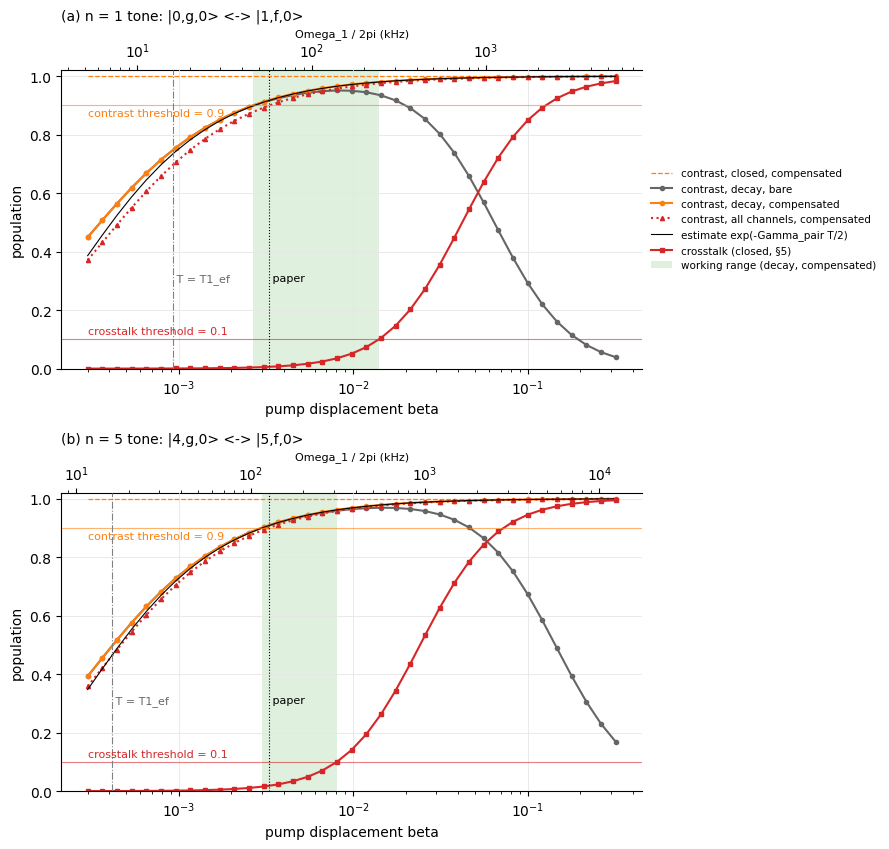

In [27]:
fig, axes = plt.subplots(2, 1, figsize=(9, 8.6))
for ax, n, tag in zip(axes, (1, 5), "ab"):
    r = path_ranges[n].loc["decay, compensated"]
    plot_open_sweep(ax, path_sweeps[n], (r[LOW_COL], r["beta high"]), n_path=n,
                    legend=(n == 1))
    ax.set_title(f"({tag}) n = {n} tone: |{n - 1},g,0> <-> |{n},f,0>", fontsize=10, loc="left")
fig.tight_layout()
fig.savefig("figures/fwm_tuning_open_sweep_paths.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure B1.** Fig. 6 for the other two comb-1 tones: (a) $n = 1$, $|0,g,0\rangle \rightleftarrows |1,f,0\rangle$;
(b) $n = 5$, $|4,g,0\rangle \rightleftarrows |5,f,0\rangle$. Same layout and symbols as Fig. 6. The top axis is
$\Omega_1/2\pi$ on each panel's own path, so the same $\beta$ maps to a faster swap in (b). Dashed orange: closed
system, compensated. Circles: decay only, compensated (orange) and bare (grey). Red triangles: all channels,
compensated. Thin black: the estimate $\exp(-\Gamma_{\rm pair}T/2)$. During a swap the population moves back and forth
between the start $|n{-}1,g,0\rangle$ and the target $|n,f,0\rangle$, which leak at different rates; $\Gamma_{\rm pair}(n)$
is the average of those two rates, and the line is the fraction that survives this averaged leak for half a swap
period. Red squares: the closed crosstalk of the worst neighbour ($|1,g,0\rangle$ in (a), $|5,g,0\rangle$ in (b)).
Thin horizontal lines: the pass thresholds, contrast at least 0.9 (orange) and crosstalk at most 0.1 (red). Green
band: the working range, decay only, compensated tone (Table B2). Dotted: the paper's $\beta$;
dash-dot: the $\beta$ at which one swap period on this path equals $T_{1,ef}$.

**Reading Figure B1 and Table B2.**

- **$n = 1$ has the widest window:** $\beta$ = 0.0027 to 0.0140 ($\Omega_1/2\pi$ = 46 to 243 kHz), a factor 5.3,
  with decay only. The pair holds at most one photon, so it leaks slowly, $1/\Gamma_{\rm pair}$ = 50 μs. Its only
  neighbour has the smallest matrix element, $\sqrt4$. All channels narrow the window to 0.0033–0.0140 (factor 4.2).
  Here dephasing and heating cost relatively more than for $n = 3$, because photon loss no longer dominates the leak.
- **$n = 5$ has the narrowest window:** $\beta$ = 0.0030 to 0.0081 (116 to 313 kHz), a factor 2.7; with all
  channels 0.0033–0.0081 (factor 2.4). The neighbour $|5,g,0\rangle$ (path 6, $\sqrt{12}$) sets the high end.
- **Table B1 predicted all six edges** to within 0.0001 in $\beta$.
- **The trend.** Going up the ladder, the leak rate grows as $(n - \tfrac12)\kappa_a$ and the worst neighbour's
  coupling as $\sqrt{2(n+1)}$. Both narrow the window, from a factor 5.3 ($n = 1$) to 2.7 ($n = 5$).
- **The paper's $\beta = 0.0033$** gives nearly the same decay-only contrast on all three paths: 0.918 ($n = 1$),
  0.917 ($n = 3$), 0.909 ($n = 5$), all above 0.9. With all channels it gives 0.899, 0.906 and 0.900, so on
  $n = 1$ and $n = 5$ the paper's pump sits right at the low edge. A faster swap (larger $\Omega_1$) offsets a faster leak, and
  $\Gamma_{\rm pair}/\Omega_1 \propto (n + 1.7)/\sqrt n$ (with $\gamma_{ef}/2 = 2.2\,\kappa_a$) changes by only 10% between $n = 1$ and 5.
- **The bare tone** fails earliest on $n = 1$. The Stark shift $\delta_S$ is the same on every path, but
  $\Omega_1$ is smallest there, so $\delta_S/2\Omega_1$ is largest. The bare contrast peaks at 0.951 ($\beta = 0.008$) on $n = 1$ and at 0.969 ($\beta = 0.014$; 0.965 at 0.012 for $n = 3$) on $n = 5$.
- **The estimate** $\exp(-\Gamma_{\rm pair}T/2)$ is about as good as for $n = 3$ (0.006): within 0.009 ($n = 1$) and 0.007 ($n = 5$) of the
  simulation for $\beta \ge 10^{-3}$.

As in §7.3, the 0.9 test asks for one standalone swap of a single tone. PReSPA runs all three comb-1 tones together
with stage 2, so this appendix bounds each tone's own clean regime. It does not predict the correction rate.

# 10. Comb 2: the one-way step |3,f,0⟩ → |3,g,1⟩ → |3,g,0⟩

**Where this fits.** Everything above is about stage 1 of PReSPA: a comb-1 tone adds the lost photon back and puts the
transmon in $|f\rangle$, $|2,g,0\rangle \to |3,f,0\rangle$. Stage 2 has to empty the transmon again, *without* sending
the photon back. A **comb-2** tone does it through the four-wave-mixing operator $\hat q^2\hat r^\dagger$: it takes the
transmon from $|f\rangle$ to $|g\rangle$ and puts one photon in the readout,

$$
|n,f,0\rangle \;\to\; |n,g,1\rangle \;\xrightarrow{\ \kappa_r\ }\; |n,g,0\rangle .
$$

The readout then loses its photon at $\kappa_r/2\pi = 0.58$ MHz, which is fast: $1/\kappa_r = 0.27$ μs. That leak is the
whole point. It carries the entropy away, and once the photon has left, nothing brings the system back to
$|n,f,0\rangle$. So the step is **one-way**, unlike the comb-1 swap of §4–§8, which goes back and forth.

**Scope.** One comb-2 tone, tuned to $n = 3$, alone (comb 1 off). Start in $|3,f,0\rangle$, which is where stage 1 leaves
the system. **Open system only**: the readout leak is what makes this step work, so a closed run would miss the point.
Same model, frame, space and solver as §3 (`simulate_open`, unchanged), decay set for the main results and all
channels for one comparison curve (Table 3).

## 10.0 Why a weak pump gives a one-way step

Ignore every jump that leaves the pair. Then the pair $\{|3,f,0\rangle, |3,g,1\rangle\}$ is a two-level problem in which
one level leaks. With coupling $\Omega_2$, leak rates $\Gamma_f$ (of $|3,f,0\rangle$) and $\Gamma_g$ (of $|3,g,1\rangle$), and the
tone on resonance, the amplitudes follow

$$
\frac{d}{dt}\begin{pmatrix} c_f \\ c_g \end{pmatrix}
= \begin{pmatrix} -\Gamma_f/2 & -i\Omega_2 \\ -i\Omega_2 & -\Gamma_g/2 \end{pmatrix}
\begin{pmatrix} c_f \\ c_g \end{pmatrix},
\qquad
\lambda_\pm = -\frac{\Gamma_f + \Gamma_g}{4} \pm \sqrt{\Big(\frac{\Gamma_g - \Gamma_f}{4}\Big)^2 - \Omega_2^2}.
$$

- **Weak pump, $\Omega_2 < \Omega_c = (\Gamma_g - \Gamma_f)/4$:** both $\lambda$ are real. $P_f = |c_f|^2$ only ever falls. Nothing comes
  back; the step is **one-way** (overdamped). For $\Omega_2 \ll \Omega_c$ the rate is $\approx 4\Omega_2^2/\kappa_r$: slow.
- **Strong pump, $\Omega_2 > \Omega_c$:** the $\lambda$ are complex. The population swings between $|3,f,0\rangle$ and
  $|3,g,1\rangle$ while it drains, so some of it comes **back** to $|3,f,0\rangle$ (underdamped). The drain rate stops
  growing at $(\Gamma_f + \Gamma_g)/2 \approx \kappa_r/2$.
- **Critical, $\Omega_2 = \Omega_c$:** the fastest step that is still one-way. Here $\Gamma_g - \Gamma_f = \kappa_r - \gamma_{ef}$
  (photon loss is the same for both), so $\Omega_c \approx \kappa_r/4$, the paper's choice (App. B).

No jump lands back in the pair (photon loss goes to $n = 2$, $f\to e$ decay to $|3,e,0\rangle$, the readout leak to
$|3,g,0\rangle$, which the tone does not touch). So for the decay set this 2×2 solution is **exact**, not an
approximation; §10.2 tests it.

| subsection | goal |
|---|---|
| 10.1 | the comb-2 term, its rate and Stark shift, and the critical pump $\beta_c$ |
| 10.2 | checks |
| 10.3 | one-way vs oscillating, in time (Fig. 8) and over $\beta$ (Fig. 9) |
| 10.4 | photon-number heat map (Fig. 10, as Fig. 5) |
| 10.5 | sweep over the pump strength and the working range (Fig. 11, as Fig. 6) |
| 10.6 | strong pump and crosstalk (Fig. 12, as Fig. 7) |
| 10.7 | summary |

## 10.1 The comb-2 term

**The operator.** Expanding the junction cosine (App. C, Eq. C6) gives, next to the comb-1 term, the term

$$
\hat H_{\rm FWM2}(t) = g_2\,\beta\;\hat q^{2}\hat r^\dagger\,e^{i\Delta_2 t} + \text{h.c.}
$$

It does not touch the storage, so its matrix element $\langle n,g,1|\hat q^2\hat r^\dagger|n,f,0\rangle = \sqrt2$ is the
same on every path $n$, and so is the rate $\Omega_2 = g_2\beta\sqrt2$. The tone picks the photon number only through
its frequency: $|n,f\rangle$ sits $n\chi_{gf}$ lower, so tone $n$ is at $\omega_r - \omega_{gf} + n\chi_{gf}$.

**The coefficient $g_2$.** Same convention as $g$ in §1.2: Eq. (C9) gives $\Omega_2 = \sqrt{\chi_{qr}\Delta_{\rm Ss2}}$
with $\Delta_{\rm Ss2} = 2\alpha|\beta|^2$, so $g_2 = \sqrt{\alpha\chi_{qr}}$. The same factor-$\sqrt2$ caveat applies.

**Stark shift.** We reuse $\hat H_S$ of §1.3 (`STARK_DIAG`). It moves $|3,g,1\rangle$ relative to $|3,f,0\rangle$ by
$+(4\alpha - \chi_{qr})|\beta|^2$. "Compensated" again means the tone follows that shift.

**Code.** `open_model_comb2(n_c, channels)` takes `open_model` of §3.5 and swaps the pump couplings for those of
$\hat q^2\hat r^\dagger$; the pair becomes `i0` $= |3,f,0\rangle$, `i1` $= |3,g,1\rangle$. `simulate_open` is used
unchanged; since it multiplies the couplings by `G_FWM * beta`, they are stored pre-scaled by `G_FWM2 / G_FWM`.
`pair_matrix` builds the 2×2 generator of §10.0 (with any detuning, for any path); `pair_populations`,
`slow_rate` and `efficiency` read off its solution, its slower decay rate, and the share of the population that
leaves through the readout, $\kappa_r\int_0^\infty P_{3g1}\,dt$ (a Lyapunov equation, no time stepping).

In [28]:
from scipy.integrate import trapezoid
from scipy.linalg import solve_continuous_lyapunov

N_PATH_2 = 3                                          # the comb-2 tone on path n = 3: |3,f,0> -> |3,g,1>
BETA_PAPER_2 = 0.011                                  # PRX Table II, comb 2
G_FWM2 = np.sqrt(dev.alpha_q * dev.chi_qr)            # Eq. (C9) convention, as G_FWM with chi_ge -> chi_qr
B_FWM2 = ops["q"] @ ops["q"] @ ops["r"].conj().T     # q^2 r', the comb-2 operator: |n,f,m> -> |n,g,m+1>
k0, k1 = index(N_PATH_2, F, 0, N_C, N_R), index(N_PATH_2, G, 1, N_C, N_R)   # |3,f,0> (start), |3,g,1> (target)
k_done = index(N_PATH_2, G, 0, N_C, N_R)              # |3,g,0>, reached when the readout photon leaks out


def omega_2(beta):
    # comb-2 rate (rad/us): g2 beta <n,g,1| q^2 r' |n,f,0> = g2 beta sqrt(2), the same on every path n
    return G_FWM2 * beta * np.sqrt(2)


def open_model_comb2(n_c, channels="decay", n_path=N_PATH_2):
    # open_model with the pump swapped for one comb-2 tone on path n_path: |n,f,0> -> |n,g,1>.
    # simulate_open multiplies the couplings by G_FWM * beta, so they are stored pre-scaled by G_FWM2 / G_FWM.
    m = open_model(n_c, channels)
    o = operators(n_c, N_R)
    B = o["q"] @ o["q"] @ o["r"].conj().T
    rows, cols = np.nonzero(B)
    s0, s1 = index(n_path, F, 0, n_c, N_R), index(n_path, G, 1, n_c, N_R)
    return SimpleNamespace(**{**vars(m), "rows": rows, "cols": cols,
                              "a_vals": (G_FWM2 / G_FWM) * B[rows, cols],
                              "i0": s0, "i1": s1, "de_bare": m.e_d[s1] - m.e_d[s0]})


MODEL2 = {ch: open_model_comb2(N_C, ch) for ch in ("decay", "all")}


def pair_matrix(beta, model, start, compensate=False):
    # The no-jump 2x2 generator of the pair (start = |n',f,0>, its partner |n',g,1>), in the frame of the tone:
    # d/dt (c_f, b) = M (c_f, b). Exact for the decay set, where no jump lands back in the pair (§10.2).
    m = model
    en = m.e_d + m.stark * beta ** 2
    Delta = -((en[m.i1] - en[m.i0]) if compensate else m.de_bare)
    k = np.flatnonzero(m.cols == start)[0]
    Om = G_FWM * beta * abs(m.a_vals[k])              # = omega_2(beta)
    w = en[m.rows[k]] - en[start] + Delta             # detuning of this pair from the tone
    Gf, Gg = m.gdiag[start], m.gdiag[m.rows[k]]
    return np.array([[-Gf / 2, -1j * Om], [-1j * Om, -1j * w - Gg / 2]])


def pair_populations(beta, t, model=None, start=None, compensate=False):
    # (P_f(t), P_g1(t)) of the pair from the 2x2 solution
    model = MODEL2["decay"] if model is None else model
    start = model.i0 if start is None else start
    M = pair_matrix(beta, model, start, compensate)
    lam, V = np.linalg.eig(M)
    c = V @ (np.exp(np.outer(lam, t)) * np.linalg.solve(V, [1.0, 0.0])[:, None])
    return np.abs(c) ** 2


def slow_rate(beta, compensate=True):
    # population decay rate of the slower eigenmode of the pair, -2 Re lambda (1/us)
    return -2 * np.linalg.eigvals(pair_matrix(beta, MODEL2["decay"], k0, compensate)).real.max()


def efficiency(beta, compensate=True):
    # kappa_r * integral of P_g1 dt from the 2x2 model: the share that leaves through the readout into |3,g,0>
    M = pair_matrix(beta, MODEL2["decay"], k0, compensate)
    X = solve_continuous_lyapunov(M.conj().T, -np.diag([0.0, 1.0]))
    return dev.kappa_r * X[0, 0].real


m2 = MODEL2["decay"]
GAMMA_F2, GAMMA_G2 = m2.gdiag[k0], m2.gdiag[k1]
BETA_CRIT_2 = (GAMMA_G2 - GAMMA_F2) / 4 / omega_2(1.0)     # Omega_2 = (Gamma_g1 - Gamma_f)/4: critical damping
STARK_2 = (STARK_DIAG[k1] - STARK_DIAG[k0])                # pair shift / beta^2
w_eq_2 = dev.omega_r - dev.omega_gf + N_PATH_2 * dev.chi_gf  # Eq. (3) tone, w = -n chi_gf in frame (ii)
w_bare_2 = dev.omega_r - 2 * dev.omega_q + m2.de_bare        # the same from the DGRAPE drift

print(f"<3,g,1| q^2 r' |3,f,0>     = {B_FWM2[k1, k0].real:.4f}   (sqrt 2 = {np.sqrt(2):.4f})")
print(f"Omega_2 / beta             = {mhz(omega_2(1.0)):.2f} MHz  (sqrt(2 alpha chi_qr)/2pi)")
print(f"Table II check, beta = {BETA_PAPER_2}: Omega_2/2pi = {1e3 * mhz(omega_2(BETA_PAPER_2)):.0f} kHz (paper: 190 "
      f"estimated, 160 measured), transmon Stark 2 alpha beta^2/2pi = "
      f"{1e3 * mhz(2 * dev.alpha_q * BETA_PAPER_2 ** 2):.1f} kHz (paper: 32)")
print(f"delta_S / beta^2           = {mhz(STARK_2):.1f} MHz  ((4 alpha - chi_qr)/2pi = "
      f"{mhz(4 * dev.alpha_q - dev.chi_qr):.1f}); at the paper's beta {1e3 * mhz(STARK_2 * BETA_PAPER_2 ** 2):.1f} kHz")
print(f"leaving rates: |3,f,0> {GAMMA_F2:.4f} us^-1 (3 kappa_a + gamma_ef), |3,g,1> {GAMMA_G2:.4f} us^-1 "
      f"(3 kappa_a + kappa_r)")
print(f"critical damping: Omega_2/2pi = (kappa_r - gamma_ef)/(4 2pi) = {1e3 * mhz(omega_2(BETA_CRIT_2)):.1f} kHz, "
      f"beta_c = {BETA_CRIT_2:.5f}; paper's beta = {BETA_PAPER_2 / BETA_CRIT_2:.2f} beta_c")
print(f"tone: Eq. (3) omega_r - omega_gf + 3 chi_gf = {mhz(w_eq_2):.4f} MHz; DGRAPE drift "
      f"{1e3 * mhz(w_bare_2 - w_eq_2):+.2f} kHz; Stark-compensated at the paper's beta "
      f"{1e3 * mhz(w_bare_2 - w_eq_2 + STARK_2 * BETA_PAPER_2 ** 2):+.2f} kHz")

<3,g,1| q^2 r' |3,f,0>     = 1.4142   (sqrt 2 = 1.4142)
Omega_2 / beta             = 17.42 MHz  (sqrt(2 alpha chi_qr)/2pi)
Table II check, beta = 0.011: Omega_2/2pi = 192 kHz (paper: 190 estimated, 160 measured), transmon Stark 2 alpha beta^2/2pi = 32.5 kHz (paper: 32)
delta_S / beta^2           = 536.0 MHz  ((4 alpha - chi_qr)/2pi = 536.0); at the paper's beta 64.9 kHz
leaving rates: |3,f,0> 0.0543 us^-1 (3 kappa_a + gamma_ef), |3,g,1> 3.6663 us^-1 (3 kappa_a + kappa_r)
critical damping: Omega_2/2pi = (kappa_r - gamma_ef)/(4 2pi) = 143.7 kHz, beta_c = 0.00825; paper's beta = 1.33 beta_c
tone: Eq. (3) omega_r - omega_gf + 3 chi_gf = 1899.6900 MHz; DGRAPE drift -11.40 kHz; Stark-compensated at the paper's beta +53.45 kHz


**Reading the output.**

- **Table II is reproduced:** $\beta = 0.011$ gives $\Omega_2/2\pi$ = 192 kHz (paper: 190 estimated, 160 measured) and a
  transmon Stark shift of 32.5 kHz (paper: 32).
- **The critical pump** is $\Omega_c/2\pi = (\kappa_r - \gamma_{ef})/(4\cdot 2\pi) = 143.7$ kHz, i.e. $\beta_c = 0.00825$.
  The paper's $\beta = 0.011$ is $1.33\,\beta_c$: just on the oscillating side (with the measured 160 kHz it would be
  $1.11\,\beta_c$).
- **The two leak rates are very different:** $|3,g,1\rangle$ leaves at 3.67 μs⁻¹, mostly $\kappa_r$; $|3,f,0\rangle$ at
  0.054 μs⁻¹ ($3\kappa_a + \gamma_{ef}$), 67 times slower.
- **The Stark shift of the pair** is 65 kHz at the paper's $\beta$, small against the readout linewidth $\kappa_r/2\pi$ = 580 kHz,
  so the bare and compensated tones barely differ there (§10.5).

## 10.2 Checks

Each check compares the simulation with a result it does not use itself. Table 16 lists the largest difference
found and the tolerance it must stay under.

**1. The 2×2 solution.**
- *Compared:* $P(|n,f,0\rangle)$ and $P(|n,g,1\rangle)$ from `simulate_open` (48 states, every jump) against
  `pair_populations`, the 2×2 solution of §10.0.
- *Why they must agree:* every decay-set jump takes population out of the pair, and none brings it back. Photon loss
  goes to $n - 1$, $f \to e$ decay goes to $|n,e,0\rangle$, and the readout leak goes to $|n,g,0\rangle$, which the
  tone does not touch. So, inside the pair, the 2×2 equation is exact.
- *Where:* 4 pump strengths (0.002, $\beta_c$, 0.011, 0.05: one-way, critical and oscillating), both tunings, and
  3 starts. The starts are the tuned $|3,f,0\rangle$ and its neighbours $|2,f,0\rangle$ and $|4,f,0\rangle$. The
  neighbours are detuned, so they also test the detuning term.
- *Why it matters:* every closed-form curve in §10 comes from this 2×2 model: $\beta_c$, the efficiency, the
  $t_{99}$ estimate and the crosstalk estimate. Tolerance $10^{-7}$.

**2–4. A valid density matrix.**
- *Compared:* $\hat\rho$ after 60 μs (start $|3,f,0\rangle$, paper's $\beta$, all channels) against three properties
  every density matrix has:
  - trace 1, i.e. total probability is kept;
  - Hermitian, $\hat\rho = \hat\rho^\dagger$;
  - no negative eigenvalue, i.e. no negative probability.
- *Why:* all channels include heating and dephasing, the jump operators most likely to be wired wrong. A dropped or
  doubled jump term breaks the trace, a wrong phase breaks Hermiticity, and a mismatched pair of terms makes an
  eigenvalue negative. Tolerances $10^{-10}$, $10^{-12}$, $10^{-9}$.

**5. Truncation.**
- *Compared:* $P(|4,f,0\rangle)$ over 20 μs at $n_c$ = 8 against the same run at $n_c$ = 10 ($\beta = 0.05$, all
  channels).
- *Why:* $|4,f,0\rangle$ is the start with the most photons used below, and storage heating can add one more. If 8
  levels were too few, the extra levels would change the result. Tolerance $10^{-6}$.

**6. Superposition = mean of Fock runs.**
- *Compared:* the populations from the start $(|2\rangle + |3\rangle + |4\rangle)/\sqrt3\otimes|f,0\rangle$ against
  the average of the three runs started in $|2,f,0\rangle$, $|3,f,0\rangle$ and $|4,f,0\rangle$ alone ($\beta = 0.05$,
  all channels).
- *Why they must agree:* the tone never changes the photon number, and each jump moves one basis state to one other.
  So the coherences between photon numbers never feed into the populations.
- *Why it matters:* §10.6 compares a superposition run with a reference built from single-path runs. Tolerance
  $10^{-7}$.

In [29]:
checks2 = []

# 1. The 2x2 solution of the pair is exact for the decay set: tuned pair and the two neighbours, both tunings
err = 0.0
for beta in (0.002, BETA_CRIT_2, BETA_PAPER_2, 0.05):
    t = np.linspace(0, 8 / slow_rate(beta), 401)
    for comp in (False, True):
        for start in (k0, index(2, F, 0, N_C, N_R), index(4, F, 0, N_C, N_R)):
            P = populations(simulate_open(beta, rho_basis(start, m2.d), t, m2, compensate=comp))
            k = np.flatnonzero(m2.cols == start)[0]
            err = max(err, np.abs(P[:, [start, m2.rows[k]]] - pair_populations(beta, t, m2, start, comp).T).max())
checks2.append(("2x2 pair solution, decay set", "max |P_sim - P_2x2|, 4 betas x 2 tunings x 3 paths", err, 1e-7))

# 2. Physicality after a long run: paper's beta, all channels, 60 us
rho_end = simulate_open(BETA_PAPER_2, rho_basis(k0, m2.d), np.array([0.0, T_OPEN]), MODEL2["all"], compensate=True)[-1]
checks2.append(("trace", "|Tr rho - 1| at 60 us, all channels", abs(np.trace(rho_end) - 1), 1e-10))
checks2.append(("Hermitian", "max |rho - rho'| at 60 us", np.abs(rho_end - rho_end.conj().T).max(), 1e-12))
checks2.append(("positive", "-(smallest eigenvalue) at 60 us",
                -np.linalg.eigvalsh(0.5 * (rho_end + rho_end.conj().T)).min(), 1e-9))

# 3. Truncation: the n = 4 neighbour (reaches Fock 4 only, plus heating) at N_C = 8 and 10, all channels
t = np.linspace(0, 20.0, 201)
p8, p10 = (populations(simulate_open(0.05, rho_basis(index(4, F, 0, nc, N_R), dim(nc, N_R)), t,
                                     open_model_comb2(nc, "all"), compensate=True))[:, index(4, F, 0, nc, N_R)]
           for nc in (N_C, 10))
checks2.append(("truncation", "max |P_4f0(N_C = 8) - P_4f0(N_C = 10)|, beta = 0.05", np.abs(p8 - p10).max(), 1e-6))

# 4. A superposition of photon numbers moves populations exactly as the mean of its Fock-state runs
psi = np.zeros(m2.d, dtype=complex)
psi[[index(n, F, 0, N_C, N_R) for n in (2, 3, 4)]] = 1 / np.sqrt(3)
t = np.linspace(0, 5.0, 101)
P_sup = populations(simulate_open(0.05, np.outer(psi, psi.conj()), t, MODEL2["all"], compensate=True))
P_mean = sum(populations(simulate_open(0.05, rho_basis(index(n, F, 0, N_C, N_R), m2.d), t, MODEL2["all"],
                                       compensate=True)) for n in (2, 3, 4)) / 3
checks2.append(("superposition", "max |P_sup - mean of Fock runs|, all channels", np.abs(P_sup - P_mean).max(), 1e-7))

check_table2 = pd.DataFrame(checks2, columns=["check", "quantity", "value", "tolerance"])
check_table2["pass"] = check_table2.value <= check_table2.tolerance
display(check_table2.style.hide(axis="index").format({"value": "{:.1e}", "tolerance": "{:.0e}"})
        .set_caption("Table 16. Checks of the comb-2 simulation (§10.2)."))
assert check_table2["pass"].all()

check,quantity,value,tolerance,pass
"2x2 pair solution, decay set","max |P_sim - P_2x2|, 4 betas x 2 tunings x 3 paths",2.6e-08,1e-07,True
trace,"|Tr rho - 1| at 60 us, all channels",2.2e-16,1e-10,True
Hermitian,max |rho - rho'| at 60 us,1.5e-18,1e-12,True
positive,-(smallest eigenvalue) at 60 us,-3.8e-23,1e-09,True
truncation,"max |P_4f0(N_C = 8) - P_4f0(N_C = 10)|, beta = 0.05",1.5e-08,1e-06,True
superposition,"max |P_sup - mean of Fock runs|, all channels",5.0e-09,1e-07,True


**Reading Table 16.** All six checks pass. The closest to its tolerance is the 2×2 check, $2.6\times10^{-8}$ against
$10^{-7}$; the others are 20 times or more below theirs.

- **2×2 solution, $2.6\times10^{-8}$.** This is the ODE solver's own error (`rtol` = $10^{-9}$). A wrong coupling or
  Stark sign would give an error of order $10^{-2}$.
- **Trace, Hermitian, positive ($2\times10^{-16}$, $2\times10^{-18}$, $-4\times10^{-23}$).** These are at machine
  precision. The negative value means the smallest eigenvalue is $+4\times10^{-23}$, i.e. zero.
- **Truncation, $1.5\times10^{-8}$.** Ten storage levels give the same result as eight, so the cut-off has no effect.
- **Superposition, $5\times10^{-9}$.** This is again solver error. The tolerance is $10^{-7}$, not $10^{-8}$, because
  this value sits close to the solver's precision.

## 10.3 One-way or oscillating

**What is run.** Six pump strengths, from $0.24\,\beta_c$ to $12\,\beta_c$, compensated tone, start $|3,f,0\rangle$. Each
runs for six slow decay times (at least three periods $\pi/\Omega_2$), decay only and all channels.

**What to expect (§10.0).** Below $\beta_c$, $P_{3f0}$ falls without a single bump, slower the weaker the pump. Above
$\beta_c$ it swings: it drops to zero, comes back, and drops again, inside an envelope that decays at $\kappa_r/2$ no
matter how hard we pump.

In [30]:
BETAS_SHOW_2 = [0.002, 0.005, BETA_CRIT_2, BETA_PAPER_2, 0.03, 0.1]


def backflow(p):
    # largest rise of p(t) above its running minimum: population that came back after leaving (0 if monotone)
    return float(np.max(p - np.minimum.accumulate(p)))


def window_2(beta, compensate=True):
    # run length: 6 slow decay times, and at least 3 swap periods pi / Omega_2
    return max(6 / slow_rate(beta, compensate), 3 * np.pi / omega_2(beta))


traces2, rows = {}, []
for beta in BETAS_SHOW_2:
    t = np.linspace(0, window_2(beta), 1201)
    run = {ch: populations(simulate_open(beta, rho_basis(k0, m2.d), t, MODEL2[ch], compensate=True))
           for ch in ("decay", "all")}
    traces2[beta] = dict(t=t, **run)
    P = run["decay"]
    rows.append({"beta": beta, "Omega_2/2pi (kHz)": 1e3 * mhz(omega_2(beta)),
                 "Omega_2 / Omega_c": beta / BETA_CRIT_2,
                 "slow rate (1/us)": slow_rate(beta),
                 "backflow, decay": backflow(P[:, k0]), "backflow, all": backflow(run["all"][:, k0]),
                 "yield, decay": dev.kappa_r * trapezoid(P[:, k1], t),
                 "largest P(|3,g,0>), decay": P[:, k_done].max(),
                 "efficiency (2x2)": efficiency(beta)})
trace_table2 = pd.DataFrame(rows)
display(trace_table2.style.hide(axis="index").format("{:.4g}")
        .set_caption("Table 17. The six runs of Fig. 8, compensated tone, start |3,f,0>. Backflow: largest return of "
                     "P(|3,f,0>) after it has fallen. Yield: kappa_r * integral of P(|3,g,1>) dt, the share that "
                     "leaves through the readout into |3,g,0>. Efficiency: the same from the 2x2 pair (§10.2)."))

beta,Omega_2/2pi (kHz),Omega_2 / Omega_c,slow rate (1/us),"backflow, decay","backflow, all","yield, decay","largest P(|3,g,0>), decay",efficiency (2x2)
0.002,34.84,0.2424,0.1082,0,0,0.4791,0.3661,0.4804
0.005,87.1,0.6061,0.4238,0,0,0.839,0.7215,0.8399
0.00825,143.7,1,1.86,0,0,0.9231,0.8598,0.9231
0.011,191.6,1.333,1.86,0.0006503,0.0001656,0.947,0.9068,0.947
0.03,522.6,3.636,1.86,0.1571,0.1549,0.9716,0.9266,0.975
0.1,1742,12.12,1.86,0.5851,0.5837,0.9764,0.9293,0.9791


**Reading Table 17.** The first three columns give the pump strength three ways: $\beta$, the coupling $\Omega_2/2\pi$,
and $\beta/\beta_c$. The others:

- **Slow rate.** It is not measured from the simulation. It is calculated from the 2×2
  model: −2 × the larger real part of its two eigenvalues. It is the decay rate of the longest-lasting part of
  $P_{3f0}(t)$, which sets how long the step takes; $1/\text{rate}$ is that part's time constant. How to see it in Fig. 8:
  - *Below $\beta_c$ (rows 1–2):* $P_{3f0}$ below β_c, the slow decay rate is set mainly by how fast the pump moves population from $|3,f,0⟩$ to 
  $|3,g,1⟩$.
  - *At and above $\beta_c$ (rows 3–6):*  Governed by the decay rate of the readout, which is constant.

  So the rate grows with $\beta$ up to $\beta_c$ and then stops: pumping harder makes the swings faster, not the
  emptying. Each run lasts $6/\text{rate}$.
- **Backflow, decay / all.** The largest amount $P_{3f0}$ climbs back after it has fallen (its rise above the lowest
  value so far). 0 means one-way. In Fig. 8 it is the height of the blue bumps. "Decay" uses decay only; "all" adds
  heating and dephasing (the black dotted line). The two agree within 0.003 everywhere. At the paper's $\beta$ both
  are tiny ($6.5\times10^{-4}$ and $1.7\times10^{-4}$); dephasing damps the weak late return a little.
- **The last three columns all ask "how much finished the step?", counted three ways.**
  - **Yield, decay:** the total that went through the readout leak into $|3,g,0\rangle$,
    $\kappa_r\int P(|3,g,1\rangle)\,dt$ over the run. It counts every arrival, even if that state later loses a
    storage photon. This is the main figure of merit.
  - **Largest $P(|3,g,0\rangle)$, decay:** the peak of the green curve in Fig. 8. It is always below the yield,
    because $|3,g,0\rangle$ loses photons (rate $3\kappa_a$) while it fills. The gap is biggest at low $\beta$
    (0.37 against 0.48), where the step is slowest.
  - **Efficiency (2×2):** the same quantity as the yield, from the 2×2 model, integrated to infinite time. It checks
    the yield. The two match at $\beta_c$ and the paper's $\beta$; elsewhere the yield is lower by 0.001 to 0.0034,
    because the run stops after 6 time constants and misses the last tail. The §10.5 sweep runs for 10 and agrees
    to $7\times10^{-5}$.

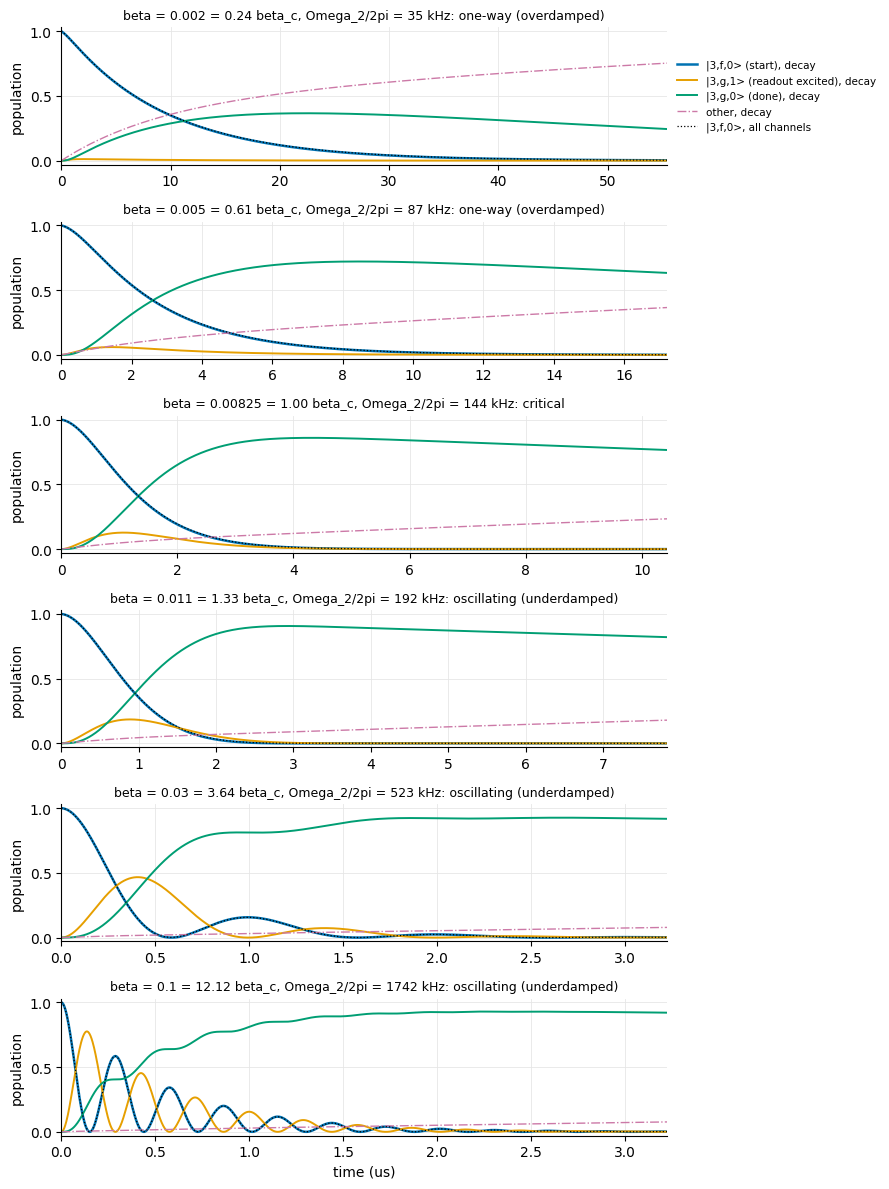

In [31]:
fig, axes = plt.subplots(len(BETAS_SHOW_2), 1, figsize=(9, 2.0 * len(BETAS_SHOW_2)), sharey=True)
for ax, beta in zip(axes, BETAS_SHOW_2):
    tr = traces2[beta]
    t, P, Pall = tr["t"], tr["decay"], tr["all"]
    ax.plot(t, P[:, k0], color="#0072B2", lw=1.8, label="|3,f,0> (start), decay")
    ax.plot(t, P[:, k1], color="#E69F00", lw=1.4, label="|3,g,1> (readout excited), decay")
    ax.plot(t, P[:, k_done], color="#009E73", lw=1.4, label="|3,g,0> (done), decay")
    ax.plot(t, 1 - P[:, [k0, k1, k_done]].sum(axis=1), color="#CC79A7", lw=1.0, ls="-.", label="other, decay")
    ax.plot(t, Pall[:, k0], color="k", lw=0.9, ls=":", label="|3,f,0>, all channels")
    regime = "one-way (overdamped)" if beta < BETA_CRIT_2 * (1 - 1e-9) else (
        "critical" if np.isclose(beta, BETA_CRIT_2) else "oscillating (underdamped)")
    ax.set_title(f"beta = {beta:.4g} = {beta / BETA_CRIT_2:.2f} beta_c, Omega_2/2pi = "
                 f"{1e3 * mhz(omega_2(beta)):.0f} kHz: {regime}", fontsize=9)
    ax.set_xlim(0, t[-1])
    ax.set_ylim(-0.03, 1.03)
    ax.set_ylabel("population")
    tidy(ax)
axes[-1].set_xlabel("time (us)")
axes[0].legend(fontsize=7.5, frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))
fig.tight_layout()
fig.savefig("figures/fwm_tuning_comb2_traces.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 8.** The comb-2 step from $|3,f,0\rangle$, one row per pump strength (title: $\beta$ in units of $\beta_c$, the
rate, and the regime). Blue: $|3,f,0\rangle$, the start. Orange: $|3,g,1\rangle$, the readout holding the photon.
Green: $|3,g,0\rangle$, done. Pink dash-dot: everything else (photon loss and $f\to e$ decay). Black dotted:
$|3,f,0\rangle$ with all channels, on top of the blue line in every row. The time axis differs per row.

- **Rows 1–3 ($\beta \le \beta_c$): one-way.** Blue only falls. Orange stays small (at most 0.13 at $\beta_c$), because
  the readout empties faster than the pump fills it. Backflow is exactly 0 (Table 17).
- **The cost of a weak pump is time.** At $\beta = 0.002$ the step takes tens of μs, and the transmon's own
  $T_{1,ef} = 31$ μs competes with it: only 0.48 of the population goes through the readout; the rest decays to
  $|e\rangle$ or loses a photon first (pink). At $\beta_c$ the yield is 0.92.
- **Row 4, the paper's $\beta$ ($1.33\,\beta_c$):** formally oscillating, but the first return comes so late that it is
  invisible: backflow $6.5\times10^{-4}$, yield 0.947.
- **Rows 5–6: clearly oscillating.** At $\beta = 0.03$, 0.16 of the population returns to $|3,f,0\rangle$ after the first
  dip; at $\beta = 0.1$, 0.59. The step does not get faster (the envelope is fixed at $\kappa_r/2$), and $|3,g,0\rangle$
  fills in steps, once per swing.
- **All channels change nothing visible:** the black dotted line sits on the blue one.

**The same, over all pump strengths.** The cell below runs the decay-only, compensated simulation at 41 values of
$\beta$ from $10^{-3}$ to 0.1 and plots $P_{3f0}$ against $\beta$ and time, in units of $1/\kappa_r$. Panel (b) shows the
same data on a log colour scale, which makes every zero of $P_{3f0}$ a dark mark: each zero is a moment the population
has fully swung over to $|3,g,1\rangle$, after which part of it comes back.

map vs the 2x2 pair: largest difference 9.8e-09


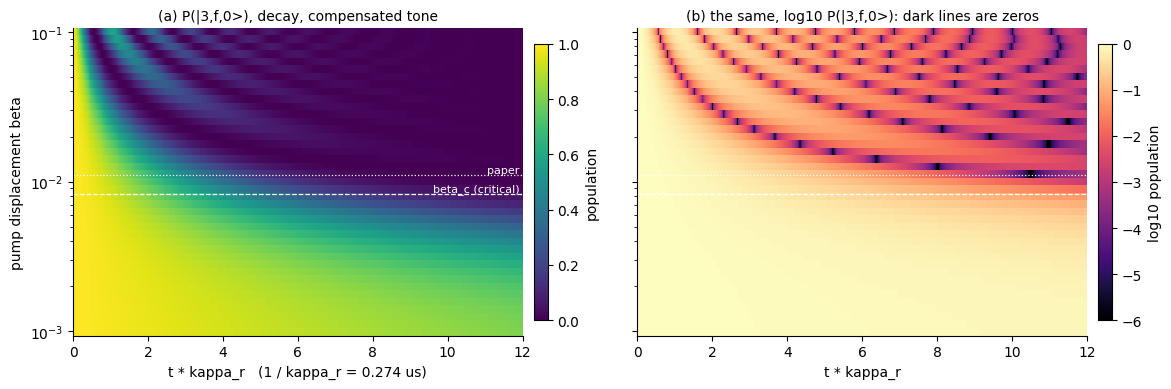

first beta with backflow > 1e-6: 0.01122 (beta_c = 0.00825)


In [32]:
BETAS_MAP_2 = np.geomspace(1e-3, 0.1, 41)
X_MAP_2 = np.linspace(0, 12, 481)                     # time in units of 1 / kappa_r
map2 = np.array([populations(simulate_open(beta, rho_basis(k0, m2.d), X_MAP_2 / dev.kappa_r, m2,
                                           compensate=True))[:, k0] for beta in BETAS_MAP_2])
map2_closed = np.array([pair_populations(beta, X_MAP_2 / dev.kappa_r, compensate=True)[0] for beta in BETAS_MAP_2])
print(f"map vs the 2x2 pair: largest difference {np.abs(map2 - map2_closed).max():.1e}")
assert np.abs(map2 - map2_closed).max() < 1e-7

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
ax = axes[0]
im = ax.pcolormesh(X_MAP_2, BETAS_MAP_2, map2, shading="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_yscale("log")
for b, ls, lab in ((BETA_CRIT_2, "--", "beta_c (critical)"), (BETA_PAPER_2, ":", "paper")):
    ax.axhline(b, color="w", lw=0.9, ls=ls)
    ax.text(X_MAP_2[-1], b, lab + " ", color="w", fontsize=8, ha="right", va="bottom")
ax.set_xlabel("t * kappa_r   (1 / kappa_r = 0.274 us)")
ax.set_ylabel("pump displacement beta")
ax.set_title("(a) P(|3,f,0>), decay, compensated tone", fontsize=10)
fig.colorbar(im, ax=ax, shrink=0.9, pad=0.02, label="population")
tidy(ax, grid=False)

ax = axes[1]
im = ax.pcolormesh(X_MAP_2, BETAS_MAP_2, np.log10(np.clip(map2, 1e-6, None)), shading="auto", cmap="magma",
                   vmin=-6, vmax=0)
ax.set_yscale("log")
for b, ls in ((BETA_CRIT_2, "--"), (BETA_PAPER_2, ":")):
    ax.axhline(b, color="w", lw=0.9, ls=ls)
ax.set_xlabel("t * kappa_r")
ax.set_title("(b) the same, log10 P(|3,f,0>): dark lines are zeros", fontsize=10)
fig.colorbar(im, ax=ax, shrink=0.9, pad=0.02, label="log10 population")
tidy(ax, grid=False)
fig.tight_layout()
fig.savefig("figures/fwm_tuning_comb2_map.png", dpi=150, bbox_inches="tight")
plt.show()
bf = np.array([backflow(p) for p in map2])
b_lo = BETAS_MAP_2[bf > 1e-6]
print(f"first beta with backflow > 1e-6: {b_lo.min():.5f} (beta_c = {BETA_CRIT_2:.5f})")

**Figure 9.** $P(|3,f,0\rangle)$ against time (in units of $1/\kappa_r$ = 0.274 μs) and pump strength, decay only,
compensated tone, start $|3,f,0\rangle$. Dashed white: $\beta_c$. Dotted white: the paper's $\beta$.

- **(a)** Below $\beta_c$ the colour fades smoothly from yellow to dark: a one-way drain, slower further down. Above
  $\beta_c$ bands appear: the population swings back and forth. The drain also stops getting faster above $\beta_c$
  (the dark region's left edge stops moving).
- **(b)** On a log scale the zeros of $P_{3f0}$ are the dark marks. There are none below $\beta_c$. Just above it the
  first zero sits at very late times, where little population is left, and it moves earlier as $\beta$ grows. The
  first zero inside the plotted window appears at $\beta \approx 0.011$, the paper's value. The map agrees with the
  2×2 solution to $10^{-8}$.

## 10.4 Which photon numbers the tone acts on: the Fock ladder

As in §7.2, start in every photon number at once, now with the transmon in $|f\rangle$:

$$
|\psi_0\rangle = \frac{1}{\sqrt{10}}\sum_{n=1}^{10} |n\rangle\otimes|f,0\rangle ,
$$

paper's $\beta$, compensated, decay only, $n_c$ = `N_C_LADDER` = 14, for 60 μs on a log time axis (the tuned row is done
in about 3 μs, $T_{1,ef}$ acts on 31 μs). We split the photon-number distribution by transmon level:
$P(n, f)$ and $P(n, g)$, summed over the readout. Panel (c) subtracts the same run with the tone off ($\beta = 0$), so
it shows only what the tone does. A rerun at $n_c$ = 16 checks the truncation.

truncation: max |P(n, j)| difference, n_c = 14 vs 16: 6.6e-10


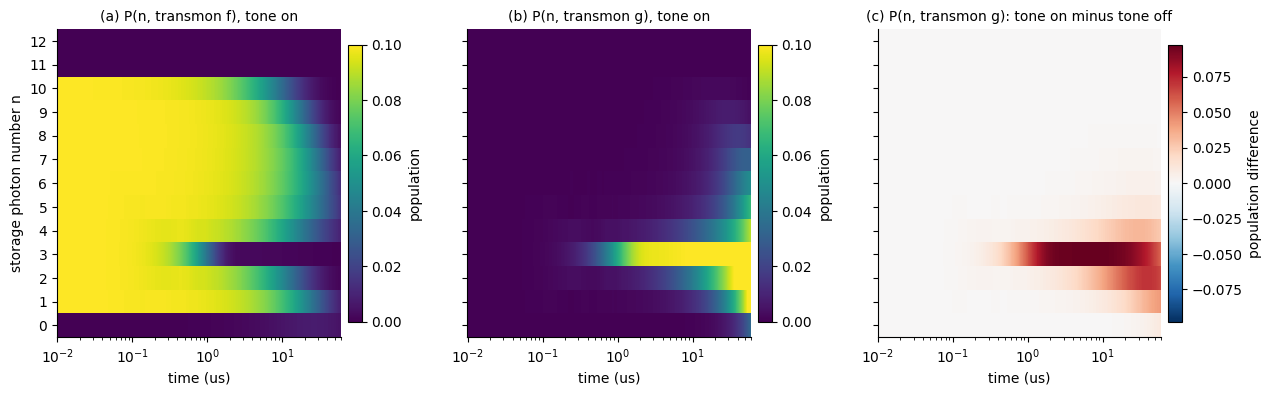

t =  1.01 us: extra P(n, g) from the tone, n = 1..5: +0.0012, +0.0048, +0.0617, +0.0042, +0.0012
t =  3.01 us: extra P(n, g) from the tone, n = 1..5: +0.0029, +0.0138, +0.0967, +0.0095, +0.0026
t = 10.05 us: extra P(n, g) from the tone, n = 1..5: +0.0096, +0.0386, +0.0975, +0.0221, +0.0064
t = 60.00 us: extra P(n, g) from the tone, n = 1..5: +0.0421, +0.0644, +0.0559, +0.0249, +0.0090


In [33]:
t_lad2 = np.concatenate([[0.0], np.geomspace(0.01, T_OPEN, 600)])   # log-spaced: the tuned row is done in ~3 us


def ladder_start_f(n_c):
    # (|1> + ... + |10>)/sqrt10 (x) |f,0>: every photon number waiting for its comb-2 tone
    psi = np.zeros(dim(n_c, N_R), dtype=complex)
    for n in LADDER_FOCK:
        psi[index(n, F, 0, n_c, N_R)] = 1.0
    psi /= np.linalg.norm(psi)
    return np.outer(psi, psi.conj())


def fock_by_level(rhos, n_c):
    # P(n, j)(t): storage photon number n with the transmon in level j, summed over the readout; (len(t), n_c, 3)
    return populations(rhos).reshape(len(rhos), n_c, 3, N_R).sum(axis=-1)


MODEL2_LAD = open_model_comb2(N_C_LADDER, "decay")
lad2 = {name: fock_by_level(simulate_open(beta, ladder_start_f(N_C_LADDER), t_lad2, MODEL2_LAD, compensate=True),
                            N_C_LADDER)
        for name, beta in (("on", BETA_PAPER_2), ("off", 0.0))}

# Truncation: the same run at n_c = 16
lad2_16 = fock_by_level(simulate_open(BETA_PAPER_2, ladder_start_f(16), t_lad2, open_model_comb2(16, "decay"),
                                      compensate=True), 16)
print(f"truncation: max |P(n, j)| difference, n_c = {N_C_LADDER} vs 16: "
      f"{np.abs(lad2['on'] - lad2_16[:, :N_C_LADDER]).max():.1e}")

n_show = N_C_LADDER - 1
fock_axis = np.arange(n_show)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
panels = ((lad2["on"][:, :n_show, F], "(a) P(n, transmon f), tone on", "viridis", (0, 0.1)),
          (lad2["on"][:, :n_show, G], "(b) P(n, transmon g), tone on", "viridis", (0, 0.1)))
for ax, (Z, title, cmap, (lo, hi)) in zip(axes, panels):
    im = ax.pcolormesh(t_lad2[1:], fock_axis, Z[1:].T, shading="auto", cmap=cmap, vmin=lo, vmax=hi)
    ax.set_title(title, fontsize=10)
    fig.colorbar(im, ax=ax, shrink=0.9, pad=0.02, label="population")
dPg = (lad2["on"] - lad2["off"])[:, :n_show, G]
lim = np.abs(dPg).max()
im = axes[2].pcolormesh(t_lad2[1:], fock_axis, dPg[1:].T, shading="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
axes[2].set_title("(c) P(n, transmon g): tone on minus tone off", fontsize=10)
fig.colorbar(im, ax=axes[2], shrink=0.9, pad=0.02, label="population difference")
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("time (us)")
    ax.set_yticks(fock_axis)
    tidy(ax, grid=False)
axes[0].set_ylabel("storage photon number n")
fig.savefig("figures/fwm_tuning_comb2_fock.png", dpi=150, bbox_inches="tight")
plt.show()

for tt in (1.0, 3.0, 10.0, T_OPEN):
    k = np.searchsorted(t_lad2, tt)
    print(f"t = {t_lad2[k]:5.2f} us: extra P(n, g) from the tone, n = 1..5: "
          + ", ".join(f"{dPg[k, n]:+.4f}" for n in range(1, 6)))

**Figure 10.** Photon-number distribution from $(|1\rangle + \dots + |10\rangle)/\sqrt{10}\otimes|f,0\rangle$, comb-2
tone on $n = 3$, paper's $\beta$, decay only. Log time axis.

- **(a) Transmon in $f$.** Row 3 empties within about 2 μs; every other row only fades slowly ($T_{1,ef}$ and photon
  loss, faster for high $n$). The tone picks out one photon number.
- **(b) Transmon in $g$.** Row 3 fills to its full 0.1 within 3 μs: a one-way move, no stripes (compare the stripes of
  the comb-1 swap in Fig. 5). Rows 2 and 4 fill more slowly. Later all rows gain $g$ population as $f$ decays through
  $e$ to $g$.
- **(c) Tone on minus tone off** shows the tone's effect alone. Row 3 gains 0.097 by 3 μs. Rows 2 and 4 gain 0.014 and
  0.010 by 3 μs, 0.039 and 0.022 by 10 μs: the tone also pulls the neighbouring photon numbers out of $f$, slowly, and
  this does not stop (§10.5–§10.6). Part of row 2's later gain (and row 1's, at 60 μs) is not crosstalk but row 3's
  corrected population losing photons: $|3,g,0\rangle \to |2,g,0\rangle \to \dots$

## 10.5 Sweep over the pump strength

**What is run.** 34 pump strengths, log-spaced from $10^{-3}$ to 0.3. For each, start in $|3,f,0\rangle$ and run for
ten slow decay times (the leftover is $e^{-10}$), with decay only (bare and compensated tone) and all channels
(compensated). Then start in each neighbour, $|2,f,0\rangle$ and $|4,f,0\rangle$ (decay only, compensated).

**What is measured.**

| quantity | definition | good value |
|---|---|---|
| yield | $\kappa_r\int P(\lvert 3,g,1\rangle)\,dt$: the share of the population that leaves through the readout into $\lvert 3,g,0\rangle$. Photon loss *after* arrival is not the tone's doing, so it is not counted | $\ge 0.9$ |
| backflow | largest rise of $P(\lvert 3,f,0\rangle)$ above its lowest value so far: how much comes back. 0 exactly for a one-way step | $\le 0.01$ |
| $t_{99}$ | the time after which $P(\lvert 3,f,0\rangle)$ stays below 0.01: how long the step takes | short |
| crosstalk | population the tone moves out of $\lvert 2,f,0\rangle$ or $\lvert 4,f,0\rangle$ by $t_{99}$ of the tuned path: tone off ($e^{-\Gamma_f t}$, exact for the decay set) minus tone on; the larger of the two | $\le 0.1$ |

The yield and backflow thresholds play the roles of the contrast and crosstalk thresholds of §6 and §7.3.

**Why crosstalk is measured at a fixed time.** A neighbour $|n',f,0\rangle$ is detuned from the tone by
$w \approx \pm\chi_{gf}$. In the closed comb-1 problem a detuned path only wobbles and returns (§5). Here the
partner $|n',g,1\rangle$ leaks at $\Gamma_g$, so the neighbour is drained irreversibly, at

$$
\Gamma_{\rm xt} \approx \frac{\Omega_2^2\,\Gamma_g}{w^2 + \Gamma_g^2/4}
$$

(eliminating $|n',g,1\rangle$ from the 2×2 problem), about $1/50$ of the tuned rate. It never stops, so the number
depends on how long the tone stays on. We take the time the tuned path needs, $t_{99}$. The dashed lines in Fig. 11 use
this rate.

In [34]:
BETAS_2 = np.geomspace(1e-3, 0.3, 34)
OPEN_RUNS_2 = (("decay", False), ("decay", True), ("all", True))   # (channels, compensate)
XT_STARTS_2 = {2: index(2, F, 0, N_C, N_R), 4: index(4, F, 0, N_C, N_R)}   # neighbours chi_gf below / above
BACKFLOW_MAX = 0.01                                                # "one-way": at most 1% comes back


def settle_time(t, p, level=0.01):
    # last time p(t) is above `level` (after it, p stays below), linear between samples; nan if never settles
    k = np.flatnonzero(p > level)
    if not len(k) or k[-1] == len(p) - 1:
        return np.nan
    k = k[-1]
    return t[k] + (p[k] - level) / (p[k] - p[k + 1]) * (t[k + 1] - t[k])


def xt_estimate(beta, start, t):
    # population the tone moves off the off-resonant |n',f,0> by time t: adiabatic elimination of |n',g,1>,
    # rate Omega_2^2 Gamma_g / (w^2 + Gamma_g^2 / 4), w = its detuning from the tone (compensated)
    M = pair_matrix(beta, m2, start, compensate=True)
    Om, w, Gg = abs(M[0, 1]), -M[1, 1].imag, -2 * M[1, 1].real
    rate = Om ** 2 * Gg / (w ** 2 + Gg ** 2 / 4)
    return np.exp(-m2.gdiag[start] * t) * (1 - np.exp(-rate * t))


records2 = []
for beta in BETAS_2:
    t = np.linspace(0, max(10 / slow_rate(beta), 3 * np.pi / omega_2(beta)), 2001)   # 10 decay times: the tail is e^-10
    rec = {"beta": beta}
    for ch, comp in OPEN_RUNS_2:
        P = populations(simulate_open(beta, rho_basis(k0, m2.d), t, MODEL2[ch], compensate=comp))
        run = f"{ch}, {'compensated' if comp else 'bare'}"
        rec[f"yield, {run}"] = dev.kappa_r * trapezoid(P[:, k1], t)   # share that leaves through the readout
        rec[f"largest P(|3,g,0>), {run}"] = P[:, k_done].max()
        rec[f"backflow, {run}"] = backflow(P[:, k0])
        rec[f"t99, {run}"] = settle_time(t, P[:, k0])
    rec["efficiency (2x2)"] = efficiency(beta)
    rec["t99 estimate"] = np.log(100) / slow_rate(beta)
    t99 = rec["t99, decay, compensated"]
    for n, s in XT_STARTS_2.items():
        # without the tone, |n',f,0> only decays, exp(-Gamma t): nothing jumps back into it (decay set)
        P = populations(simulate_open(beta, rho_basis(s, m2.d), t, m2, compensate=True))[:, s]
        rec[f"xt |{n},f,0>"] = np.interp(t99, t, np.exp(-m2.gdiag[s] * t) - P)
        rec[f"xt |{n},f,0> (estimate)"] = xt_estimate(beta, s, t99)
    rec["crosstalk"] = max(rec[f"xt |{n},f,0>"] for n in XT_STARTS_2)
    records2.append(rec)
sweep2 = pd.DataFrame(records2)
print(f"{len(BETAS_2) * (len(OPEN_RUNS_2) + len(XT_STARTS_2))} open runs")

170 open runs


,beta low (yield = 0.9),beta high (backflow = 0.01),beta high (crosstalk = 0.1),Omega_2/2pi low (kHz),Omega_2/2pi high (kHz),largest yield,at beta,yield at paper's beta,backflow at paper's beta
run,,,,,,,,,
"decay, bare",0.006914,0.0167,0.01389,120.4,242,0.9639,0.02245,0.9452,0
"decay, compensated",0.006885,0.01403,0.01389,119.9,242,0.9794,0.3,0.9467,0.0008063
"all, compensated",0.006918,0.0143,0.01389,120.5,242,0.9791,0.3,0.9463,0.0002939


at the paper's beta: t99, decay, bare 2.802, t99, decay, compensated 2.315, t99, all, compensated 2.363, t99 estimate 2.475, xt |2,f,0> 0.07309, xt |2,f,0> (estimate) 0.06164, xt |4,f,0> 0.07089, xt |4,f,0> (estimate) 0.06001
largest |crosstalk - estimate| for beta <= 0.03: 0.025776995004727327
largest relative gap, t99 (decay, compensated) vs ln(100) / slow rate: 0.34837737935583557
yield (decay, compensated) vs the 2x2 efficiency: largest difference 7.0e-05


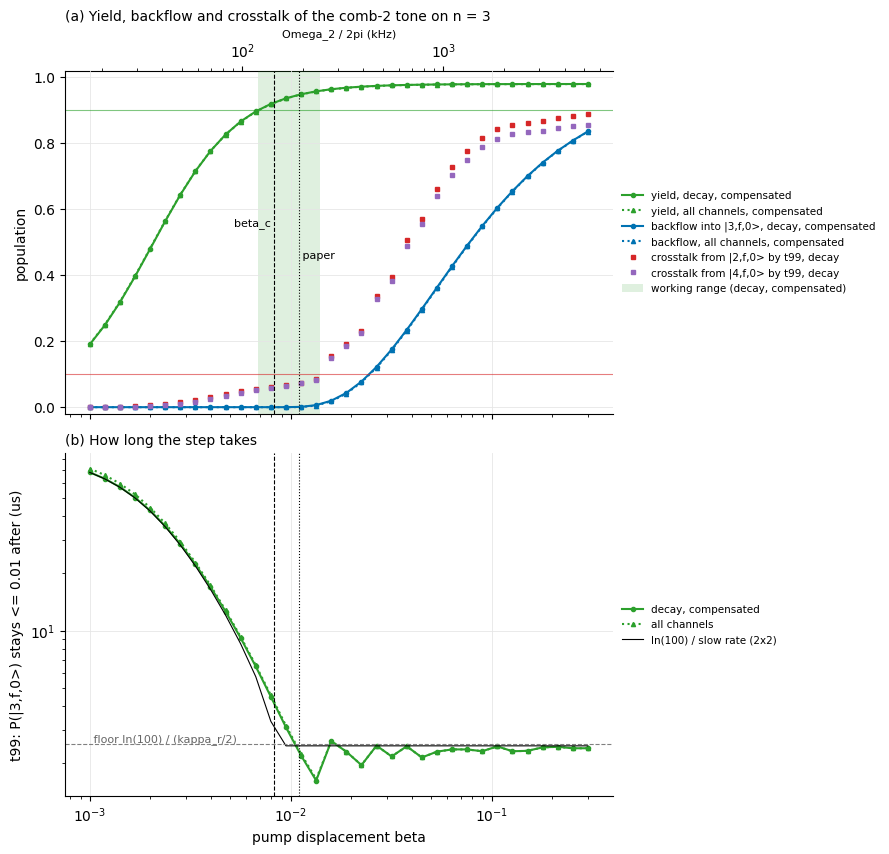

In [35]:
rows = []
for run in ("decay, bare", "decay, compensated", "all, compensated"):
    y, bfl = sweep2[f"yield, {run}"], sweep2[f"backflow, {run}"]
    lo = crossing(sweep2.beta, y, CONTRAST_MIN)
    hi_b = crossing(sweep2.beta, bfl, BACKFLOW_MAX)
    hi_x = crossing(sweep2.beta, sweep2["crosstalk"], XT_MAX)
    hi = np.nanmin([hi_b, hi_x])
    rows.append({"run": run, "beta low (yield = 0.9)": lo,
                 f"beta high (backflow = {BACKFLOW_MAX})": hi_b, f"beta high (crosstalk = {XT_MAX})": hi_x,
                 "Omega_2/2pi low (kHz)": 1e3 * mhz(omega_2(lo)), "Omega_2/2pi high (kHz)": 1e3 * mhz(omega_2(hi)),
                 "largest yield": y.max(), "at beta": sweep2.beta[y.idxmax()],
                 "yield at paper's beta": np.interp(np.log(BETA_PAPER_2), np.log(sweep2.beta), y),
                 "backflow at paper's beta": np.interp(np.log(BETA_PAPER_2), np.log(sweep2.beta), bfl)})
range_table2 = pd.DataFrame(rows).set_index("run")
display(range_table2.style.format({c: "{:.4g}" for c in range_table2.columns}).set_caption(
    f"Table 18. Pump range of a clean comb-2 step: yield >= {CONTRAST_MIN}, backflow <= {BACKFLOW_MAX} and "
    f"crosstalk <= {XT_MAX}. Edges interpolated between swept betas (linear in log beta). The crosstalk column is the "
    "decay-set, compensated value for every row. Last four columns: the best swept point and the paper's beta."))
at_paper = {c: np.interp(np.log(BETA_PAPER_2), np.log(sweep2.beta), sweep2[c]) for c in sweep2.columns
            if c.startswith("xt") or c.startswith("t99")}
print("at the paper's beta: " + ", ".join(f"{c} {v:.4g}" for c, v in at_paper.items()))
print("largest |crosstalk - estimate| for beta <= 0.03:", max(np.abs(sweep2[f"xt |{n},f,0>"] - sweep2[f"xt |{n},f,0> (estimate)"])
                                                   [sweep2.beta <= 0.03].max() for n in XT_STARTS_2))
print("largest relative gap, t99 (decay, compensated) vs ln(100) / slow rate:",
      np.nanmax(np.abs(sweep2["t99, decay, compensated"] / sweep2["t99 estimate"] - 1)))
err_eff = np.abs(sweep2["efficiency (2x2)"] - sweep2["yield, decay, compensated"]).max()
print(f"yield (decay, compensated) vs the 2x2 efficiency: largest difference {err_eff:.1e}")
assert err_eff < 1e-4

fig, axes = plt.subplots(2, 1, figsize=(9, 8.6), sharex=True)
ax = axes[0]
ax.plot(sweep2.beta, sweep2["yield, decay, compensated"], color="C2", marker="o", ms=3,
        label="yield, decay, compensated")
ax.plot(sweep2.beta, sweep2["yield, all, compensated"], color="C2", ls=":", marker="^", ms=3,
        label="yield, all channels, compensated")
ax.plot(sweep2.beta, sweep2["backflow, decay, compensated"], color="#0072B2", marker="o", ms=3,
        label="backflow into |3,f,0>, decay, compensated")
ax.plot(sweep2.beta, sweep2["backflow, all, compensated"], color="#0072B2", ls=":", marker="^", ms=3,
        label="backflow, all channels, compensated")
for n, c in zip(XT_STARTS_2, ("C3", "C4")):
    ax.plot(sweep2.beta, sweep2[f"xt |{n},f,0>"], color=c, marker="s", ms=3, ls="none",
            label=f"crosstalk from |{n},f,0> by t99, decay")
r = range_table2.loc["decay, compensated"]
lo, hi = r["beta low (yield = 0.9)"], np.nanmin([r[f"beta high (backflow = {BACKFLOW_MAX})"],
                                                 r[f"beta high (crosstalk = {XT_MAX})"]])
if lo < hi:
    ax.axvspan(lo, hi, color="C2", alpha=0.15, lw=0, label="working range (decay, compensated)")
ax.axhline(CONTRAST_MIN, color="C2", lw=0.8, alpha=0.6)
ax.axhline(XT_MAX, color="C3", lw=0.8, alpha=0.6)
ax.set_ylim(-0.02, 1.02)
ax.set_ylabel("population")
ax.set_title("(a) Yield, backflow and crosstalk of the comb-2 tone on n = 3", fontsize=10, loc="left")
ax.legend(fontsize=7.5, frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))
top = ax.secondary_xaxis("top", functions=(lambda b: 1e3 * mhz(omega_2(b)), lambda o: o / (1e3 * mhz(omega_2(1.0)))))
top.set_xlabel("Omega_2 / 2pi (kHz)", fontsize=8)

ax = axes[1]
ax.plot(sweep2.beta, sweep2["t99, decay, compensated"], color="C2", marker="o", ms=3, label="decay, compensated")
ax.plot(sweep2.beta, sweep2["t99, all, compensated"], color="C2", ls=":", marker="^", ms=3, label="all channels")
ax.plot(sweep2.beta, sweep2["t99 estimate"], color="k", lw=0.8, label="ln(100) / slow rate (2x2)")
ax.axhline(np.log(100) / (dev.kappa_r / 2), color="0.5", lw=0.8, ls="--")
ax.text(sweep2.beta.min(), np.log(100) / (dev.kappa_r / 2), " floor ln(100) / (kappa_r/2)", fontsize=8,
        color="0.4", va="bottom")
ax.set_yscale("log")
ax.set_ylabel("t99: P(|3,f,0>) stays <= 0.01 after (us)")
ax.set_xlabel("pump displacement beta")
ax.set_title("(b) How long the step takes", fontsize=10, loc="left")
ax.legend(fontsize=7.5, frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))
for ax in axes:
    ax.set_xscale("log")
    ax.axvline(BETA_CRIT_2, color="k", lw=0.8, ls="--")
    ax.axvline(BETA_PAPER_2, color="k", lw=0.8, ls=":")
    tidy(ax)
axes[0].text(BETA_CRIT_2, 0.55, "beta_c ", fontsize=8, ha="right")
axes[0].text(BETA_PAPER_2, 0.45, " paper", fontsize=8)
fig.tight_layout()
fig.savefig("figures/fwm_tuning_comb2_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 11.** Comb-2 tone on $n = 3$ against pump strength; top axis $\Omega_2/2\pi$. Dashed vertical: $\beta_c$. Dotted
vertical: the paper's $\beta$. Every curve uses the compensated tone; circles are decay only, triangles all channels.

- **(a)** Green: yield. Blue: backflow. Red and purple squares: crosstalk from $|2,f,0\rangle$ and $|4,f,0\rangle$.
  Shaded: the working range of Table 18.
- **(b)** $t_{99}$, with the estimate $\ln(100)/\text{slow rate}$ (thin black) and its floor $\ln(100)/(\kappa_r/2)$
  (grey dashed).

**How each quantity is calculated.** Each run starts in $|3,f,0\rangle$ and lasts 10 slow time constants
($10/\text{slow rate}$), so less than $e^{-10}$ of the step is cut off.

- **Yield:** $\kappa_r\int P(|3,g,1\rangle)\,dt$ over the run, the total that leaked out of the readout into
  $|3,g,0\rangle$.
- **Backflow:** the largest rise of $P_{3f0}(t)$ above the lowest value it has had so far.
- **$t_{99}$:** the last time $P_{3f0}$ is above 0.01, read between time samples by linear interpolation.
- **Crosstalk by $t_{99}$:** a second run, same tone, starting in a neighbour $|n',f,0\rangle$ ($n' = 2$ or 4). With the
  tone off this state would only decay, as $e^{-\Gamma t}$ (nothing jumps back into it). Crosstalk is
  $e^{-\Gamma t} - P(|n',f,0\rangle)$ at $t = t_{99}$ of the tuned path: what the tone moved off the neighbour while the
  tuned step finished. Table 18 uses the larger of the two neighbours.
- **The estimate in (b):** at late times $P_{3f0} \approx e^{-\text{rate}\cdot t}$ (the slow rate of Table 17). Setting
  this equal to 0.01 gives $t = \ln(100)/\text{rate}$. It ignores the prefactor in front of the exponential and, above
  $\beta_c$, the swings. For $\beta \le 0.004$ it is within 3% of the simulated $t_{99}$. Near $\beta_c$ it is short
  by up to 35% (3.3 μs against 4.5 μs at $\beta = 0.008$), because the slow and fast parts merge and the prefactor
  grows with time. Above $\beta_c$ the rate is stuck at $(\Gamma_f+\Gamma_g)/2 \approx \kappa_r/2$, so the estimate
  sits on the floor $\ln(100)/(\kappa_r/2) = 2.5$ μs. The simulated $t_{99}$ scatters around and mostly below it
  (1.6 to 2.6 μs; 2.3 μs at the paper's $\beta$), depending on where in a swing $P_{3f0}$ last crosses 0.01.

**Reading Fig. 11**

- **The low end is set by $T_{1,ef}$.** A weak pump is one-way but slow, and $|f\rangle$ decays before the tone moves
  it. Yield reaches 0.9 at $\beta = 0.0069$ ($\Omega_2/2\pi$ = 120 kHz), a little below $\beta_c$.
- **The high end is set by crosstalk and backflow, almost together.** Crosstalk reaches 0.1 at $\beta = 0.0139$
  (242 kHz); backflow reaches 0.01 at 0.0140. So the working range is $\beta \approx 0.0069$–0.0139, a factor 2.0,
  much narrower than comb 1's factor 3.7 (Table 14). **The paper's $\beta$ sits inside**, near the middle: yield 0.947,
  backflow $8\times10^{-4}$, crosstalk 0.073 (from $|2,f,0\rangle$) and 0.071 (from $|4,f,0\rangle$).
- **Above $\beta_c$ a harder pump buys almost nothing.** $t_{99}$ falls steeply up to $\beta_c$ (43 μs at
  $\beta = 0.002$, 4.2 μs at $\beta_c$, 2.3 μs at the paper's $\beta$) and then sits near the floor $\ln(100)/(\kappa_r/2)$ =
  2.5 μs. The yield creeps from 0.95 to 0.98. Meanwhile backflow and crosstalk grow fast.
- **Crosstalk is irreversible and not small.** Even at the paper's $\beta$, 7% of a neighbour's $|f\rangle$ population
  is moved to $|g\rangle$ while the tuned path finishes. The Lorentzian rate estimate (`xt_estimate`, printed above, not plotted) gives 0.062 there; it misses the fast
  off-resonant wobble (size about $4\Omega_2^2/w^2$, a few percent), and it fails once $\Omega_2$ approaches $\chi_{gf}$
  ($\beta \gtrsim 0.03$; largest gap 0.026 for $\beta \le 0.03$).
- **All channels** change the yield by at most 0.0006 and the backflow by at most 0.0013 in the working range, and
  $t_{99}$ by under 0.1 μs: thermal heating and dephasing are slow on the few-μs scale of this step.

## 10.6 Strong pump: the tone stops choosing one photon number

**What is run.** As §8, but open (decay only, compensated) and over a fixed 4 μs (about $15/\kappa_r$): four pump
strengths, $\beta$ = 0.011, 0.03, 0.1 and 0.3. The first is the paper's value (Shirol et al., Table II:
$\beta = 0.011$, $\Omega_2/2\pi \approx 190$ kHz); at the last,
$\Omega_2 \approx 2.5\chi_{gf}$.
(a) each of $|2,f,0\rangle$, $|3,f,0\rangle$ (tuned), $|4,f,0\rangle$ started alone; (b) the superposition
$(|2\rangle + |3\rangle + |4\rangle)/\sqrt3\otimes|f,0\rangle$, integrated directly. An ideal, perfectly selective tone would
empty only the $n = 3$ third and leave the other two thirds to decay at their own slow rate; that is the grey dashed
reference.

beta,Omega_2/2pi (MHz),Omega_2 / chi_gf,"yield, n = 3 (largest P(|3,g,0>))","backflow, n = 3","moved off |2,f,0> by 4 us","moved off |4,f,0> by 4 us","largest |P_f - ideal|, superposition",Stark 2 alpha beta^2 / alpha
0.011,0.192,0.0926,0.907,0.00065,0.105,0.0993,0.0411,0.000242
0.03,0.523,0.252,0.927,0.157,0.484,0.457,0.302,0.0018
0.1,1.74,0.842,0.929,0.585,0.815,0.768,0.546,0.02
0.3,5.23,2.52,0.929,0.836,0.828,0.781,0.64,0.18


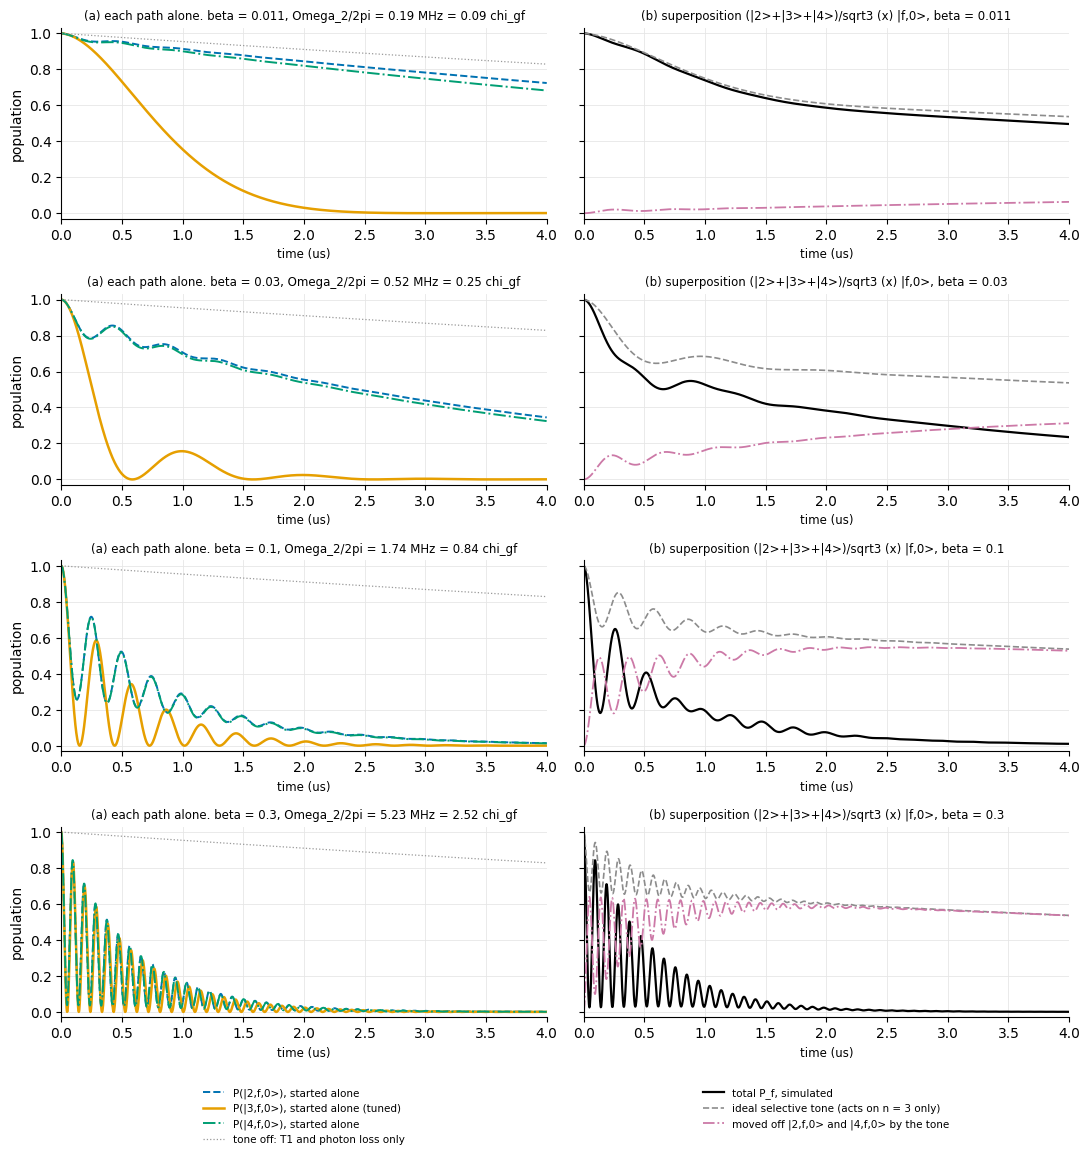

In [36]:
STRONG_BETAS_2 = [BETA_PAPER_2, 0.03, 0.1, 0.3]
T_STRONG_2 = 4.0                                      # us, the same window in every row (about 15 / kappa_r)
PATHS_2 = {n: index(n, F, 0, N_C, N_R) for n in (2, 3, 4)}   # |n,f,0>; the tone is tuned to n = 3
IN_F2 = J_OF == F
psi_sup2 = np.zeros(m2.d, dtype=complex)
psi_sup2[list(PATHS_2.values())] = 1 / np.sqrt(3)     # (|2> + |3> + |4>)/sqrt3 (x) |f,0>
rho_sup2 = np.outer(psi_sup2, psi_sup2.conj())
t_s2 = np.linspace(0, T_STRONG_2, 2001)

strong2, rows = {}, []
for beta in STRONG_BETAS_2:
    run = {n: populations(simulate_open(beta, rho_basis(s, m2.d), t_s2, m2, compensate=True))
           for n, s in PATHS_2.items()}
    P = populations(simulate_open(beta, rho_sup2, t_s2, m2, compensate=True))      # the superposition itself
    off = {n: np.exp(-m2.gdiag[s] * t_s2) for n, s in PATHS_2.items()}             # tone off: decay only
    ideal = (pair_populations(beta, t_s2, compensate=True)[0] + off[2] + off[4]) / 3  # tone acts on n = 3 only
    strong2[beta] = dict(run=run, P=P, off=off, ideal=ideal)
    rows.append({"beta": beta, "Omega_2/2pi (MHz)": mhz(omega_2(beta)),
                 "Omega_2 / chi_gf": omega_2(beta) / dev.chi_gf,
                 "yield, n = 3 (largest P(|3,g,0>))": run[3][:, k_done].max(),
                 "backflow, n = 3": backflow(run[3][:, k0]),
                 "moved off |2,f,0> by 4 us": off[2][-1] - run[2][-1, PATHS_2[2]],
                 "moved off |4,f,0> by 4 us": off[4][-1] - run[4][-1, PATHS_2[4]],
                 "largest |P_f - ideal|, superposition": np.abs(P[:, IN_F2].sum(axis=1) - ideal).max(),
                 "Stark 2 alpha beta^2 / alpha": 2 * beta ** 2})
strong_table2 = pd.DataFrame(rows)
display(strong_table2.style.hide(axis="index").format("{:.3g}").set_caption(
    "Table 19. Strong pump, comb-2 tone on n = 3, compensated, decay set, over 4 us. Yield and backflow of the tuned "
    "path; population the tone moves off each neighbour (tone off minus tone on); the superposition's largest gap from "
    "an ideal tone that acts on n = 3 only; and the Stark shift as a fraction of alpha (how far the model holds)."))

OKABE2 = {2: ("#0072B2", "--"), 3: ("#E69F00", "-"), 4: ("#009E73", "-.")}
fig, axes = plt.subplots(len(STRONG_BETAS_2), 2, figsize=(11, 2.7 * len(STRONG_BETAS_2)), sharey=True)
for row, beta in enumerate(STRONG_BETAS_2):
    s = strong2[beta]
    ax = axes[row, 0]
    for n, start in PATHS_2.items():
        c, ls = OKABE2[n]
        ax.plot(t_s2, s["run"][n][:, start], color=c, ls=ls, lw=1.8 if n == N_PATH_2 else 1.4,
                label=f"P(|{n},f,0>), started alone" + (" (tuned)" if n == N_PATH_2 else ""))
    ax.plot(t_s2, s["off"][2], color="0.6", lw=0.9, ls=":", label="tone off: T1 and photon loss only")
    ax.set_ylabel("population")
    ax.set_title(f"(a) each path alone. beta = {beta:g}, Omega_2/2pi = {mhz(omega_2(beta)):.2f} MHz "
                 f"= {omega_2(beta) / dev.chi_gf:.2f} chi_gf", fontsize=8.5)
    ax = axes[row, 1]
    P = s["P"]
    ax.plot(t_s2, P[:, IN_F2].sum(axis=1), color="k", lw=1.6, label="total P_f, simulated")
    ax.plot(t_s2, s["ideal"], color="0.55", lw=1.2, ls="--", label="ideal selective tone (acts on n = 3 only)")
    lost = (s["off"][2] + s["off"][4]) / 3 - P[:, PATHS_2[2]] - P[:, PATHS_2[4]]
    ax.plot(t_s2, lost, color="#CC79A7", lw=1.3, ls="-.", label="moved off |2,f,0> and |4,f,0> by the tone")
    ax.set_title(f"(b) superposition (|2>+|3>+|4>)/sqrt3 (x) |f,0>, beta = {beta:g}", fontsize=8.5)
    for ax in axes[row]:
        ax.set_ylim(-0.03, 1.03)
        ax.set_xlim(0, T_STRONG_2)
        ax.set_xlabel("time (us)", fontsize=8.5)
        tidy(ax)
fig.tight_layout()
for ax in axes[-1]:
    ax.legend(fontsize=7.5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.32))
fig.savefig("figures/fwm_tuning_comb2_strong_pump.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 12.** Strong pumping, comb-2 tone on $n = 3$, compensated, decay only. One row per $\beta$: 0.011 (the
paper's value, top row), 0.03, 0.1 and 0.3. The same 4 μs window in every row.

- **(a) Each path alone:** tuned $|3,f,0\rangle$ (orange), neighbours $|2,f,0\rangle$ (blue dashed) and $|4,f,0\rangle$
  (green dash-dot). Grey dotted: $|2,f,0\rangle$ with the tone off.
- **(b) The superposition:** Black is the total $f$ population. Grey dashed is what a perfectly selective tone would give: the $n = 3$ third drains, the other two thirds only decay naturally. Pink is the population the tone pulled off $|2⟩$ and $|4⟩$. More Cross-talk lead equals fast total P_f decay. 

What it shows (Table 19):

- **At the paper's $\beta = 0.011$** (top row; $\Omega_2/2\pi$ = 0.19 MHz $= 0.09\chi_{gf}$) the tone is selective, but not perfectly: by 4 μs it has moved
  0.10 off each neighbour, and keeps going. The superposition's $P_f$ stays within 0.041 of the ideal.
- **At $\beta = 0.03$** ($0.25\chi_{gf}$) the neighbours lose about half their population in 4 μs; the tuned path shows
  its 0.16 backflow.
- **At $\beta = 0.1$ and 0.3** ($\Omega_2 \gtrsim \chi_{gf}$) the tone no longer tells photon numbers apart: all three
  paths swing and drain at nearly the same speed, and at 0.3 the three curves in (a) lie on top of each other. The
  superposition's $f$ population empties completely, so the tone acts on every photon number, which is exactly what a
  comb of separate tones is meant to avoid.
- **Different from comb 1 (Fig. 7):** there, an off-resonant path at strong pump moved population and then gave it
  back. Here the readout leak keeps what the tone took. Crosstalk accumulates instead of averaging out.
- **Trust:** the Stark shift reaches $0.18\,\alpha$ at $\beta = 0.3$, as in §8. The bottom row is qualitative.

## 10.7 Summary of comb 2

**One-way below $\beta_c$.** The comb-2 step $|3,f,0\rangle \to |3,g,1\rangle \to |3,g,0\rangle$ is one-way
(overdamped, no population returns) for $\Omega_2 < \Omega_c = (\kappa_r - \gamma_{ef})/4$, i.e. $\Omega_2/2\pi < 144$ kHz,
$\beta < \beta_c = 0.00825$ (Figs. 8–9). Above it the population swings back to $|3,f,0\rangle$ while it drains:
0.16 returns at $\beta = 0.03$, 0.59 at 0.1.

**The working range is narrow.** Yield $\ge 0.9$, backflow $\le 0.01$ and crosstalk $\le 0.1$ hold for
$\beta \approx 0.0069$ to 0.0139 ($\Omega_2/2\pi$ = 120 to 242 kHz), a factor 2 (Fig. 11, Table 18). The low end is set by
$T_{1,ef}$ (a slow step lets $|f\rangle$ decay first); the high end by crosstalk, with backflow right behind.

**The paper's $\beta = 0.011$ is a good choice.** It is $1.33\,\beta_c$, formally oscillating, but the backflow is only
$8\times10^{-4}$. Yield 0.947, step time $t_{99}$ = 2.3 μs, close to the 2.5 μs floor, $\ln(100)/(\kappa_r/2)$, that pumping harder cannot push down.

**Crosstalk is the price.** The readout leak that makes the step one-way also makes off-resonant pumping
irreversible: at the paper's $\beta$ about 7% of a neighbouring photon number's $|f\rangle$ population is moved to
$|g\rangle$ during one step, and more if the tone stays on (Figs. 10, 12). Comb-1 crosstalk, by contrast, oscillates
back (§5, §8).

**All channels** (heating, dephasing) change the yield and backflow by at most 0.0013 in the working range: the step is
too fast for them.